# Analisi del sentiment sul Bitcoin tramite tweet
**BTC-C001 · Introduzione al progetto**

**Autore:** Claudio Lombardi  
**Tecnologie principali:** Python, PySpark, Spark SQL, VADER  
**Contesto:** progetto didattico del Master in Data Analytics di ProfessionAI

## Scenario e obiettivo

Il progetto affronta uno scenario simulato di ricerca di mercato
per MarketPulse Analytics: analizzare le conversazioni su Bitcoin
per descrivere il sentiment espresso, l'engagement e le possibili
associazioni con l'andamento del prezzo.

L'analisi risponde a quattro domande:

1. Come si distribuiscono i tweet analizzati tra sentiment positivo,
   negativo e neutro?
2. Come cambiano i conteggi e le quote delle tre classi nel tempo?
3. I tweet negativi ricevono mediamente più like e risposte
   rispetto ai positivi?
4. Le variazioni giornaliere del sentiment sono associate
   ai rendimenti giornalieri BTC/USD, nello stesso giorno
   o in giorni successivi?

## Dataset e riproducibilità

Il dataset dei tweet viene scaricato dalla fonte pubblica:

https://proai-datasets.s3.eu-west-3.amazonaws.com/bitcoin_tweets.csv

L'archivio esaminato contiene 100.001 record. Per identificare
la versione utilizzata registriamo data di acquisizione,
dimensione e impronta SHA-256 del file.

Il riferimento per lo storico BTC/USD è:

https://github.com/Profession-AI/progetti-big-data/blob/main/Analisi%20del%20consenso%20sul%20Bitcoin/BTC-USD.csv

La copertura, la qualità e la convenzione temporale dei prezzi
saranno verificate prima dell'unione con i dati dei tweet.

Le celle contengono identificatori stabili, come BTC-C001,
per facilitarne la ricerca e la revisione.

## Metodo

Utilizziamo PySpark per la preparazione dei dati, l'applicazione
del classificatore e le aggregazioni.

Il sentiment viene stimato con VADER, un sistema basato su
lessico e regole. Non viene addestrato un modello supervisionato
sul dataset dei tweet.

Poiché VADER è progettato principalmente per testi inglesi,
l'analisi principale riguarda i record riconosciuti automaticamente
come inglesi. Documentiamo il numero di record selezionati,
quelli esclusi e i limiti del riconoscimento linguistico.

Per il sentiment prepariamo una versione del testo distinta
da quella utilizzata per identificare la lingua, preservando
i segnali utili alla classificazione.

Un campione annotato manualmente sarà utilizzato per valutare
le classificazioni nel dominio Bitcoin. Le annotazioni saranno
effettuate senza consultare le previsioni di VADER.
Il campione finale di valutazione non verrà utilizzato per scegliere
le soglie o modificare le regole del sistema.

## Interpretazione e limiti

Le etichette di sentiment sono stime automatiche. Il tono generale
di un messaggio può differire dall'atteggiamento espresso
specificamente verso Bitcoin: questa distinzione sarà considerata
nella valutazione manuale.

I risultati descrivono il sottoinsieme analizzato e non rappresentano
necessariamente l'opinione della popolazione o dell'intera utenza
di Twitter.

La copertura temporale è fortemente irregolare: circa il 93,12%
dei record dell'archivio completo si concentra in due giornate.
I picchi osservati possono quindi riflettere le modalità di raccolta,
oltre all'attività effettiva degli utenti.

Il progetto analizza un archivio storico e non costituisce
un sistema di monitoraggio in tempo reale.

Le associazioni tra sentiment e prezzo non saranno interpretate
come prove di causalità o, da sole, come evidenza di capacità predittiva.

In [1]:
# BTC-C002 — Verifica preliminare dell'ambiente

import sys
import platform
import shutil
import subprocess
from importlib.metadata import version, PackageNotFoundError

print("=== Ambiente di esecuzione ===")
print(f"Python: {sys.version.split()[0]}")
print(f"Sistema operativo: {platform.system()}")
print(f"Architettura: {platform.machine()}")

print("\n=== Java ===")
java_path = shutil.which("java")

if java_path is None:
    print("Java non trovato.")
else:
    result = subprocess.run(
        [java_path, "-version"],
        capture_output=True,
        text=True,
        check=False,
    )
    java_info = "\n".join(
        part.strip()
        for part in (result.stdout, result.stderr)
        if part.strip()
    )
    print(java_info or "Nessuna informazione di versione disponibile.")
    print(f"Codice di uscita: {result.returncode}")

print("\n=== PySpark ===")
try:
    print(f"Versione installata: {version('pyspark')}")
except PackageNotFoundError:
    print("PySpark non è ancora installato.")

=== Ambiente di esecuzione ===
Python: 3.13.18
Sistema operativo: Linux
Architettura: x86_64

=== Java ===
[0.015s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.015s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
Codice di uscita: 0

=== PySpark ===
Versione installata: 4.0.5


## Configurazione di Spark
**BTC-C003 · Ambiente di elaborazione**

Utilizziamo PySpark 4.0.4 nell'ambiente Google Colab.

Spark viene eseguito in modalità locale con due thread di lavoro:
l'elaborazione avviene sulla macchina assegnata da Colab, non su un
cluster composto da più macchine.

Impostiamo UTC come fuso orario della sessione, per rendere coerente
la successiva aggregazione giornaliera dei tweet e il confronto
con i prezzi.

Prima di acquisire il dataset, verifichiamo il funzionamento
con un piccolo DataFrame creato in Python e aggregato da Spark.

In [2]:
# BTC-C003A — Installazione della versione di PySpark del progetto

%pip install pyspark==4.0.4

from importlib.metadata import version

versione_pyspark_installata = version("pyspark")

assert versione_pyspark_installata == "4.0.4", (
    "La versione installata di PySpark non corrisponde "
    "a quella prevista dal progetto."
)

print("\n=== Verifica della dipendenza ===")
print(f"PySpark installato: {versione_pyspark_installata}")

# Se Spark è già avviato, controlliamo anche la versione in uso.
sessione_esistente = globals().get("spark")

if sessione_esistente is not None:
    print(f"Spark già in esecuzione: {sessione_esistente.version}")

    assert sessione_esistente.version == versione_pyspark_installata, (
        "La sessione Spark attiva usa una versione diversa. "
        "Riavviare il runtime prima di eseguire nuovamente il notebook."
    )
else:
    print("La sessione Spark sarà avviata nella cella BTC-C004.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.3/434.3 MB 28.9 MB/s  0:00:10
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyspark: filename=pyspark-4.0.4-py2.py3-none-any.whl size=434963119 sha256=054bf11bea8fedb7c056865a7874e377d46d308092c32f4e75fb99eb09fde9e1
  Stored in directory: /root/.cache/pip/wheels/16/75/45/395540a53342be5db982112af6a8aa93b4bb130bb8b8445fe4
Successfully built pyspark
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.5
    Uninstalling pyspark-4.0.5:
      Successfully uninstalled pyspark-4.0.5

=== Verifica della dipendenza ===
PySpark installato: 4.0.4
La sessione Spark sarà avviata nella cella BTC-C004.


In [3]:
# BTC-C004 — Avvio di Spark e verifica del funzionamento

import os
import sys

# I processi Python di Spark devono usare lo stesso interprete di Colab.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("BitcoinSentimentAnalysis")
    .master("local[2]")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

# Questo test verifica anche il passaggio di dati da Python a Spark.
test_df = spark.createDataFrame(
    [(1,), (2,), (3,), (4,), (5,)],
    schema="numero INT",
)

risultato = test_df.agg(
    F.count("*").alias("numero_righe"),
    F.sum("numero").alias("somma"),
).first()

assert risultato["numero_righe"] == 5, "Conteggio inatteso."
assert risultato["somma"] == 15, "Somma inattesa."

print("=== Configurazione Spark ===")
print(f"Versione Spark: {spark.version}")
print(f"Modalità di esecuzione: {spark.sparkContext.master}")
print(f"Fuso orario: {spark.conf.get('spark.sql.session.timeZone')}")
print(
    "Partizioni per gli shuffle:",
    spark.conf.get("spark.sql.shuffle.partitions"),
)

print("\n=== Test di elaborazione ===")
print(f"Righe: {risultato['numero_righe']}")
print(f"Somma: {risultato['somma']}")
print("Test completato correttamente.")

=== Configurazione Spark ===
Versione Spark: 4.0.4
Modalità di esecuzione: local[2]
Fuso orario: UTC
Partizioni per gli shuffle: 4

=== Test di elaborazione ===
Righe: 5
Somma: 15
Test completato correttamente.


## Acquisizione del dataset
**BTC-C005 · Fonte e identificazione del file**

Scarichiamo il dataset dei tweet dal collegamento pubblico fornito
da ProfessionAI, senza richiedere accesso a file personali.

Fonte:
https://proai-datasets.s3.eu-west-3.amazonaws.com/bitcoin_tweets.csv

Registriamo la data e l'ora del download in UTC, la dimensione
e l'impronta SHA-256 del file, per identificare la versione utilizzata.

Il file viene conservato nello spazio temporaneo di Google Colab.
Se il runtime viene eliminato, sarà necessario scaricarlo nuovamente.

In [4]:
# BTC-C006 — Download del dataset e registrazione della provenienza

from pathlib import Path
from urllib.request import urlopen
from datetime import datetime, timezone
import hashlib
import json

DATASET_URL = (
    "https://proai-datasets.s3.eu-west-3.amazonaws.com/"
    "bitcoin_tweets.csv"
)

DATA_DIR = Path("/content/bitcoin_sentiment/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

TWEETS_PATH = DATA_DIR / "bitcoin_tweets.csv"
TEMP_PATH = DATA_DIR / "bitcoin_tweets.csv.part"
METADATA_PATH = DATA_DIR / "bitcoin_tweets_metadata.json"

impronta = hashlib.sha256()
byte_scaricati = 0

try:
    with urlopen(DATASET_URL, timeout=60) as risposta:
        with TEMP_PATH.open("wb") as file:
            while True:
                blocco = risposta.read(1024 * 1024)

                if not blocco:
                    break

                file.write(blocco)
                impronta.update(blocco)
                byte_scaricati += len(blocco)

    if byte_scaricati == 0:
        raise ValueError("Il file scaricato è vuoto.")

    # Il nome definitivo viene assegnato solo a download completato.
    TEMP_PATH.replace(TWEETS_PATH)

except Exception:
    TEMP_PATH.unlink(missing_ok=True)
    raise

metadata = {
    "source_url": DATASET_URL,
    "download_completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "size_bytes": byte_scaricati,
    "sha256": impronta.hexdigest(),
}

METADATA_PATH.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("=== Dataset scaricato ===")
print(f"Percorso: {TWEETS_PATH}")
print(f"Dimensione: {byte_scaricati / 1_000_000:.2f} MB")
print(f"Download completato in UTC: {metadata['download_completed_at_utc']}")
print(f"SHA-256: {metadata['sha256']}")
print(f"Informazioni salvate in: {METADATA_PATH}")

=== Dataset scaricato ===
Percorso: /content/bitcoin_sentiment/data/bitcoin_tweets.csv
Dimensione: 24.71 MB
Download completato in UTC: 2026-11-07T14:26:41.707564+00:00
SHA-256: 27b2beb062c0109b010e0b1dd75adb2d124036a96897a830440d2daca57e08b9
Informazioni salvate in: /content/bitcoin_sentiment/data/bitcoin_tweets_metadata.json


In [5]:
# BTC-C006A — Verifica della versione del dataset annotato

import hashlib

TWEETS_SHA256_ATTESO = (
    "27b2beb062c0109b010e0b1dd75adb2d124036a96897a830440d2daca57e08b9"
)

impronta_verifica = hashlib.sha256()

with TWEETS_PATH.open("rb") as file_verifica:
    for blocco in iter(lambda: file_verifica.read(1024 * 1024), b""):
        impronta_verifica.update(blocco)

tweets_sha256_effettivo = impronta_verifica.hexdigest()

if tweets_sha256_effettivo != TWEETS_SHA256_ATTESO:
    raise ValueError(
        "Il dataset scaricato è diverso da quello utilizzato "
        "per le annotazioni e i risultati di questo notebook.\n"
        f"SHA-256 atteso: {TWEETS_SHA256_ATTESO}\n"
        f"SHA-256 rilevato: {tweets_sha256_effettivo}\n"
        "Interrompere l'esecuzione: non riutilizzare automaticamente "
        "le annotazioni sulla nuova versione del dataset."
    )

print("=== Verifica della versione dei tweet ===")
print(f"SHA-256: {tweets_sha256_effettivo}")
print("Il file coincide con la versione utilizzata per le annotazioni.")

=== Verifica della versione dei tweet ===
SHA-256: 27b2beb062c0109b010e0b1dd75adb2d124036a96897a830440d2daca57e08b9
Il file coincide con la versione utilizzata per le annotazioni.


## Lettura e primo controllo dei dati
**BTC-C007 · Caricamento del CSV con Spark**

Leggiamo il CSV usando uno schema esplicito e conservando inizialmente
tutte le colonne come stringhe.

Questa scelta permette di controllare i valori originali prima di
convertire timestamp e conteggi nei rispettivi tipi.

Abilitiamo la lettura multilinea perché il testo dei tweet può contenere
ritorni a capo all'interno di un campo racchiuso tra virgolette.

La colonna tecnica `_corrupt_record` raccoglie eventuali record
segnalati dal parser come malformati. Questo controllo riguarda
la lettura del file e non sostituisce i successivi controlli
sulla qualità dei dati.

In questa fase non eliminiamo né modifichiamo alcun tweet.

In [6]:
# BTC-C008 — Lettura del CSV e primo controllo strutturale

from pyspark.sql.types import StructType, StructField, StringType
from pyspark.sql import functions as F

colonne_originali = [
    "id",
    "user",
    "fullname",
    "url",
    "timestamp",
    "replies",
    "likes",
    "retweets",
    "text",
]

schema_tweet = StructType(
    [
        StructField(nome, StringType(), True)
        for nome in colonne_originali
    ]
    + [StructField("_corrupt_record", StringType(), True)]
)

# Manteniamo coerente il controllo dei record malformati
# anche quando selezioniamo soltanto alcune colonne.
spark.conf.set("spark.sql.csv.parser.columnPruning.enabled", "false")

tweets_raw = (
    spark.read
    .schema(schema_tweet)
    .option("header", "true")
    .option("enforceSchema", "false")
    .option("encoding", "UTF-8")
    .option("multiLine", "true")
    .option("quote", '"')
    .option("escape", '"')
    .option("mode", "PERMISSIVE")
    .option("columnNameOfCorruptRecord", "_corrupt_record")
    .csv(str(TWEETS_PATH))
    .cache()
)

numero_record = tweets_raw.count()

record_malformati = (
    tweets_raw
    .filter(F.col("_corrupt_record").isNotNull())
    .count()
)

print("=== Dimensioni del dataset letto ===")
print(f"Record letti: {numero_record:,}")
print(f"Colonne originali: {len(colonne_originali)}")
print(f"Record segnalati come malformati: {record_malformati:,}")

print("\n=== Schema iniziale ===")
tweets_raw.printSchema()

print("\n=== Cinque esempi di record non segnalati come malformati ===")
(
    tweets_raw
    .filter(F.col("_corrupt_record").isNull())
    .select("timestamp", "likes", "replies", "retweets", "text")
    .show(5, truncate=100, vertical=True)
)

=== Dimensioni del dataset letto ===
Record letti: 100,001
Colonne originali: 9
Record segnalati come malformati: 0

=== Schema iniziale ===
root
 |-- id: string (nullable = true)
 |-- user: string (nullable = true)
 |-- fullname: string (nullable = true)
 |-- url: string (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- replies: string (nullable = true)
 |-- likes: string (nullable = true)
 |-- retweets: string (nullable = true)
 |-- text: string (nullable = true)
 |-- _corrupt_record: string (nullable = true)


=== Cinque esempi di record non segnalati come malformati ===
-RECORD 0---------------------------------------------------------------------------------------------------------
 timestamp | 2019-05-27 11:49:14+00                                                                               
 likes     | 0.0                                                                                                  
 replies   | 0.0                                            

## Controllo dei valori mancanti
**BTC-C009 · Completezza delle informazioni**

La lettura iniziale ha restituito 100.001 record, senza record
segnalati come malformati dal parser.

Verifichiamo ora la completezza delle nove colonne originali.
Consideriamo mancanti sia i valori nulli sia le stringhe vuote
o contenenti soltanto spazi.

Non sostituiamo automaticamente i valori mancanti con zero
e non eliminiamo ancora righe.

Le decisioni dipenderanno dal ruolo della colonna:
testo e data sono necessari per l'analisi del sentiment nel tempo,
mentre like e risposte servono per il confronto dell'engagement.

In [7]:
# BTC-C010 — Conteggio e percentuale dei valori mancanti

from pyspark.sql import functions as F

espressioni_mancanti = []

for nome in colonne_originali:
    valore_mancante = (
        F.col(nome).isNull()
        | (F.length(F.trim(F.col(nome))) == 0)
    )

    espressioni_mancanti.append(
        F.sum(
            F.when(valore_mancante, 1).otherwise(0)
        ).alias(nome)
    )

conteggi_mancanti = tweets_raw.agg(
    F.count("*").alias("_totale_record"),
    *espressioni_mancanti,
)

riepilogo_mancanti = (
    conteggi_mancanti
    .select(
        "_totale_record",
        F.explode(
            F.array(
                *[
                    F.struct(
                        F.lit(nome).alias("colonna"),
                        F.col(nome).alias("valori_mancanti"),
                    )
                    for nome in colonne_originali
                ]
            )
        ).alias("controllo"),
    )
    .select(
        F.col("controllo.colonna").alias("colonna"),
        F.col("controllo.valori_mancanti").alias("valori_mancanti"),
        F.when(
            F.col("_totale_record") > 0,
            F.round(
                100.0
                * F.col("controllo.valori_mancanti")
                / F.col("_totale_record"),
                2,
            ),
        ).alias("percentuale_mancanti"),
    )
    .orderBy(F.desc("valori_mancanti"), F.asc("colonna"))
)

print("=== Completezza delle colonne originali ===")
riepilogo_mancanti.show(len(colonne_originali), truncate=False)

=== Completezza delle colonne originali ===
+---------+---------------+--------------------+
|colonna  |valori_mancanti|percentuale_mancanti|
+---------+---------------+--------------------+
|url      |96679          |96.68               |
|fullname |3              |0.0                 |
|id       |0              |0.0                 |
|likes    |0              |0.0                 |
|replies  |0              |0.0                 |
|retweets |0              |0.0                 |
|text     |0              |0.0                 |
|timestamp|0              |0.0                 |
|user     |0              |0.0                 |
+---------+---------------+--------------------+



## Conversione delle date e copertura temporale
**BTC-C011 · Verifica dei timestamp**

Il controllo di completezza non ha rilevato valori mancanti nelle
colonne text, timestamp, likes, replies e retweets.

Convertiamo i timestamp testuali in valori temporali, mantenendo
la colonna originale per consentire verifiche successive.

La sessione Spark utilizza il fuso UTC. Da ciascun timestamp valido
ricaviamo anche la data UTC, che useremo per le aggregazioni giornaliere.

Controlliamo:
- quanti timestamp vengono convertiti correttamente;
- il primo e l'ultimo istante osservati;
- il numero di giorni distinti;
- il numero di record per giorno.

Un timestamp presente non è necessariamente valido:
gli eventuali errori di conversione saranno esaminati prima
di decidere come trattarli.

In [8]:
# BTC-C012 — Conversione dei timestamp e copertura giornaliera

from pyspark.sql import functions as F

tweets_dates = (
    tweets_raw
    .withColumn(
        "timestamp_utc",
        F.expr("try_cast(trim(timestamp) AS TIMESTAMP)"),
    )
    .withColumn(
        "date_utc",
        F.to_date("timestamp_utc"),
    )
)

print("=== Copertura temporale ===")

tweets_dates.agg(
    F.count("*").alias("record_totali"),
    F.count("timestamp_utc").alias("timestamp_validi"),
    F.sum(
        F.when(F.col("timestamp_utc").isNull(), 1).otherwise(0)
    ).alias("timestamp_non_convertiti"),
    F.min("timestamp_utc").alias("primo_timestamp_utc"),
    F.max("timestamp_utc").alias("ultimo_timestamp_utc"),
    F.countDistinct("date_utc").alias("giorni_distinti"),
).show(truncate=False)

conteggi_giornalieri_raw = (
    tweets_dates
    .filter(F.col("timestamp_utc").isNotNull())
    .groupBy("date_utc")
    .agg(F.count("*").alias("numero_record"))
    .orderBy("date_utc")
)

print("\n=== Record per giorno UTC — fino a 40 giorni ===")
conteggi_giornalieri_raw.show(40, truncate=False)

print("\n=== Esempi di timestamp non convertiti — fino a 10 ===")
(
    tweets_dates
    .filter(F.col("timestamp_utc").isNull())
    .select("timestamp")
    .show(10, truncate=False)
)

=== Copertura temporale ===
+-------------+----------------+------------------------+-------------------+--------------------+---------------+
|record_totali|timestamp_validi|timestamp_non_convertiti|primo_timestamp_utc|ultimo_timestamp_utc|giorni_distinti|
+-------------+----------------+------------------------+-------------------+--------------------+---------------+
|100001       |100001          |0                       |2009-01-11 03:33:52|2019-05-27 12:21:50 |558            |
+-------------+----------------+------------------------+-------------------+--------------------+---------------+


=== Record per giorno UTC — fino a 40 giorni ===
+----------+-------------+
|date_utc  |numero_record|
+----------+-------------+
|2009-01-11|1            |
|2012-08-02|1            |
|2012-09-20|1            |
|2012-11-17|1            |
|2013-08-16|1            |
|2013-12-09|1            |
|2013-12-19|1            |
|2013-12-20|1            |
|2014-02-20|1            |
|2014-07-12|1         

## Distribuzione temporale del campione
**BTC-C013 · Densità e continuità delle osservazioni**

Tutti i 100.001 timestamp sono stati convertiti correttamente.
I record coprono 558 date distinte, comprese tra l'11 gennaio 2009
e il 27 maggio 2019.

Questo intervallo non dimostra che la raccolta sia continua
o rappresentativa dell'attività su Twitter.

Esaminiamo quindi:
- la distribuzione dei record per anno;
- le giornate con più record;
- la distribuzione dei record nelle date più recenti;
- quante giornate hanno pochissime osservazioni.

Le giornate assenti non saranno interpretate automaticamente
come giornate con zero tweet. Non applichiamo ancora filtri temporali.

In [9]:
# BTC-C014 — Distribuzione temporale e numerosità giornaliera

from pyspark.sql import functions as F

print("=== Distribuzione per anno ===")

(
    tweets_dates
    .filter(F.col("timestamp_utc").isNotNull())
    .groupBy(F.year("date_utc").alias("anno"))
    .agg(
        F.count("*").alias("numero_record"),
        F.countDistinct("date_utc").alias("giorni_presenti"),
    )
    .orderBy("anno")
    .show(30, truncate=False)
)

print("\n=== Le 15 giornate con più record ===")

(
    conteggi_giornalieri_raw
    .withColumn(
        "percentuale_archivio",
        F.round(
            100.0 * F.col("numero_record") / F.lit(numero_record),
            2,
        ),
    )
    .orderBy(F.desc("numero_record"), F.asc("date_utc"))
    .show(15, truncate=False)
)

print("\n=== Le 20 date più recenti presenti nell'archivio ===")

(
    conteggi_giornalieri_raw
    .orderBy(F.desc("date_utc"))
    .show(20, truncate=False)
)

fasce_giornaliere = (
    conteggi_giornalieri_raw
    .withColumn(
        "fascia",
        F.when(F.col("numero_record") == 1, "1 record")
        .when(F.col("numero_record") <= 9, "2-9 record")
        .when(F.col("numero_record") <= 99, "10-99 record")
        .when(F.col("numero_record") <= 999, "100-999 record")
        .otherwise("1000 o più record"),
    )
    .groupBy("fascia")
    .agg(
        F.count("*").alias("numero_giorni"),
        F.sum("numero_record").alias("record_nella_fascia"),
        F.min("numero_record").alias("minimo_record_per_giorno"),
    )
    .orderBy("minimo_record_per_giorno")
    .select("fascia", "numero_giorni", "record_nella_fascia")
)

print("\n=== Giornate suddivise per numerosità ===")
fasce_giornaliere.show(truncate=False)

=== Distribuzione per anno ===
+----+-------------+---------------+
|anno|numero_record|giorni_presenti|
+----+-------------+---------------+
|2009|1            |1              |
|2012|3            |3              |
|2013|4            |4              |
|2014|5            |5              |
|2015|4            |4              |
|2016|27           |15             |
|2017|96           |60             |
|2018|1544         |324            |
|2019|98317        |142            |
+----+-------------+---------------+


=== Le 15 giornate con più record ===
+----------+-------------+--------------------+
|date_utc  |numero_record|percentuale_archivio|
+----------+-------------+--------------------+
|2019-05-10|48804        |48.8                |
|2019-05-11|44321        |44.32               |
|2019-05-27|2306         |2.31                |
|2019-05-12|984          |0.98                |
|2019-05-09|342          |0.34                |
|2019-05-08|180          |0.18                |
|2019-05-13|105 

## Concentrazione temporale e duplicati
**BTC-C015 · Controllo delle ripetizioni**

Circa il 93,12% dei record si concentra il 10 e l'11 maggio 2019.
Delle 558 date presenti, 471 hanno meno di 10 record.

La distribuzione suggerisce una copertura temporale molto irregolare.
I picchi osservati descrivono l'archivio e non dimostrano necessariamente
picchi nell'attività complessiva su Twitter.

Prima di scegliere il periodo analitico, controlliamo:
- le righe identiche su tutte le nove colonne originali;
- gli ID ripetuti;
- i testi identici presenti in più record;
- la numerosità giornaliera dopo la rimozione delle sole righe identiche.

Questi controlli hanno significati diversi.
Un testo identico può essere pubblicato da più account, mentre un ID
ripetuto potrebbe dipendere anche dalla rappresentazione numerica
presente nel CSV.

Non eliminiamo record sulla sola base dell'ID o del testo.
Conserviamo il DataFrame originale.

In [10]:
# BTC-C016 — Duplicati esatti, ID ripetuti e testi identici

from pyspark.sql import functions as F

# Una copia senza righe identiche sulle nove colonne originali.
# Il DataFrame tweets_dates rimane invariato.
tweets_no_exact_duplicates = tweets_dates.dropDuplicates(
    colonne_originali
)

record_senza_duplicati_esatti = tweets_no_exact_duplicates.count()
duplicati_esatti_eccedenti = (
    numero_record - record_senza_duplicati_esatti
)

print("=== Righe perfettamente identiche ===")
print(f"Record originali: {numero_record:,}")
print(
    "Record dopo la rimozione dei duplicati esatti:",
    f"{record_senza_duplicati_esatti:,}",
)
print(f"Copie eccedenti: {duplicati_esatti_eccedenti:,}")

print("\n=== ID e testi distinti nell'archivio originale ===")

tweets_dates.agg(
    F.count("*").alias("record_totali"),
    F.countDistinct("id").alias("id_distinti"),
    F.countDistinct("text").alias("testi_distinti"),
).show(truncate=False)

print("\n=== I 10 ID più frequenti tra quelli ripetuti ===")

(
    tweets_dates
    .groupBy("id")
    .agg(
        F.count("*").alias("numero_record"),
        F.countDistinct("text").alias("testi_distinti"),
        F.countDistinct("user").alias("utenti_distinti"),
        F.countDistinct("timestamp").alias("timestamp_distinti"),
    )
    .filter(F.col("numero_record") > 1)
    .orderBy(F.desc("numero_record"), F.asc("id"))
    .show(10, truncate=False)
)

print("\n=== I 10 testi più frequenti tra quelli ripetuti ===")

(
    tweets_dates
    .groupBy("text")
    .agg(
        F.count("*").alias("numero_record"),
        F.countDistinct("user").alias("utenti_distinti"),
        F.countDistinct("date_utc").alias("giorni_distinti"),
    )
    .filter(F.col("numero_record") > 1)
    .orderBy(F.desc("numero_record"), F.asc("text"))
    .show(10, truncate=100)
)

print("\n=== Giorni più popolati dopo la deduplicazione esatta ===")

(
    tweets_no_exact_duplicates
    .filter(F.col("date_utc").isNotNull())
    .groupBy("date_utc")
    .agg(F.count("*").alias("numero_record"))
    .orderBy(F.desc("numero_record"), F.asc("date_utc"))
    .show(10, truncate=False)
)

=== Righe perfettamente identiche ===
Record originali: 100,001
Record dopo la rimozione dei duplicati esatti: 100,001
Copie eccedenti: 0

=== ID e testi distinti nell'archivio originale ===
+-------------+-----------+--------------+
|record_totali|id_distinti|testi_distinti|
+-------------+-----------+--------------+
|100001       |99988      |94885         |
+-------------+-----------+--------------+


=== I 10 ID più frequenti tra quelli ripetuti ===
+----------------------+-------------+--------------+---------------+------------------+
|id                    |numero_record|testi_distinti|utenti_distinti|timestamp_distinti|
+----------------------+-------------+--------------+---------------+------------------+
|1.1329807723343748e+18|3            |3             |1              |1                 |
|1.1268644865587282e+18|2            |2             |2              |1                 |
|1.1268762776869068e+18|2            |2             |2              |1                 |
|1.12689

## Verifica dei conteggi di engagement
**BTC-C017 · Validità di like risposte e retweet**

Non sono state trovate righe identiche sulle nove colonne originali.
Sono invece presenti ID ripetuti associati a contenuti differenti
e testi identici pubblicati in più record.

Non applichiamo deduplicazioni basate soltanto sull'ID o sul testo.

Verifichiamo ora che likes, replies e retweets rappresentino
conteggi interi non negativi.

Conserviamo le colonne originali e creiamo colonne numeriche
provvisorie per il controllo. Un valore mancante o non valido
non viene sostituito con zero.

In [11]:
# BTC-C018 — Controllo dei valori numerici di engagement

from pyspark.sql import functions as F

campi_engagement = ["likes", "replies", "retweets"]

tweets_numeric_check = tweets_no_exact_duplicates

# DECIMAL conserva esattamente i normali conteggi,
# permettendoci anche di individuare eventuali frazioni.
for nome in campi_engagement:
    tweets_numeric_check = tweets_numeric_check.withColumn(
        f"{nome}_num",
        F.expr(f"try_cast(trim(`{nome}`) AS DECIMAL(30, 10))"),
    )

controlli = []
intervalli = []
condizione_anomalia = F.lit(False)

for nome in campi_engagement:
    valore = F.col(f"{nome}_num")

    non_convertibile = valore.isNull()
    negativo = valore < 0
    frazionario = valore != F.floor(valore)

    controlli.extend([
        F.sum(
            F.when(non_convertibile, 1).otherwise(0)
        ).alias(f"{nome}_non_convertibili"),

        F.sum(
            F.when(negativo, 1).otherwise(0)
        ).alias(f"{nome}_negativi"),

        F.sum(
            F.when(frazionario, 1).otherwise(0)
        ).alias(f"{nome}_frazionari"),
    ])

    intervalli.extend([
        F.min(valore).alias(f"{nome}_minimo"),
        F.max(valore).alias(f"{nome}_massimo"),
    ])

    condizione_anomalia = (
        condizione_anomalia
        | non_convertibile
        | negativo
        | frazionario
    )

print("=== Anomalie nei conteggi di engagement ===")
tweets_numeric_check.agg(*controlli).show(
    truncate=False,
    vertical=True,
)

print("\n=== Valori minimi e massimi convertiti ===")
tweets_numeric_check.agg(*intervalli).show(
    truncate=False,
    vertical=True,
)

print("\n=== Esempi di record con anomalie — massimo 10 ===")
(
    tweets_numeric_check
    .filter(condizione_anomalia)
    .select(
        "timestamp",
        "likes",
        "replies",
        "retweets",
        "text",
    )
    .show(10, truncate=100, vertical=True)
)

=== Anomalie nei conteggi di engagement ===
-RECORD 0------------------------
 likes_non_convertibili    | 0   
 likes_negativi            | 0   
 likes_frazionari          | 0   
 replies_non_convertibili  | 0   
 replies_negativi          | 0   
 replies_frazionari        | 0   
 retweets_non_convertibili | 0   
 retweets_negativi         | 0   
 retweets_frazionari       | 0   


=== Valori minimi e massimi convertiti ===
-RECORD 0----------------------------
 likes_minimo     | 0.0000000000     
 likes_massimo    | 14470.0000000000 
 replies_minimo   | 0.0000000000     
 replies_massimo  | 2104.0000000000  
 retweets_minimo  | 0.0000000000     
 retweets_massimo | 7816.0000000000  


=== Esempi di record con anomalie — massimo 10 ===
(0 rows)


## Preparazione della tabella di base
**BTC-C019 · Conteggi interi e colonne per l'analisi**

I controlli su likes, replies e retweets non hanno rilevato valori
non convertibili, negativi o frazionari.

Convertiamo quindi i tre campi in numeri interi di tipo long,
utilizzando i valori decimali già verificati.

La tabella di base conserva tutti i record e include:
- identificativo e autore;
- testo originale;
- timestamp e data in UTC;
- conteggi interi di like, risposte e retweet.

I DataFrame precedenti restano disponibili per confrontare
i valori trasformati con quelli originali.

Gli ID vengono conservati come stringhe: la conversione in interi
non potrebbe recuperare un'eventuale precisione già persa nel CSV.

In [12]:
# BTC-C020 — Creazione e verifica della tabella di base

from pyspark.sql import functions as F

tweets_base = tweets_numeric_check.select(
    F.col("id").alias("tweet_id_raw"),
    F.col("user").alias("author"),
    F.col("text").alias("text_original"),
    "timestamp_utc",
    "date_utc",
    F.col("likes_num").cast("long").alias("likes_count"),
    F.col("replies_num").cast("long").alias("replies_count"),
    F.col("retweets_num").cast("long").alias("retweets_count"),
)

campi_da_verificare = [
    "timestamp_utc",
    "date_utc",
    "likes_count",
    "replies_count",
    "retweets_count",
]

verifica_base = tweets_base.agg(
    F.count("*").alias("record_totali"),
    *[
        F.sum(
            F.when(F.col(nome).isNull(), 1).otherwise(0)
        ).alias(f"{nome}_nulli")
        for nome in campi_da_verificare
    ],
).first()

assert verifica_base["record_totali"] == record_senza_duplicati_esatti, (
    "Il numero di record è cambiato durante la preparazione."
)

for nome in campi_da_verificare:
    assert verifica_base[f"{nome}_nulli"] == 0, (
        f"Sono presenti valori nulli nella colonna {nome}."
    )

print("=== Tabella di base verificata ===")
print(f"Record conservati: {verifica_base['record_totali']:,}")
print("Nessun valore nullo nelle date e nei conteggi verificati.")

print("\n=== Schema della tabella di base ===")
tweets_base.printSchema()

print("\n=== Cinque esempi di date e conteggi ===")
tweets_base.select(
    "date_utc",
    "likes_count",
    "replies_count",
    "retweets_count",
).show(5, truncate=False)

=== Tabella di base verificata ===
Record conservati: 100,001
Nessun valore nullo nelle date e nei conteggi verificati.

=== Schema della tabella di base ===
root
 |-- tweet_id_raw: string (nullable = true)
 |-- author: string (nullable = true)
 |-- text_original: string (nullable = true)
 |-- timestamp_utc: timestamp (nullable = true)
 |-- date_utc: date (nullable = true)
 |-- likes_count: long (nullable = true)
 |-- replies_count: long (nullable = true)
 |-- retweets_count: long (nullable = true)


=== Cinque esempi di date e conteggi ===
+----------+-----------+-------------+--------------+
|date_utc  |likes_count|replies_count|retweets_count|
+----------+-----------+-------------+--------------+
|2019-05-08|0          |0            |0             |
|2019-05-08|0          |0            |0             |
|2019-05-08|0          |0            |0             |
|2019-05-08|0          |0            |0             |
|2019-05-08|0          |0            |0             |
+----------+---------

## Identificazione della lingua
**BTC-C021 · Preparazione del controllo linguistico**

Il dataset non contiene una colonna che identifichi la lingua dei tweet.
Utilizziamo langdetect, versione 1.0.9, per una prima identificazione
automatica.

Il riconoscimento della lingua è distinto dalla classificazione
del sentiment: non assegna etichette positive, negative o neutre.

I risultati possono essere poco affidabili per testi brevi,
messaggi multilingue e contenuti composti soprattutto da hashtag,
nomi propri o collegamenti.

Verificheremo esempi delle classificazioni e documenteremo
le eventuali esclusioni prima dell'analisi del sentiment.

L'applicazione ai tweet verrà integrata nell'elaborazione PySpark.
In questo passaggio installiamo soltanto la dipendenza.

In [13]:
# BTC-C022 — Installazione dello strumento di riconoscimento della lingua

%pip install langdetect==1.0.9

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 12.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=be7f71797e8b12d1c98675cfba5808d331161f0bf1d9c4291167183002e62d5b
  Stored in directory: /root/.cache/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect


## Preparazione del testo per il riconoscimento linguistico
**BTC-C023 · Testo dedicato al controllo della lingua**

Creiamo una colonna separata per il riconoscimento della lingua,
senza modificare text_original.

Rimuoviamo URL, menzioni, hashtag e cashtag, come $BTC.
Conserviamo le lettere Unicode e normalizziamo gli spazi.

Questa trasformazione riguarda soltanto il controllo linguistico:
non è la pulizia definitiva per il sentiment.

Contiamo le lettere rimaste e segnaliamo i testi con almeno 20 lettere.
Questa soglia descrive la lunghezza, ma non stabilisce se un testo
sia classificabile e non è equivalente tra sistemi di scrittura diversi.

Il riconoscimento sarà tentato sui testi non vuoti, mantenendo
l'indicazione di brevità per i successivi controlli.

Nessun record viene eliminato o classificato come neutro
sulla base della lunghezza.

In [14]:
# BTC-C024 — Preparazione e controllo del testo per la lingua

from pyspark.sql import functions as F

MIN_LETTERS_LANGUAGE = 20

testo_lingua = F.col("text_original")

testo_lingua = F.regexp_replace(
    testo_lingua, r"(?i)(?:https?://|www\.)\S+", " "
)
testo_lingua = F.regexp_replace(testo_lingua, r"@\S+", " ")
testo_lingua = F.regexp_replace(testo_lingua, r"#\S+", " ")

# Rimuoviamo sigle precedute da $, come $BTC e $ETH.
testo_lingua = F.regexp_replace(
    testo_lingua, r"\$[\p{L}][\p{L}\p{N}_]*", " "
)

testo_lingua = F.regexp_replace(
    testo_lingua,
    r"&(?:[A-Za-z]+|#[0-9]+|#x[0-9A-Fa-f]+);",
    " ",
)

testo_lingua = F.regexp_replace(
    testo_lingua, r"[^\p{L}\p{M}\s]", " "
)
testo_lingua = F.trim(
    F.regexp_replace(testo_lingua, r"\s+", " ")
)

tweets_language_input = (
    tweets_base
    .withColumn("text_for_language", testo_lingua)
    .withColumn(
        "language_letter_count",
        F.length(
            F.regexp_replace(
                F.col("text_for_language"), r"[^\p{L}]", ""
            )
        ),
    )
    .withColumn(
        "language_length_group",
        F.when(
            F.col("language_letter_count") == 0,
            "A — Nessuna lettera",
        )
        .when(
            F.col("language_letter_count") < MIN_LETTERS_LANGUAGE,
            "B — Da 1 a 19 lettere",
        )
        .otherwise("C — Almeno 20 lettere"),
    )
)

print("=== Lunghezza del testo dopo la preparazione ===")
(
    tweets_language_input
    .groupBy("language_length_group")
    .agg(F.count("*").alias("numero_record"))
    .orderBy("language_length_group")
    .show(truncate=False)
)

print("\n=== Esempi di tweet contenenti cashtag nel testo originale ===")
(
    tweets_language_input
    .filter(
        F.col("text_original").rlike(
            r"\$[\p{L}][\p{L}\p{N}_]*"
        )
    )
    .orderBy(F.sha2(F.col("text_original"), 256))
    .select(
        "text_original",
        "text_for_language",
        "language_letter_count",
    )
    .show(5, truncate=180, vertical=True)
)

=== Lunghezza del testo dopo la preparazione ===
+---------------------+-------------+
|language_length_group|numero_record|
+---------------------+-------------+
|A — Nessuna lettera  |6725         |
|B — Da 1 a 19 lettere|12868        |
|C — Almeno 20 lettere|80408        |
+---------------------+-------------+


=== Esempi di tweet contenenti cashtag nel testo originale ===
-RECORD 0-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 text_original         | $MDA ST2 Hit! 24.2% Profit🔥\n\nFor more signals,join telegram- https://t.co/3leytSm62z\n\n$BNB #cardano $LTC $ONT $ADA #stellar $EOS #ripple $MFT $ADA $ETH $NANO $NEO $BCN $ZRX... 
 text_for_language     | ST Hit Profit For more signals join telegram                                                                                                                                         


## Prova del riconoscimento linguistico
**BTC-C025 · Verifica preliminare su pochi testi**

Dopo la preparazione, 6.725 record non contengono lettere,
12.868 contengono da 1 a 19 lettere e 80.408 almeno 20 lettere.

Proviamo langdetect su pochi testi distinti, includendo entrambe
le fasce di lunghezza non vuote.

Il riconoscimento viene eseguito attraverso una funzione Python
integrata in PySpark. Fissiamo il seed per rendere ripetibili
i risultati dello strumento.

Conserviamo il codice della lingua proposta e il relativo punteggio.
Il punteggio non è una probabilità calibrata di correttezza:
anche un valore alto può accompagnare una classificazione sbagliata.

Questa prova verifica il funzionamento e permette un primo controllo
qualitativo; non misura l'accuratezza complessiva del riconoscimento.

In [15]:
# BTC-C026 — Prova di langdetect integrato in PySpark

from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DoubleType,
)

schema_lingua = StructType([
    StructField("language_code", StringType(), True),
    StructField("language_score", DoubleType(), True),
    StructField("language_status", StringType(), False),
])


@F.udf(returnType=schema_lingua)
def riconosci_lingua(testo):
    from langdetect import detect_langs, DetectorFactory
    from langdetect.lang_detect_exception import LangDetectException

    # Impostato anche nei processi Python utilizzati da Spark.
    DetectorFactory.seed = 42

    if testo is None or not testo.strip():
        return (None, None, "testo_vuoto")

    try:
        candidati = detect_langs(testo)

        if not candidati:
            return (None, None, "non_determinata")

        migliore = candidati[0]

        return (
            migliore.lang,
            float(migliore.prob),
            "stimata",
        )

    except LangDetectException:
        return (None, None, "non_determinata")


testi_distinti_lingua = (
    tweets_language_input
    .select(
        "text_for_language",
        "language_letter_count",
        "language_length_group",
    )
    .distinct()
)

ordine_test = F.sha2(F.col("text_for_language"), 256)

campione_breve = (
    testi_distinti_lingua
    .filter(
        (F.col("language_letter_count") > 0)
        & (F.col("language_letter_count") < MIN_LETTERS_LANGUAGE)
    )
    .orderBy(ordine_test)
    .limit(6)
)

campione_lungo = (
    testi_distinti_lingua
    .filter(
        F.col("language_letter_count") >= MIN_LETTERS_LANGUAGE
    )
    .orderBy(ordine_test)
    .limit(6)
)

prova_lingua = (
    campione_breve
    .unionByName(campione_lungo)
    .withColumn(
        "language_result",
        riconosci_lingua(F.col("text_for_language")),
    )
    .select(
        "text_for_language",
        "language_letter_count",
        "language_length_group",
        "language_result.*",
    )
)

print("=== Prova di riconoscimento su 12 testi distinti ===")

(
    prova_lingua
    .orderBy(
        "language_length_group",
        F.sha2(F.col("text_for_language"), 256),
    )
    .show(12, truncate=180, vertical=True)
)

=== Prova di riconoscimento su 12 testi distinti ===
-RECORD 0-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 text_for_language     | BTCのバブル感凄い                                                                                                                                                                    
 language_letter_count | 10                                                                                                                                                                                   
 language_length_group | B — Da 1 a 19 lettere                                                                                                                                                                
 language_code         | ja                                                                                                   

## Distribuzione delle lingue nell'archivio
**BTC-C027 · Applicazione del riconoscimento linguistico**

La prova preliminare conferma il funzionamento della funzione
all'interno di Spark, ma non ne misura l'accuratezza.

I punteggi elevati osservati anche per testi brevissimi mostrano
che non vanno interpretati come garanzie di correttezza.

Applichiamo il riconoscimento una volta per ogni testo preparato
distinto e associamo il risultato a tutti i record corrispondenti.
Questa ottimizzazione non elimina tweet dall'archivio.

Conserviamo:
- la lingua proposta;
- il punteggio dello strumento;
- lo stato del riconoscimento;
- la fascia di lunghezza del testo.

I testi vuoti dopo la preparazione rimangono senza lingua assegnata.
Non vengono classificati come neutri.

Le distribuzioni prodotte descrivono stime automatiche:
prima di scegliere il perimetro del modello di sentiment,
esamineremo anche esempi dei risultati.

In [16]:
# BTC-C028 — Riconoscimento delle lingue sull'intero archivio

from pyspark.sql import functions as F

LANGUAGE_RESULTS_PATH = str(DATA_DIR / "language_detection_v1")

# Ogni testo preparato viene analizzato una sola volta.
testi_unici_da_classificare = (
    tweets_language_input
    .select("text_for_language")
    .distinct()
    .repartition(4)
)

risultati_lingua = (
    testi_unici_da_classificare
    .withColumn(
        "language_result",
        riconosci_lingua(F.col("text_for_language")),
    )
    .select(
        "text_for_language",
        "language_result.*",
    )
)

# La scrittura avvia il riconoscimento e ne conserva il risultato.
(
    risultati_lingua.write
    .mode("overwrite")
    .parquet(LANGUAGE_RESULTS_PATH)
)

language_lookup = spark.read.parquet(LANGUAGE_RESULTS_PATH)

# Associazione della lingua ai tweet, senza deduplicare i record.
tweets_with_language = (
    tweets_language_input
    .join(
        language_lookup,
        on="text_for_language",
        how="left",
    )
)

verifica_lingue = tweets_with_language.agg(
    F.count("*").alias("record_totali"),
    F.sum(
        F.when(F.col("language_status").isNull(), 1).otherwise(0)
    ).alias("record_senza_risultato"),
).first()

assert verifica_lingue["record_totali"] == record_senza_duplicati_esatti, (
    "Il numero di record è cambiato durante l'associazione delle lingue."
)
assert verifica_lingue["record_senza_risultato"] == 0, (
    "Alcuni record non hanno ricevuto il risultato del controllo linguistico."
)

print("=== Controllo dell'elaborazione ===")
print(f"Record conservati: {verifica_lingue['record_totali']:,}")
print(f"Risultati intermedi salvati in: {LANGUAGE_RESULTS_PATH}")

print("\n=== Stato del riconoscimento ===")
(
    tweets_with_language
    .groupBy("language_status")
    .agg(F.count("*").alias("numero_record"))
    .orderBy(F.desc("numero_record"))
    .show(truncate=False)
)

distribuzione_lingue = (
    tweets_with_language
    .groupBy("language_code")
    .agg(
        F.count("*").alias("numero_record"),
        F.sum(
            F.when(
                F.col("language_letter_count") < MIN_LETTERS_LANGUAGE,
                1,
            ).otherwise(0)
        ).alias("record_con_meno_di_20_lettere"),
    )
    .withColumn(
        "percentuale_archivio",
        F.round(
            100.0 * F.col("numero_record")
            / F.lit(verifica_lingue["record_totali"]),
            2,
        ),
    )
    .orderBy(F.desc("numero_record"), F.asc("language_code"))
)

print("\n=== Distribuzione delle lingue proposte ===")
distribuzione_lingue.show(60, truncate=False)

=== Controllo dell'elaborazione ===
Record conservati: 100,001
Risultati intermedi salvati in: /content/bitcoin_sentiment/data/language_detection_v1

=== Stato del riconoscimento ===
+---------------+-------------+
|language_status|numero_record|
+---------------+-------------+
|stimata        |93269        |
|testo_vuoto    |6691         |
|non_determinata|41           |
+---------------+-------------+


=== Distribuzione delle lingue proposte ===
+-------------+-------------+-----------------------------+--------------------+
|language_code|numero_record|record_con_meno_di_20_lettere|percentuale_archivio|
+-------------+-------------+-----------------------------+--------------------+
|en           |67974        |5789                         |67.97               |
|ja           |9960         |1908                         |9.96                |
|NULL         |6732         |6728                         |6.73                |
|es           |2363         |284                          |2.

## Controllo qualitativo delle lingue proposte
**BTC-C029 · Verifica degli esempi e dei casi senza lingua**

Il riconoscimento propone l'inglese per 67.974 record,
pari a circa il 68% dell'archivio. Di questi, 5.789 contengono
meno di 20 lettere nel testo preparato.

Esaminiamo esempi di:
- inglese proposto su testi di almeno 20 lettere;
- inglese proposto su testi brevi;
- lingue diverse dall'inglese.

Confrontiamo testo originale, testo preparato e risultato automatico.
Il controllo è esplorativo e non costituisce una misura di accuratezza.

Verifichiamo inoltre la differenza tra assenza di lettere e stringa
vuota: la preparazione conserva alcuni segni Unicode che non vengono
conteggiati come lettere.

Non applichiamo ancora esclusioni linguistiche.
L'eventuale scelta di un modello monolingue dovrà essere valutata
rispetto alla richiesta di classificare tutti i tweet.

In [17]:
# BTC-C030 — Controllo qualitativo delle lingue e dei testi senza lettere

from pyspark.sql import functions as F

print("=== Record senza lettere, suddivisi per stato ===")

(
    tweets_with_language
    .filter(F.col("language_letter_count") == 0)
    .groupBy("language_status")
    .agg(F.count("*").alias("numero_record"))
    .orderBy("language_status")
    .show(truncate=False)
)

print("\n=== Esempi senza lettere ma con stringa non vuota ===")

(
    tweets_with_language
    .filter(
        (F.col("language_letter_count") == 0)
        & (F.length(F.trim("text_for_language")) > 0)
    )
    .select(
        "text_original",
        "text_for_language",
        F.hex(
            F.encode("text_for_language", "UTF-8")
        ).alias("testo_preparato_byte_hex"),
        "language_status",
    )
    .show(5, truncate=140, vertical=True)
)

# Rimuoviamo le ripetizioni soltanto dalla lista di esempi,
# senza modificare il dataset dell'analisi.
esempi_lingue = (
    tweets_with_language
    .select(
        "text_original",
        "text_for_language",
        "language_letter_count",
        "language_code",
        "language_score",
    )
    .distinct()
)

ordine_esempi_lingue = F.sha2(F.col("text_original"), 256)

gruppi_controllo = [
    (
        "Inglese proposto — almeno 20 lettere",
        (F.col("language_code") == "en")
        & (F.col("language_letter_count") >= MIN_LETTERS_LANGUAGE),
    ),
    (
        "Inglese proposto — meno di 20 lettere",
        (F.col("language_code") == "en")
        & (F.col("language_letter_count") < MIN_LETTERS_LANGUAGE),
    ),
    (
        "Altre lingue proposte — almeno 20 lettere",
        (F.col("language_code") != "en")
        & (F.col("language_letter_count") >= MIN_LETTERS_LANGUAGE),
    ),
]

for titolo, condizione in gruppi_controllo:
    print(f"\n=== {titolo} ===")

    (
        esempi_lingue
        .filter(condizione)
        .orderBy(ordine_esempi_lingue)
        .show(4, truncate=220, vertical=True)
    )

=== Record senza lettere, suddivisi per stato ===
+---------------+-------------+
|language_status|numero_record|
+---------------+-------------+
|non_determinata|34           |
|testo_vuoto    |6691         |
+---------------+-------------+


=== Esempi senza lettere ma con stringa non vuota ===
-RECORD 0----------------------------------------------------------------------------------------------------------------------------------------------------------------
 text_original            | ⬇️                                                                                                                                           
 text_for_language        | ️                                                                                                                                            
 testo_preparato_byte_hex | EFB88F                                                                                                                                       
 language_status      

## Perimetro dell'analisi del sentiment
**BTC-C031 · Selezione dei tweet in inglese**

Utilizziamo VADER come baseline di sentiment analysis:
un sistema basato su lessico e regole che non richiede
addestramento sul dataset in esame.

Per mantenere coerenza tra la lingua dei testi e quella
principalmente supportata dal classificatore, l'analisi principale
è limitata ai tweet riconosciuti automaticamente come inglesi.

## Criterio di selezione

Selezioniamo i record per cui langdetect restituisce:
- language_status uguale a stimata;
- language_code uguale a en.

La selezione dipende da una stima automatica e può contenere
sia inclusioni errate sia esclusioni di testi effettivamente inglesi.

Manteniamo anche i testi brevi, conservando la relativa segnalazione
per i controlli qualitativi. Non applichiamo una soglia sul punteggio
di langdetect, che non è una probabilità calibrata di correttezza.

## Copertura e tracciabilità

L'archivio completo resta disponibile. I record non selezionati
non ricevono automaticamente un'etichetta neutra.

Documentiamo:
- il numero e la percentuale dei record selezionati;
- il numero dei record non selezionati;
- la presenza di testi brevi;
- la copertura e la concentrazione temporale del sottoinsieme.

Le conclusioni sul sentiment e sull'engagement riguarderanno
questo perimetro linguistico.

## Preparazione per il sentiment

Partiamo da text_original per creare una versione dedicata a VADER.
Non utilizziamo direttamente text_for_language, perché la pulizia
per il riconoscimento linguistico ha rimosso elementi che possono
essere informativi per il sentiment.

La qualità delle etichette sarà verificata su un campione
annotato manualmente, con attenzione ai testi ambigui,
al linguaggio finanziario e alla distinzione tra tono generale
e orientamento verso Bitcoin.

In [18]:
# BTC-C032 — Selezione e verifica del sottoinsieme inglese

from pyspark.sql import functions as F

tweets_en = tweets_with_language.filter(
    (F.col("language_status") == "stimata")
    & (F.col("language_code") == "en")
)

riepilogo_en = tweets_en.agg(
    F.count("*").alias("record_inglesi"),
    F.sum(
        F.when(
            F.col("language_letter_count") < MIN_LETTERS_LANGUAGE,
            1,
        ).otherwise(0)
    ).alias("record_brevi"),
    F.countDistinct("date_utc").alias("giorni_presenti"),
    F.min("timestamp_utc").alias("primo_timestamp_utc"),
    F.max("timestamp_utc").alias("ultimo_timestamp_utc"),
).first()

numero_record_en = riepilogo_en["record_inglesi"]

assert numero_record_en > 0, "Non sono stati selezionati tweet inglesi."

print("=== Perimetro dell'analisi ===")
print(f"Record nell'archivio completo: {numero_record:,}")
print(f"Record selezionati come inglesi: {numero_record_en:,}")
print(f"Record non selezionati: {numero_record - numero_record_en:,}")
print(f"Copertura: {100.0 * numero_record_en / numero_record:.2f}%")
print(
    "Record inglesi con meno di 20 lettere nel testo preparato:",
    f"{riepilogo_en['record_brevi']:,}",
)
print(f"Giorni presenti: {riepilogo_en['giorni_presenti']}")
print(f"Primo timestamp UTC: {riepilogo_en['primo_timestamp_utc']}")
print(f"Ultimo timestamp UTC: {riepilogo_en['ultimo_timestamp_utc']}")

conteggi_giornalieri_en = (
    tweets_en
    .groupBy("date_utc")
    .agg(F.count("*").alias("numero_record"))
    .withColumn(
        "percentuale_sottoinsieme_inglese",
        F.round(
            100.0 * F.col("numero_record") / F.lit(numero_record_en),
            2,
        ),
    )
)

print("\n=== Le 10 giornate con più tweet selezionati come inglesi ===")

(
    conteggi_giornalieri_en
    .orderBy(F.desc("numero_record"), F.asc("date_utc"))
    .show(10, truncate=False)
)

=== Perimetro dell'analisi ===
Record nell'archivio completo: 100,001
Record selezionati come inglesi: 67,974
Record non selezionati: 32,027
Copertura: 67.97%
Record inglesi con meno di 20 lettere nel testo preparato: 5,789
Giorni presenti: 501
Primo timestamp UTC: 2009-01-11 03:33:52
Ultimo timestamp UTC: 2019-05-27 12:20:22

=== Le 10 giornate con più tweet selezionati come inglesi ===
+----------+-------------+--------------------------------+
|date_utc  |numero_record|percentuale_sottoinsieme_inglese|
+----------+-------------+--------------------------------+
|2019-05-10|34604        |50.91                           |
|2019-05-11|28565        |42.02                           |
|2019-05-27|1464         |2.15                            |
|2019-05-12|706          |1.04                            |
|2019-05-09|256          |0.38                            |
|2019-05-08|149          |0.22                            |
|2019-05-13|86           |0.13                            |
|2019-05-

## Preparazione del classificatore di sentiment
**BTC-C033 · VADER e riproducibilità**

L'analisi principale comprende 67.974 tweet riconosciuti come inglesi,
pari al 67,97% dell'archivio.

Il sottoinsieme copre 501 date, ma circa il 92,93% dei record
si concentra il 10 e l'11 maggio 2019. Questa concentrazione
limita l'interpretazione dell'andamento temporale.

Utilizziamo vaderSentiment nella versione 3.3.2.

VADER è un sistema di sentiment analysis basato su lessico e regole,
sviluppato per analizzare espressioni di sentiment nei social media.
Non richiede addestramento sul dataset in esame.

La sua applicazione ai tweet sarà integrata nella pipeline PySpark.
Prima della classificazione prepareremo il testo originale
preservando i segnali utili al sentiment.

Le etichette prodotte saranno stime da verificare:
VADER non è specificamente addestrato per distinguere
l'atteggiamento verso Bitcoin dal tono generale del messaggio.

Riferimento:
Hutto, C. J. & Gilbert, E. E. (2014).
VADER: A Parsimonious Rule-based Model for Sentiment Analysis
of Social Media Text. ICWSM.

Pacchetto: https://pypi.org/project/vaderSentiment/

In [19]:
# BTC-C034 — Installazione di VADER

%pip install vaderSentiment==3.3.2

## Preparazione del testo per VADER
**BTC-C035 · Pulizia conservativa per il sentiment**

Creiamo text_for_sentiment a partire da text_original.
Non utilizziamo il testo preparato per il riconoscimento della lingua.

Applichiamo le seguenti trasformazioni:
- decodifica delle entità HTML, ad esempio &amp; in &;
- rimozione degli URL e delle menzioni degli account;
- rimozione del solo prefisso # o $ da hashtag e cashtag;
- uniformazione degli apostrofi tipografici;
- normalizzazione degli spazi.

Manteniamo maiuscole, negazioni, punteggiatura, numeri,
emoji ed emoticon. Non applichiamo rimozione delle stopword,
stemming o lemmatizzazione.

La rimozione del prefisso degli hashtag non separa le parole
concatenate: BitcoinIsGreat resta BitcoinIsGreat. Non attribuiamo
automaticamente a questi casi una corretta interpretazione.

Conserviamo il testo originale e controlliamo se la preparazione
produce testi vuoti. Gli eventuali testi vuoti non saranno
automaticamente classificati come neutri.

Non eliminiamo record in questa fase.

In [20]:
# BTC-C036 — Preparazione del testo dedicato al sentiment

from pyspark.sql import functions as F
from pyspark.sql.types import StringType


@F.udf(returnType=StringType())
def decodifica_html(testo):
    import html

    if testo is None:
        return None

    return html.unescape(testo)


testo_sentiment = decodifica_html(F.col("text_original"))

# Rimozione dei collegamenti.
testo_sentiment = F.regexp_replace(
    testo_sentiment,
    r"(?i)(?:https?://|www\.)\S+",
    " ",
)

# Rimozione delle menzioni; non delle parole del messaggio.
testo_sentiment = F.regexp_replace(
    testo_sentiment,
    r"(?<!\w)@[A-Za-z0-9_]+",
    " ",
)

# Conserviamo le parole di hashtag e cashtag.
# Esempi: #Bullish -> Bullish; $BTC -> BTC.
# Gli importi come $5000 rimangono invariati.
testo_sentiment = F.regexp_replace(
    testo_sentiment,
    r"(?<!\w)[#\$](?=\p{L})",
    "",
)

# Uniformazione degli apostrofi e degli spazi.
testo_sentiment = F.regexp_replace(
    testo_sentiment,
    r"[‘’]",
    "'",
)
testo_sentiment = F.trim(
    F.regexp_replace(testo_sentiment, r"[\s\u00A0]+", " ")
)

tweets_sentiment_input = (
    tweets_en
    .withColumn("text_for_sentiment", testo_sentiment)
    .withColumn(
        "sentiment_text_empty",
        F.col("text_for_sentiment").isNull()
        | (F.length(F.col("text_for_sentiment")) == 0),
    )
    .cache()
)

print("=== Controllo del testo preparato per il sentiment ===")

(
    tweets_sentiment_input
    .agg(
        F.count("*").alias("record_totali"),
        F.sum(
            F.when(F.col("sentiment_text_empty"), 1).otherwise(0)
        ).alias("testi_vuoti"),
        F.sum(
            F.when(
                F.col("text_original") != F.col("text_for_sentiment"),
                1,
            ).otherwise(0)
        ).alias("testi_modificati"),
    )
    .show(truncate=False)
)

print("\n=== Sei esempi prima e dopo la preparazione ===")

(
    tweets_sentiment_input
    .select("text_original", "text_for_sentiment")
    .distinct()
    .orderBy(F.sha2(F.col("text_original"), 256))
    .show(6, truncate=250, vertical=True)
)

print("\n=== Eventuali testi diventati vuoti — massimo 5 esempi ===")

(
    tweets_sentiment_input
    .filter(F.col("sentiment_text_empty"))
    .select("text_original", "text_for_sentiment")
    .show(5, truncate=250, vertical=True)
)

=== Controllo del testo preparato per il sentiment ===
+-------------+-----------+----------------+
|record_totali|testi_vuoti|testi_modificati|
+-------------+-----------+----------------+
|67974        |0          |64245           |
+-------------+-----------+----------------+


=== Sei esempi prima e dopo la preparazione ===
-RECORD 0------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 text_original      | $MDA ST2 Hit! 24.2% Profit🔥\n\nFor more signals,join telegram- https://t.co/3leytSm62z\n\n$BNB #cardano $LTC $ONT $ADA #stellar $EOS #ripple $MFT $ADA $ETH $NANO $NEO $BCN $ZRX $BTC $LSK $DASH $ZIL #altcoins $ONT $OMG $XEM $OCN $CVC 341821528 htt... 
 text_for_sentiment | MDA ST2 Hit! 24.2% Profit🔥 For more signals,join telegram- BNB cardano LTC ONT ADA stellar EOS ripple

## Regole di classificazione e prova preliminare
**BTC-C037 · Punteggi VADER e soglie**

Utilizziamo il punteggio compound di VADER, compreso tra -1 e +1,
per assegnare le etichette:

- positivo: compound >= 0.05;
- negativo: compound <= -0.05;
- neutro: -0.05 < compound < 0.05.

Adottiamo le soglie standard riportate nella documentazione,
senza ottimizzarle sul campione finale di valutazione.

Il punteggio compound non rappresenta una probabilità
di correttezza della classificazione.

Conserviamo anche le componenti neg, neu e pos.
Queste descrivono le componenti lessicali del sentiment
e non sono probabilità di appartenenza alle tre classi.

Verifichiamo l'integrazione con Spark su frasi inventate.
Questa prova non misura la qualità sui tweet reali
e non fa parte del campione annotato manualmente.

Fonte:
https://github.com/cjhutto/vaderSentiment#about-the-scoring

In [21]:
# BTC-C038 — Integrazione di VADER in Spark e prova su frasi inventate

from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType,
    StructField,
    DoubleType,
)

VADER_POS_THRESHOLD = 0.05
VADER_NEG_THRESHOLD = -0.05

schema_vader = StructType([
    StructField("neg", DoubleType(), True),
    StructField("neu", DoubleType(), True),
    StructField("pos", DoubleType(), True),
    StructField("compound", DoubleType(), True),
])

_vader_analyzer = None


@F.udf(returnType=schema_vader)
def calcola_vader(testo):
    global _vader_analyzer

    if testo is None or not testo.strip():
        return None

    if _vader_analyzer is None:
        from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
        _vader_analyzer = SentimentIntensityAnalyzer()

    punteggi = _vader_analyzer.polarity_scores(testo)

    return (
        float(punteggi["neg"]),
        float(punteggi["neu"]),
        float(punteggi["pos"]),
        float(punteggi["compound"]),
    )


def etichetta_vader(compound):
    # I punteggi assenti rimangono senza etichetta.
    return (
        F.when(compound.isNull(), F.lit(None).cast("string"))
        .when(compound >= VADER_POS_THRESHOLD, F.lit("positivo"))
        .when(compound <= VADER_NEG_THRESHOLD, F.lit("negativo"))
        .otherwise(F.lit("neutro"))
    )


frasi_prova = spark.createDataFrame(
    [
        (1, "I love Bitcoin."),
        (2, "I LOVE Bitcoin!!!"),
        (3, "I do not love Bitcoin."),
        (4, "I hate Bitcoin."),
        (5, "Bitcoin is traded on exchanges."),
        (6, "I am happy that I sold all my Bitcoin."),
    ],
    schema="esempio INT, testo STRING",
)

risultati_prova_vader = (
    frasi_prova
    .withColumn("vader", calcola_vader(F.col("testo")))
    .withColumn(
        "sentiment",
        etichetta_vader(F.col("vader.compound")),
    )
    .select(
        "esempio",
        "testo",
        "vader.*",
        "sentiment",
    )
)

print("=== Prova VADER su frasi inventate ===")
risultati_prova_vader.orderBy("esempio").show(
    truncate=False,
    vertical=True,
)

=== Prova VADER su frasi inventate ===
-RECORD 0-------------------------------------------
 esempio   | 1                                      
 testo     | I love Bitcoin.                        
 neg       | 0.0                                    
 neu       | 0.323                                  
 pos       | 0.677                                  
 compound  | 0.6369                                 
 sentiment | positivo                               
-RECORD 1-------------------------------------------
 esempio   | 2                                      
 testo     | I LOVE Bitcoin!!!                      
 neg       | 0.0                                    
 neu       | 0.256                                  
 pos       | 0.744                                  
 compound  | 0.7788                                 
 sentiment | positivo                               
-RECORD 2-------------------------------------------
 esempio   | 3                                      
 testo 

## Classificazione dei tweet con VADER
**BTC-C039 · Applicazione e controlli dei risultati**

Applichiamo VADER a text_for_sentiment utilizzando le soglie
definite nella prova preliminare.

Il sistema stima il sentiment del testo. Non identifica necessariamente
l'atteggiamento verso Bitcoin: emozioni riferite ad altri soggetti,
pubblicità, sarcasmo e messaggi ambigui possono produrre divergenze.

Per evitare elaborazioni ripetute, calcoliamo i punteggi una sola volta
per ogni testo preparato distinto e li associamo a tutti i record
corrispondenti. Questa operazione non elimina tweet.

Conserviamo i punteggi e le etichette in un file Parquet intermedio.
Verifichiamo:
- la conservazione del numero di record;
- l'assenza di punteggi mancanti o fuori dall'intervallo previsto;
- la presenza delle sole tre etichette ammesse.

La distribuzione delle classi descrive le previsioni del sistema,
non la loro accuratezza.

Il campione di valutazione manuale sarà presentato senza punteggi
o etichette VADER, per non influenzare l'annotazione.

In [22]:
# BTC-C040 — Classificazione VADER e verifica dei risultati

from pyspark.sql import functions as F

VADER_RESULTS_PATH = str(DATA_DIR / "vader_predictions_v1")

testi_unici_sentiment = (
    tweets_sentiment_input
    .select("text_for_sentiment")
    .distinct()
    .repartition(4)
)

punteggi_testi = (
    testi_unici_sentiment
    .withColumn(
        "vader",
        calcola_vader(F.col("text_for_sentiment")),
    )
    .select(
        "text_for_sentiment",
        F.col("vader.neg").alias("vader_neg"),
        F.col("vader.neu").alias("vader_neu"),
        F.col("vader.pos").alias("vader_pos"),
        F.col("vader.compound").alias("vader_compound"),
    )
    .withColumn(
        "sentiment",
        etichetta_vader(F.col("vader_compound")),
    )
)

# Salvataggio dei risultati per evitare di ricalcolarli
# durante ogni aggregazione successiva.
(
    punteggi_testi.write
    .mode("overwrite")
    .parquet(VADER_RESULTS_PATH)
)

vader_lookup = spark.read.parquet(VADER_RESULTS_PATH)

tweets_scored = (
    tweets_sentiment_input
    .join(
        vader_lookup,
        on="text_for_sentiment",
        how="left",
    )
)

compound_non_valido = (
    F.col("vader_compound").isNull()
    | F.isnan("vader_compound")
    | (F.col("vader_compound") < -1.0)
    | (F.col("vader_compound") > 1.0)
)

etichetta_non_valida = (
    F.col("sentiment").isNull()
    | ~F.col("sentiment").isin("positivo", "negativo", "neutro")
)

verifica_sentiment = tweets_scored.agg(
    F.count("*").alias("record_totali"),
    F.sum(
        F.when(compound_non_valido, 1).otherwise(0)
    ).alias("punteggi_non_validi"),
    F.sum(
        F.when(etichetta_non_valida, 1).otherwise(0)
    ).alias("etichette_non_valide"),
).first()

assert verifica_sentiment["record_totali"] == numero_record_en, (
    "Il numero di record è cambiato durante la classificazione."
)
assert verifica_sentiment["punteggi_non_validi"] == 0, (
    "Sono presenti punteggi mancanti o non validi."
)
assert verifica_sentiment["etichette_non_valide"] == 0, (
    "Sono presenti etichette mancanti o non valide."
)

print("=== Verifica della classificazione ===")
print(f"Record classificati: {verifica_sentiment['record_totali']:,}")
print(f"Punteggi non validi: {verifica_sentiment['punteggi_non_validi']}")
print(f"Etichette non valide: {verifica_sentiment['etichette_non_valide']}")
print(f"Risultati intermedi salvati in: {VADER_RESULTS_PATH}")

distribuzione_sentiment = (
    tweets_scored
    .groupBy("sentiment")
    .agg(F.count("*").alias("numero_tweet"))
    .withColumn(
        "percentuale",
        F.round(
            100.0 * F.col("numero_tweet") / F.lit(numero_record_en),
            2,
        ),
    )
    .orderBy(F.desc("numero_tweet"))
)

print("\n=== Distribuzione delle etichette VADER ===")
distribuzione_sentiment.show(truncate=False)

=== Verifica della classificazione ===
Record classificati: 67,974
Punteggi non validi: 0
Etichette non valide: 0
Risultati intermedi salvati in: /content/bitcoin_sentiment/data/vader_predictions_v1

=== Distribuzione delle etichette VADER ===
+---------+------------+-----------+
|sentiment|numero_tweet|percentuale|
+---------+------------+-----------+
|positivo |32187       |47.35      |
|neutro   |24446       |35.96      |
|negativo |11341       |16.68      |
+---------+------------+-----------+



## Valutazione manuale delle classificazioni
**BTC-C041 · Protocollo e selezione del campione**

La distribuzione delle etichette VADER non misura la loro correttezza.
Prepariamo una verifica manuale distinguendo:

- 5 record pilota, utilizzati per chiarire le regole di annotazione;
- 100 record separati, riservati alla valutazione finale.

La selezione avviene mediante un ordinamento pseudocasuale
riproducibile, senza utilizzare punteggi o etichette del classificatore.

L'unità campionata è il record: testi ripetuti possono comparire,
coerentemente con la distribuzione analizzata.

Per ciascun testo annotiamo:

1. Sentiment testuale:
   - positivo: esprime un tono o una valutazione prevalentemente positiva;
   - negativo: esprime un tono o una valutazione prevalentemente negativa;
   - neutro: non esprime un orientamento positivo o negativo riconoscibile;
   - non valutabile: il contenuto non permette un giudizio attendibile.

2. Riferimento del giudizio a Bitcoin:
   - sì;
   - no;
   - incerto.

3. Una breve nota interpretativa.

Una notizia su un rialzo o un ribasso non viene automaticamente
considerata positiva o negativa: valutiamo come è formulato il testo.
Neutro non significa incomprensibile.

La valutazione principale confronterà VADER con il sentiment testuale.
Il controllo del riferimento a Bitcoin aiuterà a distinguere
il tono generale dal consenso verso la criptovaluta.

Le previsioni non saranno mostrate durante l'annotazione.
I record pilota saranno esclusi dalle metriche finali.
Non modificheremo soglie o regole sulla base del campione finale.

Documenteremo il numero di casi non valutabili e l'eventuale supporto
AI all'annotazione. La dimensione del campione limita la precisione
delle stime di qualità.

In [23]:
# BTC-C042 — Preparazione del campione cieco e visualizzazione del pilota

from pyspark.sql import functions as F
from pyspark.sql.window import Window

ANNOTATION_SAMPLE_PATH = str(DATA_DIR / "annotation_sample_v1")

campi_identita = [
    "tweet_id_raw",
    "author",
    "text_original",
    "timestamp_utc",
    "likes_count",
    "replies_count",
    "retweets_count",
]

# Selezioniamo soltanto dati originali, senza previsioni VADER.
base_annotazione = (
    tweets_en
    .select(*campi_identita)
    .withColumn(
        "annotation_id",
        F.sha2(
            F.to_json(
                F.struct(*[F.col(c) for c in campi_identita]),
                options={"ignoreNullFields": "false"},
            ),
            256,
        ),
    )
    .withColumn(
        "sample_order",
        F.sha2(
            F.concat(
                F.lit("bitcoin-manual-evaluation-v1|"),
                F.col("annotation_id"),
            ),
            256,
        ),
    )
)

ordine_campione = Window.orderBy("sample_order", "annotation_id")

campione_annotazione = (
    base_annotazione
    .withColumn(
        "sample_number",
        F.row_number().over(ordine_campione),
    )
    .filter(F.col("sample_number") <= 105)
    .withColumn(
        "sample_group",
        F.when(F.col("sample_number") <= 5, "pilota")
        .otherwise("valutazione"),
    )
    .drop("sample_order")
)

(
    campione_annotazione.write
    .mode("overwrite")
    .parquet(ANNOTATION_SAMPLE_PATH)
)

campione_annotazione = spark.read.parquet(ANNOTATION_SAMPLE_PATH)

print("=== Campione preparato ===")
(
    campione_annotazione
    .groupBy("sample_group")
    .count()
    .orderBy("sample_group")
    .show(truncate=False)
)

print("\n=== Cinque tweet pilota — nessuna previsione mostrata ===")
(
    campione_annotazione
    .filter(F.col("sample_group") == "pilota")
    .orderBy("sample_number")
    .select("sample_number", "text_original")
    .show(5, truncate=False, vertical=True)
)

print(f"\nCampione salvato in: {ANNOTATION_SAMPLE_PATH}")

=== Campione preparato ===
+------------+-----+
|sample_group|count|
+------------+-----+
|pilota      |5    |
|valutazione |100  |
+------------+-----+


=== Cinque tweet pilota — nessuna previsione mostrata ===
-RECORD 0----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 1                                                                                                                                                                                                                                                                                                       
 text_original | @Anypay_ @makeopenmoney Are you suggesting that people in Venezuela right now should be explaining to, say, their local grocery store that the

In [24]:
# BTC-C042A — Verifica dell'identità del campione annotato

import hashlib
import json

CAMPIONE_SHA256_ATTESO = (
    "474290c2cd4aed7369935c5e254d14d22dee2bc1064579de12a2f665f2f95e16"
)

mappa_campione = [
    {
        "sample_number": int(r["sample_number"]),
        "annotation_id": r["annotation_id"],
        "sample_group": r["sample_group"],
    }
    for r in (
        campione_annotazione
        .select("sample_number", "annotation_id", "sample_group")
        .orderBy("sample_number")
        .collect()
    )
]

assert len(mappa_campione) == 105, (
    "Il campione deve contenere 105 record."
)
assert [r["sample_number"] for r in mappa_campione] == list(range(1, 106)), (
    "La numerazione del campione non è quella prevista."
)
assert len({r["annotation_id"] for r in mappa_campione}) == 105, (
    "Gli identificativi del campione non sono univoci."
)

for r in mappa_campione:
    assert r["annotation_id"] is not None
    gruppo_atteso = "pilota" if r["sample_number"] <= 5 else "valutazione"
    assert r["sample_group"] == gruppo_atteso

mappa_campione_json = json.dumps(
    mappa_campione,
    ensure_ascii=False,
    sort_keys=True,
    separators=(",", ":")
)

impronta_campione = hashlib.sha256(
    mappa_campione_json.encode("utf-8")
).hexdigest()

if impronta_campione != CAMPIONE_SHA256_ATTESO:
    raise ValueError(
        "Il campione generato non coincide con quello annotato.\n"
        f"SHA-256 atteso: {CAMPIONE_SHA256_ATTESO}\n"
        f"SHA-256 rilevato: {impronta_campione}\n"
        "Interrompere l'esecuzione prima delle celle di annotazione. "
        "Verificare dataset, versioni e preparazione del campione. "
        "Non sostituire automaticamente l'impronta attesa."
    )

# Salviamo la mappa soltanto dopo averne verificato l'identità.
CAMPIONE_MANIFEST_PATH = DATA_DIR / "annotation_sample_manifest_v1.json"

CAMPIONE_MANIFEST_PATH.write_text(
    mappa_campione_json,
    encoding="utf-8"
)

print("=== Verifica del campione annotato ===")
print(f"Record verificati: {len(mappa_campione)}")
print(f"SHA-256: {impronta_campione}")
print("Numerazione, identificativi e gruppi coincidono con il campione originale.")
print("Le annotazioni esistenti possono essere associate a questi record.")
print(f"Mappa salvata in: {CAMPIONE_MANIFEST_PATH}")

=== Verifica del campione annotato ===
Record verificati: 105
SHA-256: 474290c2cd4aed7369935c5e254d14d22dee2bc1064579de12a2f665f2f95e16
Numerazione, identificativi e gruppi coincidono con il campione originale.
Le annotazioni esistenti possono essere associate a questi record.
Mappa salvata in: /content/bitcoin_sentiment/data/annotation_sample_manifest_v1.json


## Esito del pilota e protocollo di annotazione
**BTC-C043 · Regole consolidate prima della valutazione**

Cinque record pilota sono stati annotati dall'autore e discussi
con il supporto di un assistente AI, senza consultare le previsioni
VADER. Questi record non entrano nelle metriche finali.

Il pilota ha chiarito la distinzione tra:
- sentiment generale del testo;
- riferimento della valutazione a Bitcoin.

### Regole operative

Il sentiment viene annotato come:
- positivo: tono prevalentemente favorevole, entusiasta o ottimista;
- negativo: tono prevalentemente critico, sfavorevole o preoccupato;
- neutro: assenza di un orientamento riconoscibile, oppure contenuto
  equilibrato senza una polarità prevalente;
- non valutabile: contesto o significato insufficienti per decidere.

La sola presenza di prezzi, rendimenti o variazioni di mercato
non determina il sentiment. Una promessa di beneficio utilizzata
per invogliare il lettore può contribuire a un tono positivo.
L'annotazione del tono non implica che la promessa sia attendibile.

Il riferimento del giudizio a Bitcoin viene annotato come:
- sì: riguarda Bitcoin, il suo prezzo, le sue proprietà o un suo utilizzo;
- no: riguarda altri soggetti, oppure non è espresso alcun giudizio;
- incerto: il riferimento non è distinguibile con sufficiente chiarezza.

La presenza di Bitcoin tra gli hashtag non è sufficiente
per attribuirgli la valutazione espressa nel messaggio.

### Risultati del pilota

| Record | Sentiment | Riferimento a Bitcoin | Motivazione |
|---|---|---|---|
| 1 | negativo | sì | Critica e preoccupazione per i rischi di una proposta di utilizzo di Bitcoin. |
| 2 | positivo | no | Promozione di un fondo attraverso una promessa di rendimento. |
| 3 | positivo | sì | Ottimismo sul prezzo di Bitcoin e sulla fine della fase ribassista. |
| 4 | positivo | no | Elogio del progetto Eterbase; Bitcoin compare come hashtag. |
| 5 | positivo | no | Promozione di una piattaforma e dei benefici del trading. |

Il record 2 presenta un margine interpretativo: la scelta positiva
considera l'intento promozionale e la promessa di beneficio.

### Valutazione finale

Le regole vengono fissate prima di annotare i cento record riservati
alla valutazione. Non vengono modificate per aumentare l'accordo
con VADER.

Le annotazioni saranno registrate prima di mostrare le previsioni.
Eventuali ambiguità e forme di assistenza saranno documentate.

In [25]:
# BTC-C044 — Registrazione delle annotazioni pilota

from pyspark.sql import functions as F

PILOT_ANNOTATIONS_PATH = str(DATA_DIR / "pilot_annotations_v1")

annotazioni_pilota = spark.createDataFrame(
    [
        (
            1,
            "negativo",
            "si",
            "Critica e preoccupazione per i rischi di una proposta "
            "di utilizzo di Bitcoin in Venezuela.",
        ),
        (
            2,
            "positivo",
            "no",
            "Promozione di un fondo attraverso una promessa di rendimento. "
            "Bitcoin è il mezzo di deposito. Caso interpretativamente ambiguo.",
        ),
        (
            3,
            "positivo",
            "si",
            "Ottimismo sul prezzo di Bitcoin e speranza nella fine "
            "della fase ribassista.",
        ),
        (
            4,
            "positivo",
            "no",
            "Elogio del progetto Eterbase e del suo team. "
            "Bitcoin compare come hashtag.",
        ),
        (
            5,
            "positivo",
            "no",
            "Promozione della piattaforma di trading e della possibilità "
            "di guadagno, non di Bitcoin in sé.",
        ),
    ],
    schema=(
        "sample_number INT, "
        "manual_sentiment STRING, "
        "bitcoin_reference STRING, "
        "annotation_note STRING"
    ),
)

pilota_registrato = (
    campione_annotazione
    .filter(F.col("sample_group") == "pilota")
    .select("annotation_id", "sample_number", "sample_group")
    .join(
        annotazioni_pilota,
        on="sample_number",
        how="left",
    )
)

verifica_pilota = pilota_registrato.agg(
    F.count("*").alias("numero_record"),
    F.countDistinct("annotation_id").alias("identificatori_distinti"),
    F.sum(
        F.when(F.col("manual_sentiment").isNull(), 1).otherwise(0)
    ).alias("annotazioni_mancanti"),
).first()

assert verifica_pilota["numero_record"] == 5, (
    "Il campione pilota deve contenere cinque record."
)
assert verifica_pilota["identificatori_distinti"] == 5, (
    "Gli identificatori del pilota non sono univoci."
)
assert verifica_pilota["annotazioni_mancanti"] == 0, (
    "Alcuni record pilota non hanno un'annotazione."
)

(
    pilota_registrato.write
    .mode("overwrite")
    .parquet(PILOT_ANNOTATIONS_PATH)
)

print("=== Annotazioni pilota registrate ===")
(
    pilota_registrato
    .orderBy("sample_number")
    .select(
        "sample_number",
        "manual_sentiment",
        "bitcoin_reference",
        "annotation_note",
    )
    .show(5, truncate=False, vertical=True)
)

print(f"\nSalvataggio: {PILOT_ANNOTATIONS_PATH}")
print("I cinque record pilota sono esclusi dalla valutazione finale.")

=== Annotazioni pilota registrate ===
-RECORD 0--------------------------------------------------------------------------------------------------------------------------------------------
 sample_number     | 1                                                                                                                               
 manual_sentiment  | negativo                                                                                                                        
 bitcoin_reference | si                                                                                                                              
 annotation_note   | Critica e preoccupazione per i rischi di una proposta di utilizzo di Bitcoin in Venezuela.                                      
-RECORD 1--------------------------------------------------------------------------------------------------------------------------------------------
 sample_number     | 2                                        

## Annotazione del campione di valutazione
**BTC-C045 · Presentazione dei testi senza previsioni**

I cento record di valutazione vengono presentati in gruppi di dieci,
mostrando soltanto il numero del campione e il testo originale.

L'autore assegna:
- manual_sentiment: positivo, negativo, neutro oppure non_valutabile;
- bitcoin_reference: si, no oppure incerto;
- annotation_note: una breve motivazione o indicazione di ambiguità.

Le previsioni VADER restano nascoste fino al completamento
e alla registrazione delle annotazioni.

Eventuali traduzioni o chiarimenti forniti da un assistente AI
saranno documentati. L'assistente non viene considerato
un secondo annotatore umano indipendente.

Un testo poco chiaro non viene forzato nella classe neutra.
Le regole definite dopo il pilota rimangono invariate.

In [26]:
# BTC-C046 — Valutazione manuale: gruppo 1, record da 6 a 15

from pyspark.sql import functions as F

gruppo_annotazione_01 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(6, 15)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 1 di 10 ===")
print("Record da 6 a 15. Le previsioni VADER non sono mostrate.\n")

gruppo_annotazione_01.show(
    10,
    truncate=False,
    vertical=True,
)

=== Valutazione manuale — gruppo 1 di 10 ===
Record da 6 a 15. Le previsioni VADER non sono mostrate.

-RECORD 0---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 6                                                                                                                                                                                                                                                                                    
 text_original | @CryptoBull \n\nBitMEX’s Hayes: Bitfinex’s LEO Sale Sign Of Returning Bitcoin Bull Market\n\nWeeks ago, Bitcoin exchange giant Bitfinex raised $1 billion worth of capital, purportedly denoted in Tether’s USDT, in an in-house initial exchange….read more https://t.co/rlMUzohmZN 
-RECORD 1---

## Registrazione del primo gruppo di valutazione
**BTC-C047 · Annotazioni dei record da 6 a 15**

Le annotazioni sono state assegnate dall'autore senza consultare
le previsioni VADER, con supporto AI alla traduzione, alla comprensione
del linguaggio e alla discussione del protocollo.

Le etichette registrate corrispondono alle scelte finali dell'autore.
Le note documentano anche i casi ambigui, senza modificarne
automaticamente la classificazione.

Il campo bitcoin_reference indica se il giudizio viene interpretato
come riferito a Bitcoin. Non rappresenta la semplice presenza
della parola Bitcoin nel testo.

I record 13 e 14 sono stati indicati come non valutabili
per il sentiment. Rimarranno documentati, ma non saranno trattati
come neutrali nel confronto con le tre classi VADER.

Questa è una valutazione di un singolo annotatore con assistenza AI,
non una valutazione tra annotatori umani indipendenti.

In [27]:
# BTC-C048 — Registrazione delle annotazioni del gruppo 1

from pyspark.sql import functions as F

ANNOTATIONS_GROUP_01_PATH = str(
    DATA_DIR / "manual_annotations_group_01_v1"
)

risposte_gruppo_01 = [
    (
        6, "positivo", "si",
        "Riporta una prospettiva favorevole sull'andamento di Bitcoin, "
        "attribuita a Hayes.",
    ),
    (
        7, "positivo", "no",
        "La raccomandazione riguarda la newsletter; Bitcoin compare "
        "negli hashtag, ma non è il destinatario dell'elogio.",
    ),
    (
        8, "neutro", "no",
        "Domanda interpretata come informativa sul rialzo di Bitcoin, "
        "senza un giudizio di valore espresso.",
    ),
    (
        9, "neutro", "si",
        "Descrive l'andamento di diverse criptovalute e di BTC. "
        "L'autore mantiene il riferimento del giudizio a Bitcoin; "
        "resta ambigua la distinzione tra descrizione e valutazione.",
    ),
    (
        10, "positivo", "si",
        "Descrive con enfasi la forza di BTC nel superare livelli "
        "di prezzo, pur criticando i pregiudizi dei trader.",
    ),
    (
        11, "positivo", "si",
        "Esprime approvazione per la promozione di Bitcoin.",
    ),
    (
        12, "neutro", "no",
        "Elenco di quotazioni delle criptovalute, "
        "senza un giudizio di valore riconosciuto.",
    ),
    (
        13, "non_valutabile", "si",
        "Il linguaggio figurato non consente all'autore una valutazione "
        "attendibile del sentiment; Bitcoin è riconosciuto come riferimento.",
    ),
    (
        14, "non_valutabile", "si",
        "Riferimento tecnico difficile da interpretare senza il grafico. "
        "L'autore mantiene si; il testo riguarda la coppia XMR/BTC "
        "e l'attribuzione del giudizio a Bitcoin resta ambigua.",
    ),
    (
        15, "neutro", "si",
        "Domanda interpretata dall'autore come neutra e riferita a Bitcoin. "
        "Il contesto disponibile è limitato.",
    ),
]

annotazioni_gruppo_01 = spark.createDataFrame(
    risposte_gruppo_01,
    schema=(
        "sample_number INT, "
        "manual_sentiment STRING, "
        "bitcoin_reference STRING, "
        "annotation_note STRING"
    ),
)

assert {r[0] for r in risposte_gruppo_01} == set(range(6, 16))
assert len(risposte_gruppo_01) == 10

assert all(
    r[1] in {"positivo", "negativo", "neutro", "non_valutabile"}
    and r[2] in {"si", "no", "incerto"}
    for r in risposte_gruppo_01
)

gruppo_01_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(6, 15)
    )
    .select("annotation_id", "sample_number", "sample_group")
    .join(annotazioni_gruppo_01, on="sample_number", how="left")
    .withColumn(
        "annotation_support",
        F.lit("Traduzione e discussione del protocollo con assistenza AI"),
    )
)

verifica_gruppo_01 = gruppo_01_registrato.agg(
    F.count("*").alias("record"),
    F.countDistinct("annotation_id").alias("id_distinti"),
    F.sum(
        F.when(F.col("manual_sentiment").isNull(), 1).otherwise(0)
    ).alias("annotazioni_mancanti"),
).first()

assert verifica_gruppo_01["record"] == 10
assert verifica_gruppo_01["id_distinti"] == 10
assert verifica_gruppo_01["annotazioni_mancanti"] == 0

(
    gruppo_01_registrato.write
    .mode("overwrite")
    .parquet(ANNOTATIONS_GROUP_01_PATH)
)

print("=== Annotazioni registrate — gruppo 1 ===")
(
    gruppo_01_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Avanzamento: 10 record annotati su 100.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_01_PATH}")

=== Annotazioni registrate — gruppo 1 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|6            |positivo        |si               |
|7            |positivo        |no               |
|8            |neutro          |no               |
|9            |neutro          |si               |
|10           |positivo        |si               |
|11           |positivo        |si               |
|12           |neutro          |no               |
|13           |non_valutabile  |si               |
|14           |non_valutabile  |si               |
|15           |neutro          |si               |
+-------------+----------------+-----------------+

Avanzamento: 10 record annotati su 100.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_01_v1


In [28]:
# BTC-C049 — Valutazione manuale: gruppo 2, record da 16 a 25

from pyspark.sql import functions as F

gruppo_annotazione_02 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(16, 25)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 2 di 10 ===")
print("Record da 16 a 25. Le previsioni VADER non sono mostrate.\n")

gruppo_annotazione_02.show(
    10,
    truncate=False,
    vertical=True,
)

=== Valutazione manuale — gruppo 2 di 10 ===
Record da 16 a 25. Le previsioni VADER non sono mostrate.

-RECORD 0------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 16                                                                                                                                                                                                                                                                                                              
 text_original | Decryptionary Helps New Investors Understand Crypto Terms - https://t.co/lUvtJcn33o\n #bitcoin #btc #bitcoinnews #blockchain https://t.co/6Erz7wKOMr                                                                                       

In [29]:
# BTC-C050 — Registrazione delle annotazioni manuali: gruppo 2

from pyspark.sql import functions as F

risposte_gruppo_02 = [
    (16, "neutro", "no",
     "Presenta una risorsa per comprendere i termini crypto. Tono lievemente "
     "promozionale, interpretato come informativo; nessun giudizio su Bitcoin."),

    (17, "neutro", "no",
     "Invito a entrare nel gruppo Telegram di PixelBit, senza un elogio "
     "esplicito. Bitcoin compare tra gli hashtag."),

    (18, "neutro", "incerto",
     "Riporta una vendita, che non implica da sola un giudizio negativo. "
     "La frase finale 'Bitcoin è il vero Bitcoin' è ambigua senza contesto."),

    (19, "positivo", "no",
     "Elogia l'ecosistema MinedBlock e promette benefici a utenti e "
     "investitori. Alcune parti sono poco comprensibili, ma il tono "
     "elogiativo è riconoscibile e riguarda quel progetto."),

    (20, "positivo", "si",
     "Presenta Bitcoin come soluzione all'esclusione da PayPal. "
     "La critica riguarda PayPal, mentre Bitcoin è valutato favorevolmente."),

    (21, "positivo", "si",
     "Presenta con enfasi il rialzo di Bitcoin ai massimi di sei mesi. "
     "La critica riguarda il divieto. Caso al confine tra notizia di mercato "
     "e valutazione favorevole; non implica un'opinione personale dell'autore."),

    (22, "neutro", "no",
     "Descrive un blocco della blockchain Bitcoin senza esprimere "
     "un giudizio di valore."),

    (23, "positivo", "no",
     "Elogia esplicitamente la società tecnologica. "
     "Bitcoin compare soltanto tra gli hashtag."),

    (24, "positivo", "no",
     "Celebra il profitto sulla coppia YOYO/BTC e il lavoro dell'analista. "
     "Il giudizio favorevole riguarda il risultato di trading e il servizio, "
     "non Bitcoin in sé."),

    (25, "neutro", "no",
     "Elenca prezzo e dati tecnici relativi a Bitcoin senza commenti "
     "o giudizi di valore."),
]

annotazioni_gruppo_02 = spark.createDataFrame(
    risposte_gruppo_02,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_02_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(16, 25)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_02, on="sample_number", how="inner")
    .withColumn(
        "annotation_support",
        F.lit(
            "Etichette e motivazioni proposte dall'AI, "
            "riviste e confermate dall'annotatore umano; "
            "previsioni VADER non consultate."
        )
    )
)

# Controlliamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_02_registrato.count() == 10
assert gruppo_02_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_02_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(16, 26))

valori_non_validi = gruppo_02_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_02_PATH = (
    DATA_DIR / "manual_annotations_group_02_v1"
)

gruppo_02_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_02_PATH)
)

print("=== Annotazioni registrate — gruppo 2 ===")
(
    gruppo_02_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 2: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_02_PATH}")

=== Annotazioni registrate — gruppo 2 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|16           |neutro          |no               |
|17           |neutro          |no               |
|18           |neutro          |incerto          |
|19           |positivo        |no               |
|20           |positivo        |si               |
|21           |positivo        |si               |
|22           |neutro          |no               |
|23           |positivo        |no               |
|24           |positivo        |no               |
|25           |neutro          |no               |
+-------------+----------------+-----------------+

Gruppo 2: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_02_v1


In [30]:
# BTC-C051 — Visualizzazione dei tweet da annotare: gruppo 3

gruppo_annotazione_03 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(26, 35)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 3 di 10 ===")
print("Record da 26 a 35. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_03.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 3 di 10 ===
Record da 26 a 35. Le previsioni VADER restano nascoste.

-RECORD 0---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 26                                                                                                                                                                                                                                                                                                                                                     
 text_original | $NSPX Did u C my alert on UNKNOWN $FLCR run 10,000%+ few months ago? $NSPX ALSO A LOWFLOAT UNKNOWN #BIOTECH CANCER PATENT🔭📈#market #mmj #startup #investing #c

In [31]:
# BTC-C052 — Registrazione delle annotazioni manuali: gruppo 3

from pyspark.sql import functions as F

risposte_gruppo_03 = [
    (26, "positivo", "no",
     "Promuove titoli azionari enfatizzando un rendimento eccezionale "
     "e le loro potenzialità. Bitcoin compare soltanto tra gli hashtag."),

    (27, "positivo", "si",
     "Presenta favorevolmente Bitcoin, sostenendo che conservarlo possa "
     "offrire un crescente potere d'acquisto. L'annotazione descrive "
     "la tesi dell'autore senza convalidarla."),

    (28, "neutro", "no",
     "Fornisce istruzioni per ritwittare e aggiungere hashtag, "
     "senza esprimere apprezzamento o critica."),

    (29, "neutro", "no",
     "Elenca prezzi e massimi storici senza un giudizio esplicito."),

    (30, "neutro", "si",
     "Riporta in tono informativo una previsione favorevole sul prezzo "
     "di Bitcoin. La previsione è attribuita alla società citata, "
     "non necessariamente condivisa dall'autore del tweet."),

    (31, "neutro", "incerto",
     "Formula uno scenario ipotetico in cui Bitcoin raggiunge nuovi "
     "massimi e le altre criptovalute non lo seguono. L'eventuale "
     "preoccupazione e il bersaglio del giudizio non sono chiari."),

    (32, "positivo", "si",
     "Richiama un forte rialzo passato con enfasi e punti esclamativi, "
     "suggerendo entusiasmo per le possibilità di Bitcoin, "
     "pur dichiarando di non cedere alla FOMO."),

    (33, "neutro", "no",
     "Pone una domanda sull'andamento del mercato senza affermare "
     "che sia rialzista né esprimere un giudizio esplicito."),

    (34, "neutro", "incerto",
     "Comunica una chiusura sopra un obiettivo senza emozioni esplicite. "
     "Senza il grafico non è chiaro cosa sia stato chiuso "
     "né come l'autore valuti il risultato."),

    (35, "negativo", "si",
     "Evidenzia rischi di manipolazione e limiti di Bitcoin, "
     "confrontandolo con i progressi di altre blockchain. "
     "La critica è argomentata e non particolarmente aggressiva."),
]

annotazioni_gruppo_03 = spark.createDataFrame(
    risposte_gruppo_03,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_03_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(26, 35)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_03, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_03_registrato.count() == 10
assert gruppo_03_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_03_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(26, 36))

valori_non_validi = gruppo_03_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_03_PATH = (
    DATA_DIR / "manual_annotations_group_03_v1"
)

gruppo_03_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_03_PATH)
)

print("=== Annotazioni registrate — gruppo 3 ===")
(
    gruppo_03_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 3: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_03_PATH}")

=== Annotazioni registrate — gruppo 3 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|26           |positivo        |no               |
|27           |positivo        |si               |
|28           |neutro          |no               |
|29           |neutro          |no               |
|30           |neutro          |si               |
|31           |neutro          |incerto          |
|32           |positivo        |si               |
|33           |neutro          |no               |
|34           |neutro          |incerto          |
|35           |negativo        |si               |
+-------------+----------------+-----------------+

Gruppo 3: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_03_v1


In [32]:
# BTC-C053 — Visualizzazione dei tweet da annotare: gruppo 4

gruppo_annotazione_04 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(36, 45)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 4 di 10 ===")
print("Record da 36 a 45. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_04.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 4 di 10 ===
Record da 36 a 45. Le previsioni VADER restano nascoste.

-RECORD 0--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 36                                                                                                                                                                                                                                                                                                                      
 text_original | Long Bitcoin - short the Bankers                                                                                                                                                                                            

In [33]:
# BTC-C054 — Registrazione delle annotazioni manuali: gruppo 4

from pyspark.sql import functions as F

risposte_gruppo_04 = [
    (36, "positivo", "si",
     "Sostiene Bitcoin contrapponendolo ai banchieri. "
     "Lo slogan invita a puntare sul rialzo di Bitcoin."),

    (37, "positivo", "si",
     "Esprime entusiasmo per il rialzo di Bitcoin. "
     "Il linguaggio volgare rafforza l'enfasi, senza rendere "
     "negativo il giudizio sulla criptovaluta."),

    (38, "positivo", "no",
     "Esprime attesa favorevole per il token BCHGANG. "
     "Bitcoin compare come hashtag, ma non è il destinatario "
     "dell'apprezzamento."),

    (39, "positivo", "si",
     "Enfatizza il nuovo massimo annuale di Bitcoin e prospetta "
     "un ulteriore rialzo. Caso ambiguo tra titolo informativo "
     "e tono favorevole; non implica un'opinione personale "
     "certa dell'autore."),

    (40, "non_valutabile", "incerto",
     "Mescola sorpresa e polemica. Senza il grafico non è possibile "
     "stabilire con sufficiente sicurezza il tono complessivo "
     "e il giudizio su Bitcoin."),

    (41, "positivo", "no",
     "Elogia esplicitamente il concorso definendolo fantastico. "
     "Bitcoin è parte del premio, non l'oggetto del giudizio."),

    (42, "neutro", "no",
     "Riporta l'aumento del traffico delle piattaforme e il rialzo "
     "del prezzo di Bitcoin, senza un giudizio esplicito. "
     "Prevale il resoconto quantitativo."),

    (43, "neutro", "no",
     "Titolo descrittivo di un contenuto sull'adozione di Bitcoin, "
     "senza approvazione o critica esplicita."),

    (44, "neutro", "no",
     "Prevale un resoconto di pagamento verso Maxvest. "
     "L'apertura è poco chiara e potrebbe avere una funzione "
     "promozionale, ma non contiene un elogio evidente. "
     "Bitcoin compare come hashtag."),

    (45, "neutro", "no",
     "Segnala un trasferimento di Bitcoin con un paragone scherzoso "
     "sul valore equivalente in tacos. Non esprime un giudizio "
     "favorevole o contrario a Bitcoin."),
]

annotazioni_gruppo_04 = spark.createDataFrame(
    risposte_gruppo_04,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_04_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(36, 45)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_04, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_04_registrato.count() == 10
assert gruppo_04_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_04_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(36, 46))

valori_non_validi = gruppo_04_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_04_PATH = (
    DATA_DIR / "manual_annotations_group_04_v1"
)

gruppo_04_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_04_PATH)
)

print("=== Annotazioni registrate — gruppo 4 ===")
(
    gruppo_04_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 4: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_04_PATH}")

=== Annotazioni registrate — gruppo 4 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|36           |positivo        |si               |
|37           |positivo        |si               |
|38           |positivo        |no               |
|39           |positivo        |si               |
|40           |non_valutabile  |incerto          |
|41           |positivo        |no               |
|42           |neutro          |no               |
|43           |neutro          |no               |
|44           |neutro          |no               |
|45           |neutro          |no               |
+-------------+----------------+-----------------+

Gruppo 4: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_04_v1


In [34]:
# BTC-C055 — Visualizzazione dei tweet da annotare: gruppo 5

gruppo_annotazione_05 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(46, 55)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 5 di 10 ===")
print("Record da 46 a 55. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_05.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 5 di 10 ===
Record da 46 a 55. Le previsioni VADER restano nascoste.

-RECORD 0-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 46                                                                                                                                                                                                                                                                               
 text_original | Invest in Bitcoin instead of buying that house. You will be a millionaire #DearMeTenYearsAgo                                                                                                                                                                                     
-RECORD 1---------------

In [35]:
# BTC-C056 — Registrazione delle annotazioni manuali: gruppo 5

from pyspark.sql import functions as F

risposte_gruppo_05 = [
    (46, "positivo", "si",
     "Presenta Bitcoin come un investimento che avrebbe prodotto "
     "un grande guadagno, rivolgendosi idealmente al proprio passato. "
     "L'annotazione descrive l'affermazione senza convalidarla."),

    (47, "positivo", "incerto",
     "L'emoji suggerisce un tono sorridente, ma manca il contesto "
     "per identificarne l'oggetto. Caso ambiguo: l'etichetta "
     "si basa soprattutto sull'emoji."),

    (48, "negativo", "no",
     "Esprime frustrazione per un problema operativo della piattaforma "
     "che impedisce la vendita. Non critica esplicitamente Bitcoin in sé."),

    (49, "neutro", "no",
     "Espone una previsione sul passaggio dei capitali da Bitcoin "
     "alle altre criptovalute, senza un chiaro giudizio "
     "favorevole o contrario a Bitcoin."),

    (50, "positivo", "si",
     "Il segnale esplicito di sarcasmo '/s' indica che la previsione "
     "della morte di Bitcoin non va letta alla lettera. "
     "La derisione di questa previsione suggerisce una posizione "
     "favorevole a Bitcoin; caso interpretativamente ambiguo."),

    (51, "neutro", "no",
     "Pubblicizza la possibilità di operare sul rialzo o sul ribasso "
     "di Bitcoin senza elogiarlo né prevederne una direzione."),

    (52, "negativo", "incerto",
     "Riporta una critica al recupero delle perdite degli exchange "
     "tramite una riorganizzazione della blockchain. Il bersaglio "
     "è la pratica proposta e la gestione del rischio, "
     "non chiaramente Bitcoin in sé."),

    (53, "positivo", "no",
     "Accompagna una spiegazione tecnica con battute affettuose rivolte "
     "a chi inviasse denaro. Il tono positivo non è un elogio di Bitcoin. "
     "Caso ambiguo: la parte tecnica è neutra."),

    (54, "positivo", "no",
     "Usa un tono entusiasta e promozionale sulle altre criptovalute "
     "e sul servizio pubblicizzato. Bitcoin compare fra gli hashtag."),

    (55, "neutro", "si",
     "Riporta in tono informativo una previsione favorevole sul prezzo "
     "di Bitcoin attribuita agli analisti, senza un'approvazione "
     "personale esplicita dell'autore."),
]

annotazioni_gruppo_05 = spark.createDataFrame(
    risposte_gruppo_05,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_05_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(46, 55)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_05, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_05_registrato.count() == 10
assert gruppo_05_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_05_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(46, 56))

valori_non_validi = gruppo_05_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_05_PATH = (
    DATA_DIR / "manual_annotations_group_05_v1"
)

gruppo_05_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_05_PATH)
)

print("=== Annotazioni registrate — gruppo 5 ===")
(
    gruppo_05_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 5: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_05_PATH}")

=== Annotazioni registrate — gruppo 5 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|46           |positivo        |si               |
|47           |positivo        |incerto          |
|48           |negativo        |no               |
|49           |neutro          |no               |
|50           |positivo        |si               |
|51           |neutro          |no               |
|52           |negativo        |incerto          |
|53           |positivo        |no               |
|54           |positivo        |no               |
|55           |neutro          |si               |
+-------------+----------------+-----------------+

Gruppo 5: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_05_v1


In [36]:
# BTC-C057 — Visualizzazione dei tweet da annotare: gruppo 6

gruppo_annotazione_06 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(56, 65)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 6 di 10 ===")
print("Record da 56 a 65. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_06.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 6 di 10 ===
Record da 56 a 65. Le previsioni VADER restano nascoste.

-RECORD 0--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 56                                                                                                                                                                                                                                                                                                                
 text_original | Top 3 Cryptos To Look Out For In The Second Quarter of 2019\n\n#crypto #cryptocurrency #ALTSEASON #bitcoin #vechain #vechaincommunity #StellarLumens #litecoin #LitecoinFam $LTC $XLM $VET #CryptoNews \n\n https://t.co/74aDN1e0j9     

In [37]:
# BTC-C058 — Registrazione delle annotazioni manuali: gruppo 6

from pyspark.sql import functions as F

risposte_gruppo_06 = [
    (56, "neutro", "no",
     "Presenta un elenco di criptovalute da tenere d'occhio, senza "
     "un elogio marcato. Possibile sfumatura promozionale. Bitcoin "
     "compare fra gli hashtag, ma il titolo non identifica le tre monete."),

    (57, "positivo", "si",
     "Collega il forte rialzo di Bitcoin a un regalo fatto a se stesso, "
     "esprimendo un tono piacevole e celebrativo."),

    (58, "positivo", "si",
     "Esprime forte ottimismo sulle prospettive di Bitcoin e delle altre "
     "criptovalute. La promessa di profitti inevitabili è un'affermazione "
     "dell'autore, non una conclusione della nostra analisi."),

    (59, "non_valutabile", "incerto",
     "Mancano il bene di cui si parla e il contesto. Potrebbe essere "
     "una battuta o un'istruzione di vendita. Il verbo vendere "
     "non basta a stabilire il sentiment."),

    (60, "neutro", "no",
     "Titolo descrittivo di una confezione di dispositivi USB Bitcoin, "
     "senza apprezzamenti o critiche."),

    (61, "negativo", "no",
     "Usa la metafora negativa del sanguinamento per le prospettive "
     "di prezzo di XRP. Il rialzo di Bitcoin serve come confronto, "
     "senza un elogio esplicito."),

    (62, "neutro", "no",
     "Riporta quotazioni e variazioni di XLM in dollari e in Bitcoin, "
     "senza commenti o giudizi di valore."),

    (63, "neutro", "no",
     "Elenca prezzi in USDT e variazioni nell'ultima ora, "
     "senza commenti valutativi."),

    (64, "neutro", "no",
     "Chiede una previsione sul prezzo di Bitcoin senza proporne una "
     "né esprimere approvazione o preoccupazione esplicita. "
     "La condizione sulle sanzioni è formulata in modo poco preciso."),

    (65, "negativo", "no",
     "Contesta polemicamente il modo di scegliere e interpretare "
     "i minimi di mercato. La critica riguarda il ragionamento "
     "delle persone, non Bitcoin in sé."),
]

annotazioni_gruppo_06 = spark.createDataFrame(
    risposte_gruppo_06,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_06_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(56, 65)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_06, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_06_registrato.count() == 10
assert gruppo_06_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_06_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(56, 66))

valori_non_validi = gruppo_06_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_06_PATH = (
    DATA_DIR / "manual_annotations_group_06_v1"
)

gruppo_06_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_06_PATH)
)

print("=== Annotazioni registrate — gruppo 6 ===")
(
    gruppo_06_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 6: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_06_PATH}")

=== Annotazioni registrate — gruppo 6 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|56           |neutro          |no               |
|57           |positivo        |si               |
|58           |positivo        |si               |
|59           |non_valutabile  |incerto          |
|60           |neutro          |no               |
|61           |negativo        |no               |
|62           |neutro          |no               |
|63           |neutro          |no               |
|64           |neutro          |no               |
|65           |negativo        |no               |
+-------------+----------------+-----------------+

Gruppo 6: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_06_v1


In [38]:
# BTC-C059 — Visualizzazione dei tweet da annotare: gruppo 7

gruppo_annotazione_07 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(66, 75)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 7 di 10 ===")
print("Record da 66 a 75. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_07.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 7 di 10 ===
Record da 66 a 75. Le previsioni VADER restano nascoste.

-RECORD 0----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 66                                                                                                                                                                                                                                                                                                            
 text_original | I've heard of a lot of bad reasons why BTC is "bad" ... All of them largely poorly thought out. This has a lot of merit from a certain view point but I fear that attempting to block it from USD will only exacerbate the very problem they are

In [39]:
# BTC-C060 — Registrazione delle annotazioni manuali: gruppo 7

from pyspark.sql import functions as F

risposte_gruppo_07 = [
    (66, "negativo", "incerto",
     "Prevalgono critica e preoccupazione, rivolte soprattutto alle "
     "argomentazioni contro Bitcoin e alla misura proposta. Il testo "
     "difende anche Bitcoin: non è un giudizio semplicemente contrario "
     "alla criptovaluta."),

    (67, "neutro", "no",
     "Elenca informazioni tecniche su un blocco e il prezzo di Bitcoin, "
     "senza commenti valutativi."),

    (68, "neutro", "no",
     "Descrive una vendita parziale e il mantenimento di una quota "
     "dell'investimento, senza esprimere chiaramente soddisfazione "
     "o sfiducia. Vendere non implica automaticamente sentiment negativo."),

    (69, "neutro", "no",
     "Presenta un annuncio sul calcolo quantistico senza un elogio marcato. "
     "Bitcoin compare negli hashtag. L'annotazione non verifica "
     "la veridicità dell'annuncio."),

    (70, "positivo", "no",
     "Esprime forte entusiasmo per Honeyminer e la sua facilità d'uso "
     "su Mac. Bitcoin compare soltanto come hashtag."),

    (71, "neutro", "no",
     "Riporta il raggiungimento di un prezzo in USDT e il rialzo "
     "di Bitcoin, senza un chiaro giudizio emotivo."),

    (72, "non_valutabile", "incerto",
     "Mescola prudenza, un riferimento tecnico e ironia. Senza altro "
     "contesto non è chiaro se esprima ottimismo, scetticismo "
     "o una battuta sul riconoscimento di un mercato rialzista."),

    (73, "negativo", "si",
     "Usa un tono disincantato e nega un legame affettivo con Bitcoin. "
     "Può essere un monito contro l'attaccamento emotivo, "
     "non necessariamente una previsione negativa sul prezzo."),

    (74, "positivo", "no",
     "Elogia il concorso definendolo fantastico. Bitcoin è parte "
     "del premio. Messaggio equivalente al tweet 41, con collegamenti "
     "diversi: viene mantenuta la stessa annotazione."),

    (75, "neutro", "incerto",
     "Potrebbe essere una richiesta tecnica o una domanda polemica "
     "che sottintende un limite. Senza il resto della conversazione "
     "non si attribuisce con certezza una critica."),
]

annotazioni_gruppo_07 = spark.createDataFrame(
    risposte_gruppo_07,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_07_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(66, 75)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_07, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_07_registrato.count() == 10
assert gruppo_07_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_07_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(66, 76))

valori_non_validi = gruppo_07_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_07_PATH = (
    DATA_DIR / "manual_annotations_group_07_v1"
)

gruppo_07_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_07_PATH)
)

print("=== Annotazioni registrate — gruppo 7 ===")
(
    gruppo_07_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 7: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_07_PATH}")

=== Annotazioni registrate — gruppo 7 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|66           |negativo        |incerto          |
|67           |neutro          |no               |
|68           |neutro          |no               |
|69           |neutro          |no               |
|70           |positivo        |no               |
|71           |neutro          |no               |
|72           |non_valutabile  |incerto          |
|73           |negativo        |si               |
|74           |positivo        |no               |
|75           |neutro          |incerto          |
+-------------+----------------+-----------------+

Gruppo 7: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_07_v1


In [40]:
# BTC-C061 — Visualizzazione dei tweet da annotare: gruppo 8

gruppo_annotazione_08 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(76, 85)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 8 di 10 ===")
print("Record da 76 a 85. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_08.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 8 di 10 ===
Record da 76 a 85. Le previsioni VADER restano nascoste.

-RECORD 0-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 76                                                                                                                                                                                                                                                                           
 text_original | @Pulp_Crypto Bitcoin                                                                                                                                                                                                                                                         
-RECORD 1---------------------------

In [41]:
# BTC-C062 — Registrazione delle annotazioni manuali: gruppo 8

from pyspark.sql import functions as F

risposte_gruppo_08 = [
    (76, "neutro", "no",
     "Nomina Bitcoin senza esprimere un giudizio."),

    (77, "negativo", "no",
     "Esprime una lamentela per la compromissione del computer, "
     "il blocco dell'account e la mancata risposta dell'assistenza. "
     "Bitcoin è citato come deposito di garanzia, "
     "non come bersaglio della critica."),

    (78, "positivo", "si",
     "Il consiglio retrospettivo di acquisto e il prezzo descritto "
     "come molto basso presentano Bitcoin come un'opportunità favorevole. "
     "L'annotazione non verifica il prezzo citato."),

    (79, "neutro", "no",
     "Titolo descrittivo che distingue Bitcoin dalla blockchain. "
     "Senza il contenuto dell'articolo non emerge approvazione o critica."),

    (80, "neutro", "si",
     "Riporta in tono informativo una previsione favorevole su Bitcoin "
     "attribuita a Tim Draper, senza un'approvazione personale "
     "esplicita dell'autore."),

    (81, "neutro", "incerto",
     "Presenta un confronto quantitativo sugli indirizzi attivi. "
     "Può sottintendere una valutazione favorevole di Bitcoin, "
     "ma non contiene un elogio esplicito."),

    (82, "non_valutabile", "incerto",
     "Stringa esadecimale che sembra un indirizzo, priva di una frase "
     "da cui ricavare il sentiment. La sua inclusione nel sottoinsieme "
     "inglese evidenzia un limite del riconoscimento della lingua."),

    (83, "neutro", "no",
     "Descrive una valutazione tecnica e una possibile copertura "
     "del rischio, senza un chiaro giudizio emotivo su Bitcoin."),

    (84, "neutro", "no",
     "Breve annuncio promozionale sulla disponibilità gratuita "
     "di un contenuto o servizio, senza un elogio esplicito. "
     "Bitcoin compare come cashtag."),

    (85, "neutro", "si",
     "Esprime valutazioni opposte sulle prospettive di Bitcoin, "
     "condizionate al prezzo. L'operazione aperta è ribassista, "
     "ma contempla anche uno scenario molto rialzista. "
     "Caso ambiguo, classificato come neutro per il tono complessivo misto."),
]

annotazioni_gruppo_08 = spark.createDataFrame(
    risposte_gruppo_08,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_08_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(76, 85)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_08, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_08_registrato.count() == 10
assert gruppo_08_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_08_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(76, 86))

valori_non_validi = gruppo_08_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_08_PATH = (
    DATA_DIR / "manual_annotations_group_08_v1"
)

gruppo_08_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_08_PATH)
)

print("=== Annotazioni registrate — gruppo 8 ===")
(
    gruppo_08_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 8: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_08_PATH}")

=== Annotazioni registrate — gruppo 8 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|76           |neutro          |no               |
|77           |negativo        |no               |
|78           |positivo        |si               |
|79           |neutro          |no               |
|80           |neutro          |si               |
|81           |neutro          |incerto          |
|82           |non_valutabile  |incerto          |
|83           |neutro          |no               |
|84           |neutro          |no               |
|85           |neutro          |si               |
+-------------+----------------+-----------------+

Gruppo 8: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_08_v1


In [42]:
# BTC-C063 — Visualizzazione dei tweet da annotare: gruppo 9

gruppo_annotazione_09 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(86, 95)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 9 di 10 ===")
print("Record da 86 a 95. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_09.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 9 di 10 ===
Record da 86 a 95. Le previsioni VADER restano nascoste.

-RECORD 0-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 86                                                                                                                                                                                                                                                                                             
 text_original | ฿ value over 1 year: --26.28%, ($-2270.57) [Currently  $6369.44] #bitcoin                                                                                                                                                                                                     

In [43]:
# BTC-C064 — Registrazione delle annotazioni manuali: gruppo 9

from pyspark.sql import functions as F

risposte_gruppo_09 = [
    (86, "neutro", "no",
     "Riporta variazioni numeriche e prezzo senza commenti valutativi. "
     "Il doppio trattino sembra un'anomalia di formattazione. "
     "Una perdita di prezzo non implica automaticamente tono negativo."),

    (87, "positivo", "si",
     "Presenta la ripresa del mercato con enfasi favorevole, "
     "attribuendo a Bitcoin e ad altre criptovalute un ruolo di guida. "
     "Caso al confine tra resoconto informativo e tono positivo."),

    (88, "negativo", "si",
     "Il titolo esprime un giudizio di inadeguatezza su Bitcoin. "
     "L'apertura e l'argomentazione completa restano poco chiare "
     "senza il contenuto dell'articolo."),

    (89, "neutro", "no",
     "Segnala un trasferimento da Coinbase a un portafoglio sconosciuto. "
     "La destinazione sconosciuta non implica di per sé "
     "attività illecite o un giudizio negativo."),

    (90, "positivo", "si",
     "Elogia chi conserva Bitcoin, presentando questa scelta come "
     "un segno d'intelligenza. Il giudizio favorevole su Bitcoin "
     "è indiretto, attraverso l'apprezzamento dei suoi possessori."),

    (91, "positivo", "no",
     "Elogia una piattaforma di poker definendola numero uno "
     "e pubblicizzando vantaggi e bonus. "
     "Bitcoin è citato come mezzo di pagamento."),

    (92, "positivo", "si",
     "Presenta Bitcoin favorevolmente rispetto alle azioni. "
     "L'annotazione descrive la posizione dell'autore senza "
     "verificare l'affermazione sui rendimenti."),

    (93, "positivo", "no",
     "Nonostante la difficoltà iniziale, prevale un appello "
     "incoraggiante che valorizza il contributo del pubblico. "
     "Caso con tono misto. Bitcoin compare fra gli hashtag."),

    (94, "neutro", "no",
     "Riporta dati su ABT e promuove implicitamente un servizio "
     "di segnalazioni, senza un elogio esplicito. "
     "Bitcoin compare fra i cashtag."),

    (95, "positivo", "no",
     "Presenta il bonus come un vantaggio e usa una faccina sorridente, "
     "con un tono promozionale favorevole. "
     "Il giudizio riguarda l'offerta della piattaforma."),
]

annotazioni_gruppo_09 = spark.createDataFrame(
    risposte_gruppo_09,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_09_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(86, 95)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_09, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_09_registrato.count() == 10
assert gruppo_09_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_09_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(86, 96))

valori_non_validi = gruppo_09_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_09_PATH = (
    DATA_DIR / "manual_annotations_group_09_v1"
)

gruppo_09_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_09_PATH)
)

print("=== Annotazioni registrate — gruppo 9 ===")
(
    gruppo_09_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 9: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_09_PATH}")

=== Annotazioni registrate — gruppo 9 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|86           |neutro          |no               |
|87           |positivo        |si               |
|88           |negativo        |si               |
|89           |neutro          |no               |
|90           |positivo        |si               |
|91           |positivo        |no               |
|92           |positivo        |si               |
|93           |positivo        |no               |
|94           |neutro          |no               |
|95           |positivo        |no               |
+-------------+----------------+-----------------+

Gruppo 9: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_09_v1


In [44]:
# BTC-C065 — Visualizzazione dei tweet da annotare: gruppo 10

gruppo_annotazione_10 = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(96, 105)
    )
    .select("sample_number", "text_original")
    .orderBy("sample_number")
)

print("=== Valutazione manuale — gruppo 10 di 10 ===")
print("Record da 96 a 105. Le previsioni VADER restano nascoste.\n")

gruppo_annotazione_10.show(
    n=10,
    truncate=False,
    vertical=True
)

=== Valutazione manuale — gruppo 10 di 10 ===
Record da 96 a 105. Le previsioni VADER restano nascoste.

-RECORD 0-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number | 96                                                                                                                                                                                                                                                                                                                   
 text_original | don't miss out on registering on Binance, before they close registrations again\n\n https://t.co/tmxmHXfuc3\n\n $BTC $ZCL $ETH $ETC $BCH $LTC $XRP $DASH $BTG $XLM $XMR $ZEC $SNT $ADA $NEO $NXT $OMG $POWR $VTC $VOX $XEM $LSK 

In [45]:
# BTC-C066 — Registrazione delle annotazioni manuali: gruppo 10

from pyspark.sql import functions as F

risposte_gruppo_10 = [
    (96, "neutro", "no",
     "Invito promozionale a registrarsi su Binance basato sull'urgenza, "
     "senza un elogio esplicito. Bitcoin compare fra molti cashtag."),

    (97, "neutro", "no",
     "Prevale una notifica sul numero di condivisioni, con un messaggio "
     "commerciale riportato al suo interno. Accettare Bitcoin come "
     "pagamento non equivale a esprimere un giudizio favorevole."),

    (98, "negativo", "incerto",
     "Esprime insoddisfazione o svalutazione, ma non è chiaro se "
     "critichi Bitcoin oppure il valore del proprio investimento. "
     "Possibile ironia non riconoscibile con certezza."),

    (99, "neutro", "no",
     "Riporta la diminuzione dei nodi e l'aumento del prezzo di Bitcoin "
     "senza un giudizio esplicito."),

    (100, "positivo", "no",
     "Esprime apprezzamento e ottimismo per la performance "
     "e le prospettive di Ethereum. Bitcoin compare soltanto come hashtag."),

    (101, "positivo", "si",
     "Invita a mantenere Bitcoin ed esprime fiducia "
     "nel suo successo nel lungo periodo."),

    (102, "positivo", "si",
     "Presenta favorevolmente la performance di Bitcoin rispetto "
     "alle altre posizioni, affermando che sta vincendo. "
     "Tono moderatamente positivo."),

    (103, "neutro", "no",
     "Chiede un commento sull'andamento del mercato Bitcoin "
     "senza esprimere approvazione o critica."),

    (104, "negativo", "si",
     "Il tono complessivo critica la performance di XRP e il giudizio "
     "della comunità, presentando Bitcoin come alternativa "
     "temporaneamente favorevole. Caso misto e ambiguo, "
     "anche per gli errori di scrittura."),

    (105, "positivo", "no",
     "Esprime affetto, disponibilità ad aiutare e gratitudine. "
     "Bitcoin compare come possibile strumento per contribuire, "
     "non come oggetto del giudizio."),
]

annotazioni_gruppo_10 = spark.createDataFrame(
    risposte_gruppo_10,
    schema="""
        sample_number int,
        manual_sentiment string,
        bitcoin_reference string,
        annotation_note string
    """
)

gruppo_10_registrato = (
    campione_annotazione
    .filter(
        (F.col("sample_group") == "valutazione")
        & F.col("sample_number").between(96, 105)
    )
    .select("sample_number", "annotation_id", "sample_group")
    .join(annotazioni_gruppo_10, on="sample_number", how="inner")
)

# Verifichiamo che siano presenti tutti e soli i dieci record previsti.
assert gruppo_10_registrato.count() == 10
assert gruppo_10_registrato.select("annotation_id").distinct().count() == 10

numeri_registrati = {
    r.sample_number
    for r in gruppo_10_registrato.select("sample_number").collect()
}
assert numeri_registrati == set(range(96, 106))

valori_non_validi = gruppo_10_registrato.filter(
    F.col("annotation_id").isNull()
    | F.col("manual_sentiment").isNull()
    | ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    )
    | F.col("bitcoin_reference").isNull()
    | ~F.col("bitcoin_reference").isin("si", "no", "incerto")
    | F.col("annotation_note").isNull()
    | (F.length(F.trim(F.col("annotation_note"))) == 0)
)

assert valori_non_validi.count() == 0

ANNOTATIONS_GROUP_10_PATH = (
    DATA_DIR / "manual_annotations_group_10_v1"
)

gruppo_10_registrato.write.mode("overwrite").parquet(
    str(ANNOTATIONS_GROUP_10_PATH)
)

print("=== Annotazioni registrate — gruppo 10 ===")
(
    gruppo_10_registrato
    .orderBy("sample_number")
    .select("sample_number", "manual_sentiment", "bitcoin_reference")
    .show(10, truncate=False)
)

print("Gruppo 10: 10 record annotati.")
print(f"Salvataggio: {ANNOTATIONS_GROUP_10_PATH}")

=== Annotazioni registrate — gruppo 10 ===
+-------------+----------------+-----------------+
|sample_number|manual_sentiment|bitcoin_reference|
+-------------+----------------+-----------------+
|96           |neutro          |no               |
|97           |neutro          |no               |
|98           |negativo        |incerto          |
|99           |neutro          |no               |
|100          |positivo        |no               |
|101          |positivo        |si               |
|102          |positivo        |si               |
|103          |neutro          |no               |
|104          |negativo        |si               |
|105          |positivo        |no               |
+-------------+----------------+-----------------+

Gruppo 10: 10 record annotati.
Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_group_10_v1


In [46]:
# BTC-C067 — Unione e verifica delle 100 annotazioni

from functools import reduce
from pyspark.sql import functions as F

colonne_annotazioni = [
    "sample_number",
    "annotation_id",
    "sample_group",
    "manual_sentiment",
    "bitcoin_reference",
    "annotation_note",
]

# Selezioniamo gli stessi campi in tutti i gruppi.
gruppi_salvati = [
    spark.read.parquet(
        str(DATA_DIR / f"manual_annotations_group_{numero:02d}_v1")
    ).select(*colonne_annotazioni)
    for numero in range(1, 11)
]

annotazioni_complete = reduce(
    lambda primo, secondo: primo.unionByName(secondo),
    gruppi_salvati
).cache()

# Controlli di completezza e unicità.
numero_annotazioni = annotazioni_complete.count()

assert numero_annotazioni == 100, "Il totale deve essere 100."
assert (
    annotazioni_complete.select("sample_number").distinct().count() == 100
), "Sono presenti numeri di campione duplicati."
assert (
    annotazioni_complete.select("annotation_id").distinct().count() == 100
), "Sono presenti identificatori duplicati."

numeri_presenti = {
    r.sample_number
    for r in annotazioni_complete.select("sample_number").collect()
}
assert numeri_presenti == set(range(6, 106)), (
    "I numeri del campione non corrispondono all'intervallo 6–105."
)

condizioni_non_valide = [
    F.col(colonna).isNull()
    for colonna in colonne_annotazioni
] + [
    F.col("sample_group") != "valutazione",
    ~F.col("manual_sentiment").isin(
        "positivo", "negativo", "neutro", "non_valutabile"
    ),
    ~F.col("bitcoin_reference").isin("si", "no", "incerto"),
    F.length(F.trim(F.col("annotation_note"))) == 0,
]

assert annotazioni_complete.filter(
    reduce(lambda a, b: a | b, condizioni_non_valide)
).count() == 0, "Sono presenti campi mancanti o valori non validi."

# Verifichiamo che numero e identificatore corrispondano al campione.
campione_atteso = (
    campione_annotazione
    .filter(F.col("sample_group") == "valutazione")
    .select("sample_number", "annotation_id")
)

assert campione_atteso.count() == 100

chiavi = ["sample_number", "annotation_id"]

assert annotazioni_complete.join(
    campione_atteso, on=chiavi, how="left_anti"
).count() == 0, "Sono presenti annotazioni estranee al campione."

assert campione_atteso.join(
    annotazioni_complete.select(*chiavi),
    on=chiavi,
    how="left_anti"
).count() == 0, "Mancano annotazioni del campione."

# Salviamo una tabella unica prima del confronto con VADER.
MANUAL_ANNOTATIONS_PATH = DATA_DIR / "manual_annotations_complete_v1"

annotazioni_complete.write.mode("overwrite").parquet(
    str(MANUAL_ANNOTATIONS_PATH)
)

numero_valutabili = annotazioni_complete.filter(
    F.col("manual_sentiment") != "non_valutabile"
).count()

print("=== Verifica delle annotazioni complete ===")
print(f"Record annotati: {numero_annotazioni}")
print("Numeri del campione: da 6 a 105, senza duplicati.")
print("Corrispondenza con il campione originale: verificata.")
print("Record pilota inclusi: 0")
print(f"Record valutabili nelle tre classi: {numero_valutabili}")
print(f"Record non valutabili: {numero_annotazioni - numero_valutabili}")
print(f"Copertura della valutazione: {numero_valutabili / numero_annotazioni:.1%}")

print("\n=== Distribuzione delle etichette manuali ===")
(
    annotazioni_complete
    .groupBy("manual_sentiment")
    .count()
    .orderBy("manual_sentiment")
    .show(truncate=False)
)

print("\n=== Giudizio riferito a Bitcoin ===")
(
    annotazioni_complete
    .groupBy("bitcoin_reference")
    .count()
    .orderBy("bitcoin_reference")
    .show(truncate=False)
)

print(f"\nSalvataggio: {MANUAL_ANNOTATIONS_PATH}")

=== Verifica delle annotazioni complete ===
Record annotati: 100
Numeri del campione: da 6 a 105, senza duplicati.
Corrispondenza con il campione originale: verificata.
Record pilota inclusi: 0
Record valutabili nelle tre classi: 94
Record non valutabili: 6
Copertura della valutazione: 94.0%

=== Distribuzione delle etichette manuali ===
+----------------+-----+
|manual_sentiment|count|
+----------------+-----+
|negativo        |11   |
|neutro          |46   |
|non_valutabile  |6    |
|positivo        |37   |
+----------------+-----+


=== Giudizio riferito a Bitcoin ===
+-----------------+-----+
|bitcoin_reference|count|
+-----------------+-----+
|incerto          |13   |
|no               |55   |
|si               |32   |
+-----------------+-----+


Salvataggio: /content/bitcoin_sentiment/data/manual_annotations_complete_v1


In [47]:
# BTC-C068 — Confronto tra annotazioni manuali e previsioni VADER

from pyspark.sql import functions as F

# Ricostruiamo lo stesso identificatore usato per il campionamento.
campi_identita = [
    "tweet_id_raw",
    "author",
    "text_original",
    "timestamp_utc",
    "likes_count",
    "replies_count",
    "retweets_count",
]

previsioni_con_id = (
    tweets_scored
    .withColumn(
        "annotation_id",
        F.sha2(
            F.to_json(
                F.struct(*[F.col(c) for c in campi_identita]),
                options={"ignoreNullFields": "false"}
            ),
            256
        )
    )
    .select(
        "annotation_id",
        F.col("sentiment").alias("vader_sentiment")
    )
)

# Recuperiamo le previsioni soltanto per i 100 record annotati.
previsioni_campione = previsioni_con_id.join(
    annotazioni_complete.select("annotation_id"),
    on="annotation_id",
    how="inner"
)

assert previsioni_campione.count() == 100, (
    "Il collegamento alle previsioni non restituisce esattamente 100 record."
)
assert (
    previsioni_campione.select("annotation_id").distinct().count() == 100
), "Sono presenti previsioni duplicate per uno stesso record."

confronto_annotazioni = (
    annotazioni_complete
    .join(previsioni_campione, on="annotation_id", how="left")
    .cache()
)

classi_sentiment = ["negativo", "neutro", "positivo"]

assert confronto_annotazioni.filter(
    F.col("vader_sentiment").isNull()
    | ~F.col("vader_sentiment").isin(*classi_sentiment)
).count() == 0, "Sono presenti previsioni mancanti o non valide."

# I non valutabili rimangono nella tabella completa,
# ma non entrano nelle metriche sulle tre classi.
valutazione_vader = (
    confronto_annotazioni
    .filter(F.col("manual_sentiment").isin(*classi_sentiment))
    .cache()
)

numero_confrontati = valutazione_vader.count()
assert numero_confrontati == numero_valutabili

matrice_confusione = (
    valutazione_vader
    .groupBy("manual_sentiment")
    .pivot("vader_sentiment", classi_sentiment)
    .count()
    .fillna(0)
    .orderBy("manual_sentiment")
)

accordi = valutazione_vader.filter(
    F.col("manual_sentiment") == F.col("vader_sentiment")
).count()

print("=== Confronto con VADER ===")
print(f"Record collegati alle previsioni: {confronto_annotazioni.count()}")
print(f"Record utilizzati nel confronto: {numero_confrontati}")
print(f"Record non valutabili esclusi: {numero_annotazioni - numero_confrontati}")

print("\n=== Matrice di confusione ===")
print("Righe: etichette manuali | Colonne: etichette VADER")
matrice_confusione.show(truncate=False)

print(f"Accordi: {accordi} su {numero_confrontati}")
print(f"Disaccordi: {numero_confrontati - accordi}")
print(f"Accuracy sul campione valutabile: {accordi / numero_confrontati:.2%}")

=== Confronto con VADER ===
Record collegati alle previsioni: 100
Record utilizzati nel confronto: 94
Record non valutabili esclusi: 6

=== Matrice di confusione ===
Righe: etichette manuali | Colonne: etichette VADER
+----------------+--------+------+--------+
|manual_sentiment|negativo|neutro|positivo|
+----------------+--------+------+--------+
|negativo        |6       |1     |4       |
|neutro          |5       |22    |19      |
|positivo        |5       |11    |21      |
+----------------+--------+------+--------+

Accordi: 49 su 94
Disaccordi: 45
Accuracy sul campione valutabile: 52.13%


In [48]:
# BTC-C069 — Metriche per classe e confronto con il riferimento maggioritario

from pyspark.sql import functions as F

classi_df = spark.createDataFrame(
    [(classe,) for classe in classi_sentiment],
    ["classe"]
)

conteggi_manuali = (
    valutazione_vader
    .groupBy("manual_sentiment")
    .count()
    .select(
        F.col("manual_sentiment").alias("classe"),
        F.col("count").alias("supporto_manuale")
    )
)

conteggi_vader = (
    valutazione_vader
    .groupBy("vader_sentiment")
    .count()
    .select(
        F.col("vader_sentiment").alias("classe"),
        F.col("count").alias("assegnati_da_vader")
    )
)

conteggi_corretti = (
    valutazione_vader
    .filter(F.col("manual_sentiment") == F.col("vader_sentiment"))
    .groupBy("manual_sentiment")
    .count()
    .select(
        F.col("manual_sentiment").alias("classe"),
        F.col("count").alias("corretti")
    )
)

metriche_per_classe = (
    classi_df
    .join(conteggi_manuali, on="classe", how="left")
    .join(conteggi_vader, on="classe", how="left")
    .join(conteggi_corretti, on="classe", how="left")
    .fillna(0)
    .withColumn(
        "precisione",
        F.when(
            F.col("assegnati_da_vader") > 0,
            F.col("corretti") / F.col("assegnati_da_vader")
        ).otherwise(F.lit(0.0))
    )
    .withColumn(
        "recall",
        F.when(
            F.col("supporto_manuale") > 0,
            F.col("corretti") / F.col("supporto_manuale")
        ).otherwise(F.lit(0.0))
    )
    .withColumn(
        "f1",
        F.when(
            (F.col("precisione") + F.col("recall")) > 0,
            2 * F.col("precisione") * F.col("recall")
            / (F.col("precisione") + F.col("recall"))
        ).otherwise(F.lit(0.0))
    )
)

riepilogo_metriche = metriche_per_classe.agg(
    F.avg("f1").alias("macro_f1"),
    F.avg("recall").alias("balanced_accuracy"),
    (
        F.sum(F.col("f1") * F.col("supporto_manuale"))
        / F.sum("supporto_manuale")
    ).alias("f1_ponderato")
).first()

classe_maggioritaria = (
    conteggi_manuali
    .orderBy(F.desc("supporto_manuale"), "classe")
    .first()
)

accuracy_vader = accordi / numero_confrontati
accuracy_riferimento = (
    classe_maggioritaria["supporto_manuale"] / numero_confrontati
)

print("=== Metriche per classe ===")
print("Metriche tra 0 e 1: valori più alti indicano maggiore accordo.\n")

(
    metriche_per_classe
    .select(
        "classe",
        "supporto_manuale",
        "assegnati_da_vader",
        "corretti",
        F.round("precisione", 3).alias("precisione"),
        F.round("recall", 3).alias("recall"),
        F.round("f1", 3).alias("f1")
    )
    .orderBy("classe")
    .show(truncate=False)
)

print("=== Riepilogo ===")
print(f"Accuracy VADER: {accuracy_vader:.2%}")
print(f"Macro-F1: {riepilogo_metriche['macro_f1']:.3f}")
print(f"F1 ponderato: {riepilogo_metriche['f1_ponderato']:.3f}")
print(
    "Balanced accuracy (media dei recall): "
    f"{riepilogo_metriche['balanced_accuracy']:.3f}"
)

print("\n=== Riferimento maggioritario sul campione ===")
print(f"Etichetta assegnata sempre: {classe_maggioritaria['classe']}")
print(f"Accuracy di riferimento: {accuracy_riferimento:.2%}")
print(
    "Differenza di accuracy: "
    f"{100 * (accuracy_vader - accuracy_riferimento):+.2f} punti percentuali"
)

print("\nI 6 record non valutabili sono esclusi da tutte queste metriche.")

=== Metriche per classe ===
Metriche tra 0 e 1: valori più alti indicano maggiore accordo.

+--------+----------------+------------------+--------+----------+------+-----+
|classe  |supporto_manuale|assegnati_da_vader|corretti|precisione|recall|f1   |
+--------+----------------+------------------+--------+----------+------+-----+
|negativo|11              |16                |6       |0.375     |0.545 |0.444|
|neutro  |46              |34                |22      |0.647     |0.478 |0.55 |
|positivo|37              |44                |21      |0.477     |0.568 |0.519|
+--------+----------------+------------------+--------+----------+------+-----+

=== Riepilogo ===
Accuracy VADER: 52.13%
Macro-F1: 0.504
F1 ponderato: 0.525
Balanced accuracy (media dei recall): 0.530

=== Riferimento maggioritario sul campione ===
Etichetta assegnata sempre: neutro
Accuracy di riferimento: 48.94%
Differenza di accuracy: +3.19 punti percentuali

I 6 record non valutabili sono esclusi da tutte queste metrich

In [49]:
# BTC-C070 — Ispezione dei disaccordi tra annotazioni e VADER

from pyspark.sql import functions as F
from pyspark.sql.window import Window

testi_del_campione = (
    campione_annotazione
    .filter(F.col("sample_group") == "valutazione")
    .select("annotation_id", "text_original")
)

disaccordi_vader = (
    valutazione_vader
    .filter(F.col("manual_sentiment") != F.col("vader_sentiment"))
    .join(testi_del_campione, on="annotation_id", how="inner")
)

assert disaccordi_vader.count() == numero_confrontati - accordi, (
    "Il collegamento ai testi ha modificato il numero di disaccordi."
)

ordine_per_tipo = (
    Window
    .partitionBy("manual_sentiment", "vader_sentiment")
    .orderBy("sample_number")
)

esempi_disaccordo = (
    disaccordi_vader
    .withColumn(
        "posizione_nel_tipo",
        F.row_number().over(ordine_per_tipo)
    )
    .filter(F.col("posizione_nel_tipo") <= 2)
    .orderBy("manual_sentiment", "vader_sentiment", "sample_number")
    .select(
        "sample_number",
        "text_original",
        "manual_sentiment",
        "vader_sentiment",
        "bitcoin_reference",
        "annotation_note"
    )
)

print("=== Esempi di disaccordo ===")
print("Al massimo due esempi per ogni coppia di etichette discordanti.")
print("Selezione ordinata per numero del campione.")
print("Le annotazioni originali non vengono modificate.\n")

esempi_disaccordo.show(
    n=12,
    truncate=False,
    vertical=True
)

=== Esempi di disaccordo ===
Al massimo due esempi per ogni coppia di etichette discordanti.
Selezione ordinata per numero del campione.
Le annotazioni originali non vengono modificate.

-RECORD 0-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 sample_number     | 61                                                                                                                                                                                                                                                                                                                                                     
 text_original     | Ripple (XRP) Price Could Bleed Despite Bitcoin Price Surge htt

<!-- BTC-C071 -->
### Valutazione del classificatore e limiti interpretativi

La valutazione comprende 100 record annotati prima di consultarne le
previsioni VADER. Sei record sono stati giudicati non valutabili ed esclusi
dalle metriche sulle tre classi, con una copertura del 94%.

Sui 94 record valutabili, VADER concorda con le annotazioni in 49 casi:

- Accuracy: 52,13%.
- Macro-F1: 0,504.
- F1 ponderato: 0,525.
- Balanced accuracy: 0,530.

Un riferimento che assegna sempre la classe manuale più frequente,
“neutro”, raggiunge il 48,94% di accuracy sullo stesso campione.
Il vantaggio osservato di VADER è quindi di 3,19 punti percentuali;
non viene interpretato come prova di superiorità statisticamente significativa.

L'ispezione dei disaccordi evidenzia difficoltà con testi tecnici,
linguaggio finanziario, significati impliciti e messaggi che combinano
giudizi rivolti a soggetti diversi. Alcuni disaccordi ammettono più
interpretazioni ragionevoli e non rappresentano errori inequivocabili
del classificatore.

Anche il riferimento manuale presenta limiti: il campione è piccolo,
comprende soltanto 11 esempi negativi e contiene messaggi simili.
In alcuni casi la lettura manuale ha privilegiato il giudizio verso
Bitcoin rispetto al tono complessivo, riducendo l'uniformità
nell'applicazione del criterio di annotazione.

Le etichette manuali e le soglie VADER restano quelle definite prima
del confronto. Non vengono modificate per migliorare le metriche
sul campione osservato.

Le analisi successive descrivono il sentiment stimato da VADER
nei tweet selezionati come inglesi. Queste classificazioni hanno
finalità esplorativa e non costituiscono una misura precisa del
consenso pubblico verso Bitcoin. Il campo manuale `bitcoin_reference`
indica la presenza di un giudizio riferito a Bitcoin, ma non ne
specifica la polarità.

In [50]:
# BTC-C072 — Salvataggio dei risultati della valutazione

EVALUATION_PATH = DATA_DIR / "vader_evaluation_v1"

tabelle_valutazione = {
    "confronto_completo": confronto_annotazioni,
    "metriche_per_classe": metriche_per_classe,
    "matrice_confusione": matrice_confusione,
}

for nome, tabella in tabelle_valutazione.items():
    destinazione = EVALUATION_PATH / nome
    tabella.write.mode("overwrite").parquet(str(destinazione))

# Verifichiamo che il confronto salvato conservi tutti i record,
# inclusi i sei non valutabili.
confronto_salvato = spark.read.parquet(
    str(EVALUATION_PATH / "confronto_completo")
)

assert confronto_salvato.count() == 100
assert confronto_salvato.select("annotation_id").distinct().count() == 100

print("=== Valutazione salvata ===")
print("Confronto completo: 100 record, senza identificatori duplicati.")
print("Metriche per classe e matrice di confusione salvate.")
print(f"Percorso: {EVALUATION_PATH}")

=== Valutazione salvata ===
Confronto completo: 100 record, senza identificatori duplicati.
Metriche per classe e matrice di confusione salvate.
Percorso: /content/bitcoin_sentiment/data/vader_evaluation_v1


<!-- BTC-C073 -->
### Andamento giornaliero del sentiment stimato

I tweet selezionati come inglesi vengono aggregati per giorno UTC,
contando le etichette positive, negative e neutre assegnate da VADER.

Per ogni giornata vengono calcolate anche le quote delle tre classi
e il saldo normalizzato:

(numero di positivi − numero di negativi) / numero totale di tweet.

Il saldo descrive l'equilibrio fra le etichette assegnate da VADER;
non rappresenta direttamente il consenso pubblico verso Bitcoin.

La copertura temporale dell'archivio è fortemente disomogenea:
la maggior parte dei record è concentrata in poche giornate.
I picchi dei conteggi descrivono quindi il dataset disponibile
e non dimostrano, da soli, un aumento delle conversazioni complessive.

Le date prive di record non vengono considerate giornate a volume zero.
Le stime basate su pochi tweet devono essere interpretate con cautela.

In [51]:
# BTC-C074 — Aggregazione giornaliera del sentiment con Spark SQL

from pyspark.sql import functions as F

tweets_scored.createOrReplaceTempView("btc_tweets_classificati")

sentiment_giornaliero = spark.sql("""
    WITH conteggi AS (
        SELECT
            date_utc,
            COUNT(*) AS totale_tweet,
            SUM(CASE WHEN sentiment = 'positivo' THEN 1 ELSE 0 END)
                AS positivi,
            SUM(CASE WHEN sentiment = 'negativo' THEN 1 ELSE 0 END)
                AS negativi,
            SUM(CASE WHEN sentiment = 'neutro' THEN 1 ELSE 0 END)
                AS neutri
        FROM btc_tweets_classificati
        GROUP BY date_utc
    )
    SELECT
        *,
        positivi * 1.0 / totale_tweet AS quota_positivi,
        negativi * 1.0 / totale_tweet AS quota_negativi,
        neutri * 1.0 / totale_tweet AS quota_neutri,
        (positivi - negativi) * 1.0 / totale_tweet
            AS saldo_normalizzato
    FROM conteggi
""").cache()

assert sentiment_giornaliero.filter(
    F.col("date_utc").isNull()
    | (F.col("totale_tweet") <= 0)
    | (
        F.col("totale_tweet")
        != F.col("positivi") + F.col("negativi") + F.col("neutri")
    )
    | F.col("saldo_normalizzato").isNull()
    | ~F.col("saldo_normalizzato").between(-1.0, 1.0)
).count() == 0, "Sono presenti anomalie nelle aggregazioni giornaliere."

riepilogo_giornaliero = sentiment_giornaliero.agg(
    F.count("*").alias("giorni"),
    F.sum("totale_tweet").alias("tweet"),
    F.min("date_utc").alias("prima_data"),
    F.max("date_utc").alias("ultima_data"),
    F.sum(
        F.when(F.col("totale_tweet") < 10, 1).otherwise(0)
    ).alias("giorni_meno_di_10")
).first()

assert riepilogo_giornaliero["tweet"] == numero_record_en, (
    "Il totale giornaliero non coincide con i tweet selezionati."
)

print("=== Verifica dell'aggregazione giornaliera ===")
print(f"Tweet conteggiati: {riepilogo_giornaliero['tweet']:,}")
print(f"Giorni presenti: {riepilogo_giornaliero['giorni']}")
print(f"Prima data UTC: {riepilogo_giornaliero['prima_data']}")
print(f"Ultima data UTC: {riepilogo_giornaliero['ultima_data']}")
print(
    "Giorni con meno di 10 tweet: "
    f"{riepilogo_giornaliero['giorni_meno_di_10']}"
)

print("\n=== Le 15 giornate con più tweet ===")
(
    sentiment_giornaliero
    .orderBy(F.desc("totale_tweet"), "date_utc")
    .select(
        "date_utc",
        "totale_tweet",
        "positivi",
        "negativi",
        "neutri",
        F.round("saldo_normalizzato", 3).alias("saldo_normalizzato")
    )
    .show(15, truncate=False)
)

=== Verifica dell'aggregazione giornaliera ===
Tweet conteggiati: 67,974
Giorni presenti: 501
Prima data UTC: 2009-01-11
Ultima data UTC: 2019-05-27
Giorni con meno di 10 tweet: 454

=== Le 15 giornate con più tweet ===
+----------+------------+--------+--------+------+------------------+
|date_utc  |totale_tweet|positivi|negativi|neutri|saldo_normalizzato|
+----------+------------+--------+--------+------+------------------+
|2019-05-10|34604       |16204   |5788    |12612 |0.301             |
|2019-05-11|28565       |13610   |4832    |10123 |0.307             |
|2019-05-27|1464        |659     |274     |531   |0.263             |
|2019-05-12|706         |397     |118     |191   |0.395             |
|2019-05-09|256         |118     |47      |91    |0.277             |
|2019-05-08|149         |72      |32      |45    |0.268             |
|2019-05-13|86          |45      |23      |18    |0.256             |
|2019-05-07|71          |45      |10      |16    |0.493             |
|2019-05-2

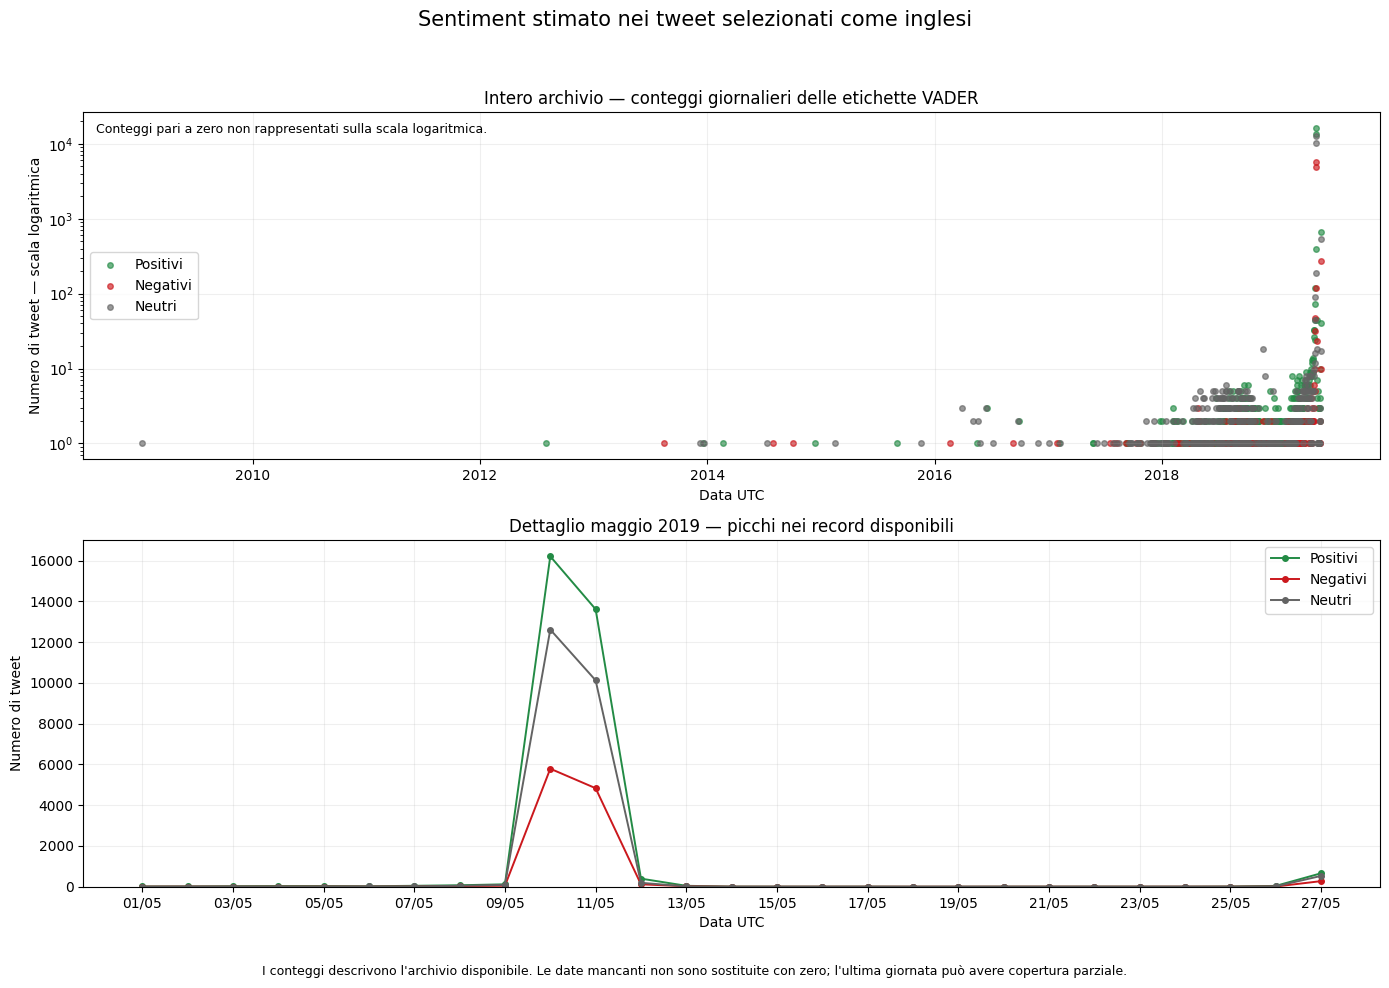

Grafico salvato in: /content/bitcoin_sentiment/figures/sentiment_giornaliero_v1.png


In [52]:
# BTC-C075 — Grafico dei conteggi giornalieri per sentiment

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import date, timedelta

# Solo dati già aggregati: nessun tweet individuale viene raccolto.
righe_giornaliere = (
    sentiment_giornaliero
    .orderBy("date_utc")
    .select("date_utc", "positivi", "negativi", "neutri")
    .collect()
)

serie = [
    ("positivi", "Positivi", "#238b45"),
    ("negativi", "Negativi", "#cb181d"),
    ("neutri", "Neutri", "#636363"),
]

fig, assi = plt.subplots(2, 1, figsize=(14, 10))

# Vista completa: non colleghiamo date lontane con linee.
for colonna, etichetta, colore in serie:
    punti = [
        (r["date_utc"], r[colonna])
        for r in righe_giornaliere
        if r[colonna] > 0
    ]
    assi[0].scatter(
        [p[0] for p in punti],
        [p[1] for p in punti],
        s=16,
        alpha=0.65,
        color=colore,
        label=etichetta
    )

assi[0].set_yscale("log")
assi[0].set_title(
    "Intero archivio — conteggi giornalieri delle etichette VADER"
)
assi[0].set_ylabel("Numero di tweet — scala logaritmica")
assi[0].set_xlabel("Data UTC")
assi[0].legend()
assi[0].grid(True, alpha=0.2)
assi[0].text(
    0.01, 0.97,
    "Conteggi pari a zero non rappresentati sulla scala logaritmica.",
    transform=assi[0].transAxes,
    va="top",
    fontsize=9
)

# Dettaglio: dal primo maggio all'ultima data disponibile.
inizio_dettaglio = date(2019, 5, 1)
fine_dettaglio = max(r["date_utc"] for r in righe_giornaliere)

calendario = [
    inizio_dettaglio + timedelta(days=i)
    for i in range((fine_dettaglio - inizio_dettaglio).days + 1)
]

dati_per_data = {
    r["date_utc"]: r
    for r in righe_giornaliere
    if inizio_dettaglio <= r["date_utc"] <= fine_dettaglio
}

for colonna, etichetta, colore in serie:
    valori = [
        dati_per_data[giorno][colonna]
        if giorno in dati_per_data else float("nan")
        for giorno in calendario
    ]
    assi[1].plot(
        calendario,
        valori,
        marker="o",
        markersize=4,
        linewidth=1.4,
        color=colore,
        label=etichetta
    )

assi[1].set_title(
    "Dettaglio maggio 2019 — picchi nei record disponibili"
)
assi[1].set_ylabel("Numero di tweet")
assi[1].set_xlabel("Data UTC")
assi[1].set_ylim(bottom=0)
assi[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
assi[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
assi[1].legend()
assi[1].grid(True, alpha=0.2)

fig.suptitle(
    "Sentiment stimato nei tweet selezionati come inglesi",
    fontsize=15
)
fig.text(
    0.5, 0.015,
    "I conteggi descrivono l'archivio disponibile. "
    "Le date mancanti non sono sostituite con zero; "
    "l'ultima giornata può avere copertura parziale.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.045, 1, 0.95])

FIGURES_DIR = DATA_DIR.parent / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

grafico_sentiment_path = FIGURES_DIR / "sentiment_giornaliero_v1.png"
fig.savefig(grafico_sentiment_path, dpi=160, bbox_inches="tight")

plt.show()
print(f"Grafico salvato in: {grafico_sentiment_path}")

<!-- BTC-C076 -->
### Interpretazione dell’andamento temporale

Il 10 e l’11 maggio 2019 concentrano 63.169 tweet, circa il 92,9%
del sottoinsieme selezionato come inglese.

Il 10 maggio si osservano 16.204 tweet classificati come positivi,
12.612 neutri e 5.788 negativi. L’11 maggio i conteggi scendono
rispettivamente a 13.610, 10.123 e 4.832.

Nonostante la diminuzione dei volumi, il saldo normalizzato rimane
simile: circa 0,301 il 10 maggio e 0,307 l’11 maggio.
Il calo dei conteggi non corrisponde quindi a un analogo peggioramento
del sentiment stimato.

Il 12 maggio il totale scende a 706 record. Il 27 maggio compare
un ulteriore aumento, con 1.464 record, comunque molto inferiore
ai due picchi principali.

Questi movimenti descrivono la copertura dell’archivio disponibile.
Senza informazioni sul processo di raccolta non è possibile
attribuirli con certezza a variazioni dell’attività complessiva
su Twitter o a specifici eventi di mercato.

Inoltre, 454 delle 501 giornate presenti contengono meno di 10 tweet:
le quote giornaliere basate su questi piccoli conteggi sono instabili.
Le giornate con pochi record non devono essere interpretate come
prova di scarso interesse pubblico.

In [53]:
# BTC-C077 — Engagement per classe di sentiment stimata

tweets_scored.createOrReplaceTempView("btc_tweets_classificati")

engagement_per_sentiment = spark.sql("""
    SELECT
        sentiment,
        COUNT(*) AS numero_tweet,

        AVG(likes_count) AS media_like,
        percentile_approx(likes_count, 0.5, 10000) AS mediana_like,
        MAX(likes_count) AS massimo_like,
        100.0 * SUM(CASE WHEN likes_count = 0 THEN 1 ELSE 0 END)
            / COUNT(*) AS percentuale_zero_like,

        AVG(replies_count) AS media_risposte,
        percentile_approx(replies_count, 0.5, 10000) AS mediana_risposte,
        MAX(replies_count) AS massimo_risposte,
        100.0 * SUM(CASE WHEN replies_count = 0 THEN 1 ELSE 0 END)
            / COUNT(*) AS percentuale_zero_risposte

    FROM btc_tweets_classificati
    GROUP BY sentiment
""").cache()

assert engagement_per_sentiment.agg(
    F.sum("numero_tweet")
).first()[0] == numero_record_en

print("=== Engagement per etichetta VADER ===")
print("Le mediane sono calcolate con un'approssimazione controllata.\n")

(
    engagement_per_sentiment
    .select(
        "sentiment",
        "numero_tweet",
        F.round("media_like", 3).alias("media_like"),
        "mediana_like",
        "massimo_like",
        F.round("percentuale_zero_like", 2).alias("percentuale_zero_like"),
        F.round("media_risposte", 3).alias("media_risposte"),
        "mediana_risposte",
        "massimo_risposte",
        F.round("percentuale_zero_risposte", 2)
            .alias("percentuale_zero_risposte")
    )
    .orderBy("sentiment")
    .show(truncate=False, vertical=True)
)

=== Engagement per etichetta VADER ===
Le mediane sono calcolate con un'approssimazione controllata.

-RECORD 0-----------------------------
 sentiment                 | negativo 
 numero_tweet              | 11341    
 media_like                | 12.118   
 mediana_like              | 0        
 massimo_like              | 5549     
 percentuale_zero_like     | 84.77    
 media_risposte            | 1.289    
 mediana_risposte          | 0        
 massimo_risposte          | 682      
 percentuale_zero_risposte | 90.49    
-RECORD 1-----------------------------
 sentiment                 | neutro   
 numero_tweet              | 24446    
 media_like                | 7.333    
 mediana_like              | 0        
 massimo_like              | 14470    
 percentuale_zero_like     | 88.08    
 media_risposte            | 0.667    
 mediana_risposte          | 0        
 massimo_risposte          | 790      
 percentuale_zero_risposte | 94.11    
-RECORD 2-----------------------------
 

In [54]:
# BTC-C078 — Concentrazione dell'engagement nei tweet più popolari

from pyspark.sql import functions as F
from pyspark.sql.window import Window

engagement_lungo = (
    tweets_scored
    .filter(F.col("sentiment").isin("positivo", "negativo"))
    .select(
        "sentiment",
        F.explode(
            F.array(
                F.struct(
                    F.lit("like").alias("metrica"),
                    F.col("likes_count").alias("valore")
                ),
                F.struct(
                    F.lit("risposte").alias("metrica"),
                    F.col("replies_count").alias("valore")
                )
            )
        ).alias("engagement")
    )
    .select("sentiment", "engagement.*")
)

gruppo = Window.partitionBy("sentiment", "metrica")
ordine = gruppo.orderBy(F.desc("valore"))

engagement_ordinato = (
    engagement_lungo
    .withColumn("numero_tweet", F.count("*").over(gruppo))
    .withColumn("posizione", F.row_number().over(ordine))
    .withColumn(
        "dimensione_top_1pct",
        F.ceil(F.col("numero_tweet") * F.lit(0.01)).cast("long")
    )
)

# A parità di valore, la scelta dei record non cambia
# la somma delle interazioni del gruppo selezionato.
concentrazione_engagement = (
    engagement_ordinato
    .groupBy("sentiment", "metrica")
    .agg(
        F.count("*").alias("numero_tweet"),
        F.max("dimensione_top_1pct").alias("tweet_nel_top_1pct"),
        F.sum("valore").alias("interazioni_totali"),
        F.sum(
            F.when(
                F.col("posizione") <= F.col("dimensione_top_1pct"),
                F.col("valore")
            ).otherwise(0)
        ).alias("interazioni_top_1pct"),
        F.percentile_approx("valore", 0.95, 10000).alias("percentile_95"),
        F.percentile_approx("valore", 0.99, 10000).alias("percentile_99")
    )
    .withColumn(
        "quota_interazioni_top_1pct",
        F.when(
            F.col("interazioni_totali") > 0,
            100.0 * F.col("interazioni_top_1pct")
            / F.col("interazioni_totali")
        )
    )
)

print("=== Concentrazione dell'engagement ===")
print("Il numero di tweet del top 1% è arrotondato per eccesso.")
print("La selezione è effettuata separatamente per like e risposte.\n")

(
    concentrazione_engagement
    .select(
        "sentiment",
        "metrica",
        "numero_tweet",
        "tweet_nel_top_1pct",
        "interazioni_totali",
        "interazioni_top_1pct",
        F.round("quota_interazioni_top_1pct", 2)
            .alias("percentuale_interazioni_top_1pct"),
        "percentile_95",
        "percentile_99"
    )
    .orderBy("metrica", "sentiment")
    .show(truncate=False, vertical=True)
)

=== Concentrazione dell'engagement ===
Il numero di tweet del top 1% è arrotondato per eccesso.
La selezione è effettuata separatamente per like e risposte.

-RECORD 0------------------------------------
 sentiment                        | negativo 
 metrica                          | like     
 numero_tweet                     | 11341    
 tweet_nel_top_1pct               | 114      
 interazioni_totali               | 137432   
 interazioni_top_1pct             | 90666    
 percentuale_interazioni_top_1pct | 65.97    
 percentile_95                    | 26       
 percentile_99                    | 238      
-RECORD 1------------------------------------
 sentiment                        | positivo 
 metrica                          | like     
 numero_tweet                     | 32187    
 tweet_nel_top_1pct               | 322      
 interazioni_totali               | 298842   
 interazioni_top_1pct             | 185377   
 percentuale_interazioni_top_1pct | 62.03    
 percentile_95

<!-- BTC-C079 -->
### Engagement: risultati e interpretazione

Il confronto riguarda 11.341 tweet classificati da VADER come negativi
e 32.187 classificati come positivi.

**I tweet negativi ricevono più like dei positivi?**

Sì, nel dataset analizzato la media è di 12,118 like per i negativi,
contro 9,285 per i positivi: circa il 30,5% in più.

**I tweet negativi ricevono più risposte dei positivi?**

No. La media è di 1,289 risposte per i negativi e 1,356 per i positivi:
circa il 4,9% in meno per i negativi.

### Distribuzione delle interazioni

La mediana è zero per entrambe le metriche e per entrambi i gruppi.
Le interazioni sono fortemente concentrate:

- Il top 1% dei tweet negativi raccoglie il 65,97% dei like
  e il 66,14% delle risposte del proprio gruppo.
- Il top 1% dei tweet positivi raccoglie il 62,03% dei like
  e il 73,66% delle risposte del proprio gruppo.

Il top 1% è selezionato separatamente per ciascuna metrica,
arrotondando per eccesso il numero di tweet.

Le medie risentono quindi della minoranza di contenuti con engagement
elevato e non descrivono il comportamento del tweet tipico.

### Limiti del confronto

I gruppi hanno numerosità diverse e dipendono da etichette automatiche
che hanno mostrato un accordo limitato con il riferimento manuale.
Le differenze osservate sono descrittive e non costituiscono
una dimostrazione di significatività statistica o di causalità.

Non sono controllati fattori come la popolarità degli autori,
il contenuto promozionale, la data di pubblicazione o il tempo
trascorso prima della rilevazione dei conteggi.

I risultati non permettono quindi di concludere che scrivere
un tweet negativo produca più like, né di formulare una strategia
di comunicazione basata soltanto sul sentiment.

In [55]:
# BTC-C080 — Download e prima ispezione dello storico BTC/USD

import csv
import hashlib
import json
from datetime import datetime, timezone
from urllib.request import Request, urlopen

BTC_PRICE_URL = (
    "https://raw.githubusercontent.com/Profession-AI/progetti-big-data/"
    "main/Analisi%20del%20consenso%20sul%20Bitcoin/BTC-USD.csv"
)

BTC_PRICE_PATH = DATA_DIR / "BTC-USD.csv"
BTC_PRICE_METADATA_PATH = DATA_DIR / "BTC-USD_metadata.json"

richiesta_prezzi = Request(
    BTC_PRICE_URL,
    headers={"User-Agent": "bitcoin-sentiment-project"}
)

with urlopen(richiesta_prezzi, timeout=60) as risposta:
    contenuto_prezzi = risposta.read()
    url_finale_prezzi = risposta.geturl()

assert contenuto_prezzi, "Il file scaricato è vuoto."

# Controlliamo che il contenuto sia leggibile come testo CSV.
testo_prezzi = contenuto_prezzi.decode("utf-8-sig")
lettore_prezzi = csv.reader(testo_prezzi.splitlines())
intestazione_prezzi = next(lettore_prezzi)

assert "Date" in intestazione_prezzi, (
    f"Intestazione inattesa: {intestazione_prezzi}"
)

prime_righe_prezzi = []
for indice, riga in enumerate(lettore_prezzi):
    if indice >= 5:
        break
    prime_righe_prezzi.append(riga)

BTC_PRICE_PATH.write_bytes(contenuto_prezzi)

metadata_prezzi = {
    "source_url": BTC_PRICE_URL,
    "resolved_url": url_finale_prezzi,
    "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
    "size_bytes": len(contenuto_prezzi),
    "sha256": hashlib.sha256(contenuto_prezzi).hexdigest(),
}

BTC_PRICE_METADATA_PATH.write_text(
    json.dumps(metadata_prezzi, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("=== Storico BTC/USD scaricato ===")
print(f"Percorso: {BTC_PRICE_PATH}")
print(f"Dimensione: {len(contenuto_prezzi):,} byte")
print(f"SHA-256: {metadata_prezzi['sha256']}")

print("\n=== Colonne presenti ===")
print(intestazione_prezzi)

print("\n=== Prime cinque righe del file ===")
for riga in prime_righe_prezzi:
    print(riga)

print(f"\nMetadati salvati in: {BTC_PRICE_METADATA_PATH}")

=== Storico BTC/USD scaricato ===
Percorso: /content/bitcoin_sentiment/data/BTC-USD.csv
Dimensione: 423,556 byte
SHA-256: acb4d4b2ca943e3b55d0be6b7bc96affdbcd17babce4472ca29878d63dae9a2e

=== Colonne presenti ===
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']

=== Prime cinque righe del file ===
['2014-09-17 00:00:00+00:00', '465.864013671875', '468.17401123046875', '452.4219970703125', '457.3340148925781', '21056800', '0.0', '0.0']
['2014-09-18 00:00:00+00:00', '456.8599853515625', '456.8599853515625', '413.10400390625', '424.44000244140625', '34483200', '0.0', '0.0']
['2014-09-19 00:00:00+00:00', '424.1029968261719', '427.8349914550781', '384.5320129394531', '394.7959899902344', '37919700', '0.0', '0.0']
['2014-09-20 00:00:00+00:00', '394.6730041503906', '423.2959899902344', '389.88299560546875', '408.90399169921875', '36863600', '0.0', '0.0']
['2014-09-21 00:00:00+00:00', '408.0849914550781', '412.4259948730469', '393.1809997558594', '398.82101440429

In [56]:
# BTC-C080A — Verifica della versione dello storico BTC/USD

import hashlib

BTC_PRICE_SHA256_ATTESO = (
    "acb4d4b2ca943e3b55d0be6b7bc96affdbcd17babce4472ca29878d63dae9a2e"
)

impronta_prezzi_verifica = hashlib.sha256()

with BTC_PRICE_PATH.open("rb") as file_prezzi_verifica:
    for blocco in iter(
        lambda: file_prezzi_verifica.read(1024 * 1024),
        b""
    ):
        impronta_prezzi_verifica.update(blocco)

prezzi_sha256_effettivo = impronta_prezzi_verifica.hexdigest()

if prezzi_sha256_effettivo != BTC_PRICE_SHA256_ATTESO:
    raise ValueError(
        "Lo storico BTC/USD è diverso dalla versione utilizzata "
        "per i risultati e le conclusioni di questo notebook.\n"
        f"SHA-256 atteso: {BTC_PRICE_SHA256_ATTESO}\n"
        f"SHA-256 rilevato: {prezzi_sha256_effettivo}\n"
        "Interrompere l'esecuzione e verificare la nuova versione "
        "prima di aggiornare analisi e conclusioni. "
        "Non sostituire automaticamente l'impronta attesa."
    )

print("=== Verifica della versione dei prezzi ===")
print(f"SHA-256: {prezzi_sha256_effettivo}")
print("Lo storico coincide con la versione utilizzata nell'analisi.")

=== Verifica della versione dei prezzi ===
SHA-256: acb4d4b2ca943e3b55d0be6b7bc96affdbcd17babce4472ca29878d63dae9a2e
Lo storico coincide con la versione utilizzata nell'analisi.


In [57]:
# BTC-C081 — Lettura e verifica dello storico BTC/USD con PySpark

from pyspark.sql import functions as F
from pyspark.sql.window import Window

schema_prezzi = """
    Date string,
    Open string,
    High string,
    Low string,
    Close string,
    Volume string,
    Dividends string,
    `Stock Splits` string,
    _corrupt_record string
"""

prezzi_raw = (
    spark.read
    .option("header", True)
    .option("mode", "PERMISSIVE")
    .option("columnNameOfCorruptRecord", "_corrupt_record")
    .option("enforceSchema", False)
    .schema(schema_prezzi)
    .csv(str(BTC_PRICE_PATH))
    .cache()
)

# Materializziamo la lettura prima dei controlli sui record malformati.
numero_righe_prezzi = prezzi_raw.count()
assert numero_righe_prezzi > 0, "Lo storico dei prezzi è vuoto."

prezzi_verifica = (
    prezzi_raw
    .withColumn(
        "price_timestamp_utc",
        F.expr("try_cast(`Date` AS TIMESTAMP)")
    )
    .withColumn("date_utc", F.to_date("price_timestamp_utc"))
    .withColumn(
        "close_usd",
        F.expr("try_cast(`Close` AS DOUBLE)")
    )
    .withColumn(
        "prezzo_non_valido",
        F.col("close_usd").isNull()
        | F.isnan("close_usd")
        | (F.abs(F.col("close_usd")) == F.lit(float("inf")))
        | (F.col("close_usd") <= 0)
    )
    .cache()
)

controlli_prezzi = prezzi_verifica.agg(
    F.count("*").alias("record_totali"),
    F.sum(
        F.when(F.col("_corrupt_record").isNotNull(), 1).otherwise(0)
    ).alias("record_malformati"),
    F.sum(
        F.when(F.col("date_utc").isNull(), 1).otherwise(0)
    ).alias("date_non_valide"),
    F.sum(
        F.when(F.col("prezzo_non_valido"), 1).otherwise(0)
    ).alias("chiusure_non_valide"),
    F.min("date_utc").alias("prima_data"),
    F.max("date_utc").alias("ultima_data"),
    F.countDistinct("date_utc").alias("giorni_distinti")
)

print("=== Qualità e copertura dello storico prezzi ===")
controlli_prezzi.show(truncate=False, vertical=True)

duplicati_date_prezzi = (
    prezzi_verifica
    .filter(F.col("date_utc").isNotNull())
    .groupBy("date_utc")
    .count()
    .filter(F.col("count") > 1)
)

print("=== Date duplicate — massimo 10 ===")
duplicati_date_prezzi.orderBy("date_utc").show(10, truncate=False)

# La continuità viene controllata sulle date presenti,
# indipendentemente dalla validità del prezzo.
date_distinte_prezzi = (
    prezzi_verifica
    .filter(F.col("date_utc").isNotNull())
    .select("date_utc")
    .distinct()
)

intervalli_prezzi = (
    date_distinte_prezzi
    .withColumn(
        "data_precedente",
        F.lag("date_utc").over(Window.orderBy("date_utc"))
    )
    .withColumn(
        "giorni_mancanti",
        F.datediff("date_utc", "data_precedente") - 1
    )
    .filter(F.col("giorni_mancanti") > 0)
)

print("=== Interruzioni nel calendario — massimo 10 ===")
intervalli_prezzi.orderBy("date_utc").show(10, truncate=False)

totale_giorni_mancanti = (
    intervalli_prezzi
    .agg(F.sum("giorni_mancanti").alias("totale"))
    .first()["totale"]
)
print(
    "Giorni mancanti tra la prima e l'ultima data dello storico:",
    totale_giorni_mancanti or 0
)

# Per il solo controllo di copertura consideriamo le date
# con almeno un record leggibile e una chiusura valida.
date_prezzi_validi = (
    prezzi_verifica
    .filter(
        F.col("_corrupt_record").isNull()
        & F.col("date_utc").isNotNull()
        & ~F.col("prezzo_non_valido")
    )
    .select("date_utc")
    .distinct()
)

copertura_prezzi_tweet = (
    sentiment_giornaliero
    .join(
        date_prezzi_validi.withColumn("prezzo_disponibile", F.lit(True)),
        on="date_utc",
        how="left"
    )
    .withColumn(
        "copertura",
        F.when(
            F.col("prezzo_disponibile").isNotNull(),
            "Con prezzo valido"
        ).otherwise("Senza prezzo valido")
    )
    .groupBy("copertura")
    .agg(
        F.count("*").alias("giorni"),
        F.sum("totale_tweet").alias("tweet")
    )
)

print("\n=== Sovrapposizione con le giornate dei tweet ===")
copertura_prezzi_tweet.orderBy("copertura").show(truncate=False)

print("=== Esempi di record problematici — massimo 5 ===")
(
    prezzi_verifica
    .filter(
        F.col("_corrupt_record").isNotNull()
        | F.col("date_utc").isNull()
        | F.col("prezzo_non_valido")
    )
    .select("Date", "Close", "_corrupt_record")
    .show(5, truncate=False)
)

=== Qualità e copertura dello storico prezzi ===
-RECORD 0-------------------------
 record_totali       | 3930       
 record_malformati   | 0          
 date_non_valide     | 0          
 chiusure_non_valide | 0          
 prima_data          | 2014-09-17 
 ultima_data         | 2025-06-20 
 giorni_distinti     | 3930       

=== Date duplicate — massimo 10 ===
+--------+-----+
|date_utc|count|
+--------+-----+
+--------+-----+

=== Interruzioni nel calendario — massimo 10 ===
+--------+---------------+---------------+
|date_utc|data_precedente|giorni_mancanti|
+--------+---------------+---------------+
+--------+---------------+---------------+

Giorni mancanti tra la prima e l'ultima data dello storico: 0

=== Sovrapposizione con le giornate dei tweet ===
+-------------------+------+-----+
|copertura          |giorni|tweet|
+-------------------+------+-----+
|Con prezzo valido  |492   |67965|
|Senza prezzo valido|9     |9    |
+-------------------+------+-----+

=== Esempi di recor

In [58]:
# BTC-C082 — Variazioni giornaliere e allineamento delle serie

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Confermiamo i controlli prima di utilizzare i prezzi.
assert prezzi_verifica.filter(
    F.col("_corrupt_record").isNotNull()
    | F.col("date_utc").isNull()
    | F.col("prezzo_non_valido")
).count() == 0

assert duplicati_date_prezzi.count() == 0

ordine_date = Window.orderBy("date_utc")

# Rendimenti calcolati sul calendario completo dei prezzi.
prezzi_giornalieri = (
    prezzi_verifica
    .select("date_utc", "close_usd")
    .withColumn(
        "data_prezzo_precedente",
        F.lag("date_utc").over(ordine_date)
    )
    .withColumn(
        "close_precedente",
        F.lag("close_usd").over(ordine_date)
    )
    .withColumn(
        "rendimento_btc_pct",
        F.when(
            F.datediff("date_utc", "data_prezzo_precedente") == 1,
            100.0 * (F.col("close_usd") / F.col("close_precedente") - 1)
        )
    )
)

# Variazione del sentiment solo fra giornate consecutive.
sentiment_con_variazioni = (
    sentiment_giornaliero
    .withColumn(
        "data_sentiment_precedente",
        F.lag("date_utc").over(ordine_date)
    )
    .withColumn(
        "saldo_precedente",
        F.lag("saldo_normalizzato").over(ordine_date)
    )
    .withColumn(
        "tweet_giorno_precedente",
        F.lag("totale_tweet").over(ordine_date)
    )
    .withColumn(
        "variazione_saldo",
        F.when(
            F.datediff("date_utc", "data_sentiment_precedente") == 1,
            F.col("saldo_normalizzato") - F.col("saldo_precedente")
        )
    )
)

serie_allineate = (
    sentiment_con_variazioni
    .join(
        prezzi_giornalieri.select(
            "date_utc", "close_usd", "rendimento_btc_pct"
        ),
        on="date_utc",
        how="inner"
    )
    .cache()
)

# Conserviamo tutte le giornate allineate.
# Per il confronto delle variazioni servono entrambi i valori.
confronto_variazioni = (
    serie_allineate
    .filter(
        F.col("variazione_saldo").isNotNull()
        & F.col("rendimento_btc_pct").isNotNull()
    )
    .cache()
)

assert serie_allineate.select("date_utc").distinct().count() == (
    serie_allineate.count()
)

print("=== Allineamento delle serie ===")
print(f"Giornate con sentiment e prezzo: {serie_allineate.count()}")
print(
    "Giornate con entrambe le variazioni giornaliere disponibili: "
    f"{confronto_variazioni.count()}"
)

print("\n=== Numerosità dei tweet nelle coppie di giorni confrontabili ===")
(
    confronto_variazioni
    .agg(
        F.sum(
            F.when(
                (F.col("totale_tweet") < 10)
                | (F.col("tweet_giorno_precedente") < 10),
                1
            ).otherwise(0)
        ).alias("coppie_con_almeno_un_giorno_sotto_10_tweet"),
        F.sum(
            F.when(
                (F.col("totale_tweet") >= 10)
                & (F.col("tweet_giorno_precedente") >= 10),
                1
            ).otherwise(0)
        ).alias("coppie_con_entrambi_i_giorni_almeno_10_tweet")
    )
    .show(truncate=False, vertical=True)
)

print("=== Dettaglio dal 7 al 13 maggio 2019 ===")
(
    serie_allineate
    .filter(
        F.col("date_utc").between("2019-05-07", "2019-05-13")
    )
    .orderBy("date_utc")
    .select(
        "date_utc",
        "totale_tweet",
        "tweet_giorno_precedente",
        F.round("saldo_normalizzato", 4).alias("saldo_normalizzato"),
        F.round("variazione_saldo", 4).alias("variazione_saldo"),
        F.round("close_usd", 2).alias("close_usd"),
        F.round("rendimento_btc_pct", 3).alias("rendimento_btc_pct")
    )
    .show(truncate=False)
)

=== Allineamento delle serie ===
Giornate con sentiment e prezzo: 492
Giornate con entrambe le variazioni giornaliere disponibili: 386

=== Numerosità dei tweet nelle coppie di giorni confrontabili ===
-RECORD 0-------------------------------------------
 coppie_con_almeno_un_giorno_sotto_10_tweet   | 358 
 coppie_con_entrambi_i_giorni_almeno_10_tweet | 28  

=== Dettaglio dal 7 al 13 maggio 2019 ===
+----------+------------+-----------------------+------------------+----------------+---------+------------------+
|date_utc  |totale_tweet|tweet_giorno_precedente|saldo_normalizzato|variazione_saldo|close_usd|rendimento_btc_pct|
+----------+------------+-----------------------+------------------+----------------+---------+------------------+
|2019-05-07|71          |41                     |0.4930            |0.0295          |5829.5   |1.439             |
|2019-05-08|149         |71                     |0.2685            |-0.2245         |5982.46  |2.624             |
|2019-05-09|256      

In [59]:
# BTC-C083 — Correlazioni contemporanee e sfalsate di un giorno

from pyspark.sql import functions as F

base_sentiment = confronto_variazioni.select(
    "date_utc",
    "variazione_saldo",
    "totale_tweet",
    "tweet_giorno_precedente"
)

rendimenti_per_data = prezzi_giornalieri.select(
    F.col("date_utc").alias("data_prezzo"),
    F.col("rendimento_btc_pct").alias("rendimento_confrontato")
)

scenari = [
    (-1, "Prezzo precedente: sentiment(t) vs prezzo(t-1)"),
    (0, "Stesso giorno: sentiment(t) vs prezzo(t)"),
    (1, "Prezzo successivo: sentiment(t) vs prezzo(t+1)"),
]

risultati_correlazioni = []

for scarto, descrizione in scenari:
    coppie = (
        base_sentiment
        .withColumn(
            "data_prezzo",
            F.date_add(F.col("date_utc"), scarto)
        )
        .join(rendimenti_per_data, on="data_prezzo", how="inner")
        .filter(F.col("rendimento_confrontato").isNotNull())
    )

    perimetri = [
        ("Tutte le coppie", coppie),
        (
            "Almeno 10 tweet in entrambi i giorni del sentiment",
            coppie.filter(
                (F.col("totale_tweet") >= 10)
                & (F.col("tweet_giorno_precedente") >= 10)
            )
        ),
    ]

    for nome_perimetro, dati in perimetri:
        risultato = (
            dati
            .agg(
                F.count("*").alias("numero_coppie"),
                F.min("date_utc").alias("prima_data_sentiment"),
                F.max("date_utc").alias("ultima_data_sentiment"),
                F.stddev_samp("variazione_saldo").alias("sd_sentiment"),
                F.stddev_samp("rendimento_confrontato").alias("sd_prezzo"),
                F.corr(
                    "variazione_saldo",
                    "rendimento_confrontato"
                ).alias("pearson")
            )
            .withColumn(
                "pearson",
                F.when(
                    (F.col("numero_coppie") >= 3)
                    & (F.col("sd_sentiment") > 0)
                    & (F.col("sd_prezzo") > 0),
                    F.col("pearson")
                )
            )
            .withColumn("perimetro", F.lit(nome_perimetro))
            .withColumn("confronto", F.lit(descrizione))
            .withColumn("scarto_giorni_prezzo", F.lit(scarto))
            .select(
                "perimetro",
                "confronto",
                "scarto_giorni_prezzo",
                "numero_coppie",
                "prima_data_sentiment",
                "ultima_data_sentiment",
                "pearson"
            )
        )

        risultati_correlazioni.append(risultato)

correlazioni_temporali = risultati_correlazioni[0]
for risultato in risultati_correlazioni[1:]:
    correlazioni_temporali = correlazioni_temporali.unionByName(risultato)

correlazioni_temporali = correlazioni_temporali.cache()

print("=== Correlazioni esplorative tra variazioni ===")
print("Sentiment: differenza giornaliera del saldo normalizzato.")
print("Prezzo: rendimento percentuale da chiusura a chiusura.")
print("Gli scarti indicano giorni di calendario, non righe del dataset.\n")

(
    correlazioni_temporali
    .withColumn("pearson", F.round("pearson", 4))
    .orderBy("perimetro", "scarto_giorni_prezzo")
    .show(6, truncate=False, vertical=True)
)

print(
    "Le correlazioni sono descrittive: non dimostrano causalità "
    "né capacità di previsione."
)

=== Correlazioni esplorative tra variazioni ===
Sentiment: differenza giornaliera del saldo normalizzato.
Prezzo: rendimento percentuale da chiusura a chiusura.
Gli scarti indicano giorni di calendario, non righe del dataset.

-RECORD 0-------------------------------------------------------------------
 perimetro             | Almeno 10 tweet in entrambi i giorni del sentiment 
 confronto             | Prezzo precedente: sentiment(t) vs prezzo(t-1)     
 scarto_giorni_prezzo  | -1                                                 
 numero_coppie         | 28                                                 
 prima_data_sentiment  | 2019-04-10                                         
 ultima_data_sentiment | 2019-05-27                                         
 pearson               | -0.0055                                            
-RECORD 1-------------------------------------------------------------------
 perimetro             | Almeno 10 tweet in entrambi i giorni del sentiment 
 co

<!-- BTC-C084 -->
### Relazione esplorativa tra sentiment e prezzo

La correlazione di Pearson fra variazione giornaliera del saldo
di sentiment e rendimento BTC/USD dello stesso giorno è 0,1252
su 386 coppie disponibili.

Le correlazioni con il rendimento del giorno precedente e del
giorno successivo sono rispettivamente −0,0234 e −0,0788.

Limitando il confronto alle 28 coppie con almeno 10 tweet in
entrambi i giorni utilizzati per calcolare la variazione del sentiment,
i valori sono rispettivamente:

- Prezzo del giorno precedente: −0,0055.
- Prezzo dello stesso giorno: 0,1222.
- Prezzo del giorno successivo: −0,0689.

Si osserva una debole associazione lineare positiva contemporanea
e associazioni vicine a zero negli allineamenti sfalsati di un giorno.

Questi risultati non forniscono evidenza convincente di una capacità
del sentiment di anticipare il prezzo, né del prezzo di anticipare
il sentiment. Non dimostrano tuttavia l'assenza di ogni possibile relazione.

Il confronto con la soglia di 10 tweet modifica anche il periodo
osservato: le 28 coppie sono comprese fra il 10 aprile e il 27 maggio 2019.
La somiglianza dei coefficienti è descrittiva e non costituisce
una validazione della loro stabilità statistica.

L'analisi non include test di significatività, correzioni per
dipendenza temporale o una verifica predittiva su dati futuri.
Le correlazioni non devono essere interpretate come effetti causali
o segnali operativi di investimento.

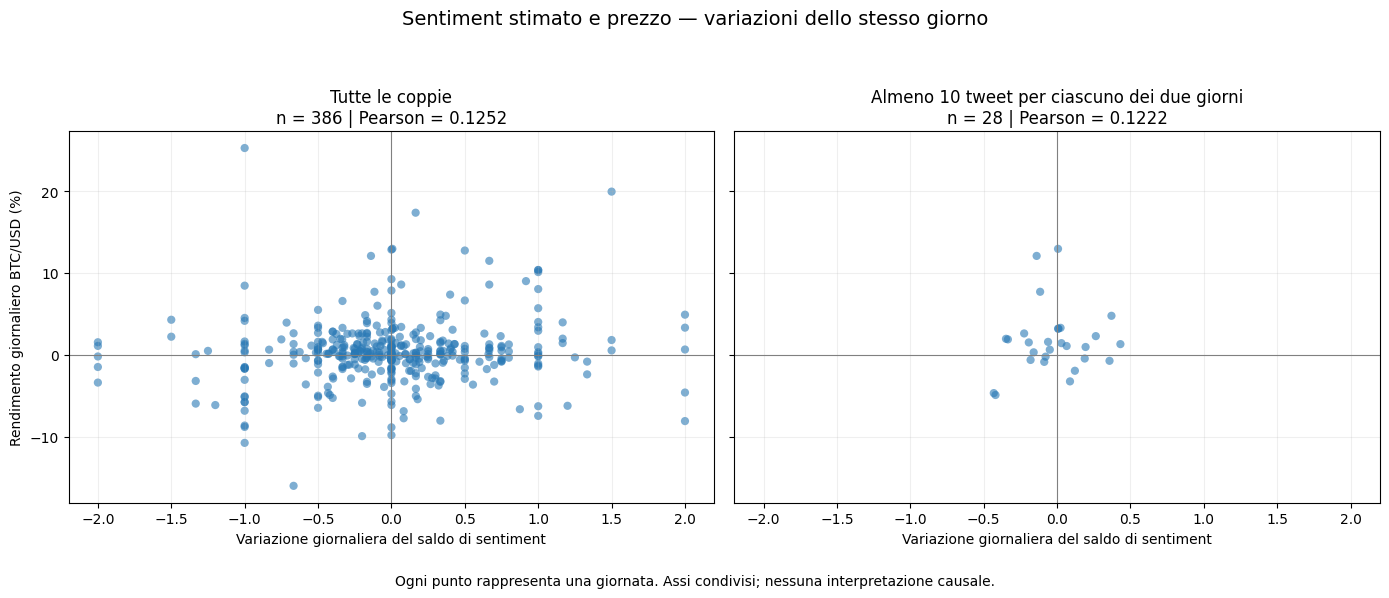

Grafico salvato in: /content/bitcoin_sentiment/figures/sentiment_prezzo_dispersione_v1.png


In [60]:
# BTC-C085 — Grafico delle variazioni contemporanee di sentiment e prezzo

import matplotlib.pyplot as plt

punti_confronto = (
    confronto_variazioni
    .select(
        "date_utc",
        "variazione_saldo",
        "rendimento_btc_pct",
        "totale_tweet",
        "tweet_giorno_precedente"
    )
    .orderBy("date_utc")
    .collect()
)

punti_soglia = [
    r for r in punti_confronto
    if r["totale_tweet"] >= 10
    and r["tweet_giorno_precedente"] >= 10
]

correlazioni_stesso_giorno = {
    r["perimetro"]: r["pearson"]
    for r in (
        correlazioni_temporali
        .filter(F.col("scarto_giorni_prezzo") == 0)
        .select("perimetro", "pearson")
        .collect()
    )
}

pannelli = [
    (
        punti_confronto,
        "Tutte le coppie",
        "Tutte le coppie"
    ),
    (
        punti_soglia,
        "Almeno 10 tweet in entrambi i giorni del sentiment",
        "Almeno 10 tweet per ciascuno dei due giorni"
    ),
]

fig, assi = plt.subplots(
    1, 2, figsize=(14, 6), sharex=True, sharey=True
)

for asse, (punti, chiave, titolo) in zip(assi, pannelli):
    asse.scatter(
        [r["variazione_saldo"] for r in punti],
        [r["rendimento_btc_pct"] for r in punti],
        color="#2878B5",
        alpha=0.6,
        s=35,
        edgecolors="none"
    )

    asse.axhline(0, color="gray", linewidth=0.8)
    asse.axvline(0, color="gray", linewidth=0.8)
    asse.grid(True, alpha=0.2)

    coefficiente = correlazioni_stesso_giorno[chiave]
    asse.set_title(
        f"{titolo}\n"
        f"n = {len(punti)} | Pearson = {coefficiente:.4f}"
    )
    asse.set_xlabel("Variazione giornaliera del saldo di sentiment")

assi[0].set_ylabel("Rendimento giornaliero BTC/USD (%)")

fig.suptitle(
    "Sentiment stimato e prezzo — variazioni dello stesso giorno",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "Ogni punto rappresenta una giornata. "
    "Assi condivisi; nessuna interpretazione causale.",
    ha="center",
    fontsize=10
)

fig.tight_layout(rect=[0, 0.06, 1, 0.93])

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
grafico_correlazione_path = (
    FIGURES_DIR / "sentiment_prezzo_dispersione_v1.png"
)

fig.savefig(grafico_correlazione_path, dpi=160, bbox_inches="tight")
plt.show()

print(f"Grafico salvato in: {grafico_correlazione_path}")

<!-- BTC-C086 -->
## Conclusioni

### Perimetro e qualità dei dati

Il file fornito contiene 100.001 record, anziché i milioni di tweet
descritti nello scenario progettuale. L'analisi riguarda i 67.974 record
riconosciuti automaticamente come inglesi, pari al 67,97% dell'archivio.

La copertura temporale è fortemente disomogenea: il 10 e l'11 maggio
2019 concentrano circa il 92,9% dei tweet selezionati.
Inoltre, 454 delle 501 giornate presenti hanno meno di 10 tweet.

I risultati descrivono questo archivio e non possono essere considerati
rappresentativi dell'intera conversazione pubblica su Bitcoin.

### Sentiment stimato

VADER classifica il 47,35% dei tweet come positivi, il 35,96% come
neutri e il 16,68% come negativi.

La verifica su 100 record annotati comprende 94 casi valutabili.
Su questi, l'accuracy è del 52,13% e il Macro-F1 è 0,504.
L'accordo limitato e le ambiguità del riferimento manuale impongono
cautela nell'interpretazione delle etichette.

Il tono generale di un tweet non coincide necessariamente con
un giudizio verso Bitcoin: messaggi promozionali, critiche alle
piattaforme e opinioni su altre criptovalute possono influenzarlo.

### Andamento giornaliero

I conteggi delle tre classi mostrano picchi comuni il 10 e l'11 maggio.
Il saldo normalizzato resta invece simile nei due giorni:
circa 0,301 e 0,307.

I picchi e i cali dei conteggi non dimostrano, da soli, variazioni
del consenso o dell'attività complessiva su Twitter.
Possono risentire della copertura e del processo di raccolta,
che non sono documentati in dettaglio.

### Engagement

I tweet classificati come negativi ricevono in media più like
dei positivi: 12,118 contro 9,285, circa il 30,5% in più.

Non ricevono invece più risposte: la media è 1,289 per i negativi
e 1,356 per i positivi, circa il 4,9% in meno.

La mediana è zero in entrambi i gruppi per entrambe le metriche.
Il top 1% dei tweet raccoglie tra il 62,03% e il 73,66% delle
interazioni, a seconda del gruppo e della metrica.
Le medie sono quindi fortemente influenzate da pochi contenuti.

Queste differenze sono descrittive: non dimostrano che il sentiment
causi maggiore engagement.

### Relazione con il prezzo BTC/USD

Lo storico dei prezzi permette di associare una chiusura a 492
giornate dell'archivio, comprendenti 67.965 tweet.
Sono disponibili 386 confronti fra variazioni giornaliere del
sentiment e del prezzo.

La correlazione contemporanea è debolmente positiva: 0,1252.
Le correlazioni con il rendimento del giorno precedente e successivo
sono vicine a zero: rispettivamente −0,0234 e −0,0788.

Considerando soltanto le 28 coppie con almeno 10 tweet in entrambi
i giorni del sentiment, i coefficienti rimangono contenuti.
Questo sottoinsieme copre però un periodo diverso e più breve.

L'analisi non fornisce evidenza convincente che il sentiment
anticipi il prezzo o lo segua. Non dimostra l'assenza di ogni
possibile relazione e non costituisce una verifica predittiva.

### Implicazioni di business

La pipeline consente di organizzare i dati, descrivere il tono
stimato delle conversazioni e individuare contenuti da approfondire.
Con i dati e il classificatore utilizzati, il suo impiego appropriato
è esplorativo, accompagnato da revisione dei testi.

Non è giustificato usare questi risultati come indicatore affidabile
del consenso pubblico, segnale di trading o prova che una comunicazione
negativa aumenti l'engagement.

Per sviluppare un monitoraggio più affidabile servirebbero:
una raccolta temporale più regolare e documentata, una valutazione
più ampia con annotatori indipendenti, e un modello capace di distinguere
il tono generale dal giudizio specificamente rivolto a Bitcoin.

### Limiti metodologici

- Selezione automatica della lingua, soggetta a errori.
- Copertura limitata ai tweet riconosciuti come inglesi.
- Forte concentrazione temporale e numerose giornate scarsamente osservate.
- Campione di valutazione piccolo, con casi ambigui e contenuti simili.
- Distinzione non sempre uniforme, nelle annotazioni, fra tono generale
  e giudizio rivolto a Bitcoin.
- Possibile presenza di bot, pubblicità e campagne coordinate,
  non identificati sistematicamente.
- Conteggi di engagement non corretti per popolarità degli autori
  o tempo trascorso dalla pubblicazione.
- Convenzione di chiusura dei prezzi non verificata oltre alle
  informazioni presenti nel file fornito.
- Correlazioni esplorative, senza test di significatività,
  correzioni per dipendenza temporale o validazione su dati futuri.

In [61]:
# BTC-C087 — Controlli conclusivi ed esportazione dei risultati

import shutil
import zipfile
from pyspark.sql import functions as F

# Controlli sui risultati principali.
assert tweets_scored.count() == numero_record_en
assert annotazioni_complete.count() == 100
assert valutazione_vader.count() == 94

assert sentiment_giornaliero.agg(
    F.sum("totale_tweet")
).first()[0] == numero_record_en

assert engagement_per_sentiment.agg(
    F.sum("numero_tweet")
).first()[0] == numero_record_en

assert serie_allineate.select("date_utc").distinct().count() == (
    serie_allineate.count()
)
assert correlazioni_temporali.count() == 6

# Aggiungiamo il testo originale ai due file di valutazione.
testi_per_export = (
    campione_annotazione
    .filter(F.col("sample_group") == "valutazione")
    .select("annotation_id", "text_original")
)

assert testi_per_export.count() == 100
assert testi_per_export.select("annotation_id").distinct().count() == 100

annotazioni_export = (
    annotazioni_complete
    .join(testi_per_export, on="annotation_id", how="left")
)

confronto_export = (
    confronto_annotazioni
    .join(testi_per_export, on="annotation_id", how="left")
)

for tabella in [annotazioni_export, confronto_export]:
    assert tabella.count() == 100
    assert tabella.filter(F.col("text_original").isNull()).count() == 0

EXPORT_DIR = DATA_DIR.parent / "risultati_finali_v1"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

tabelle_finali = {
    "annotazioni_manuali": (
        annotazioni_export.orderBy("sample_number")
    ),
    "confronto_annotazioni_vader": (
        confronto_export.orderBy("sample_number")
    ),
    "metriche_per_classe": metriche_per_classe.orderBy("classe"),
    "matrice_confusione": matrice_confusione.orderBy("manual_sentiment"),
    "sentiment_giornaliero": sentiment_giornaliero.orderBy("date_utc"),
    "engagement_per_sentiment": engagement_per_sentiment.orderBy("sentiment"),
    "concentrazione_engagement": (
        concentrazione_engagement.orderBy("metrica", "sentiment")
    ),
    "serie_sentiment_prezzi": serie_allineate.orderBy("date_utc"),
    "correlazioni_temporali": (
        correlazioni_temporali.orderBy("perimetro", "scarto_giorni_prezzo")
    ),
}

file_finali = []

# Tabelle piccole, già elaborate con Spark:
# un unico CSV per tabella, con gestione dei testi multilinea.
for nome, tabella in tabelle_finali.items():
    cartella_spark = EXPORT_DIR / f"_spark_{nome}"

    (
        tabella.coalesce(1)
        .write.mode("overwrite")
        .option("header", True)
        .option("encoding", "UTF-8")
        .option("quote", '"')
        .option("escape", '"')
        .csv(str(cartella_spark))
    )

    parti_csv = list(cartella_spark.glob("part-*.csv"))
    assert len(parti_csv) == 1, f"Esportazione inattesa per {nome}"

    destinazione = EXPORT_DIR / f"{nome}.csv"
    shutil.copy2(parti_csv[0], destinazione)
    file_finali.append(destinazione)

# Verifichiamo che i CSV con testo siano rileggibili.
for nome in ["annotazioni_manuali", "confronto_annotazioni_vader"]:
    verifica_csv = (
        spark.read
        .option("header", True)
        .option("multiLine", True)
        .option("quote", '"')
        .option("escape", '"')
        .option("mode", "FAILFAST")
        .csv(str(EXPORT_DIR / f"{nome}.csv"))
    )

    assert verifica_csv.count() == 100
    assert verifica_csv.filter(F.col("text_original").isNull()).count() == 0

# Copiamo i due grafici prodotti nel notebook.
grafici_finali = [
    FIGURES_DIR / "sentiment_giornaliero_v1.png",
    FIGURES_DIR / "sentiment_prezzo_dispersione_v1.png",
]

for percorso in grafici_finali:
    assert percorso.is_file(), f"Grafico mancante: {percorso}"
    destinazione = EXPORT_DIR / percorso.name
    shutil.copy2(percorso, destinazione)
    file_finali.append(destinazione)

# Metadati delle fonti e mappa verificata del campione.
for nome in [
    "bitcoin_tweets_metadata.json",
    "BTC-USD_metadata.json",
    "annotation_sample_manifest_v1.json",
]:
    percorso = DATA_DIR / nome
    assert percorso.is_file(), f"File mancante: {percorso}"
    destinazione = EXPORT_DIR / nome
    shutil.copy2(percorso, destinazione)
    file_finali.append(destinazione)

assert len(file_finali) == 14
assert len({p.name for p in file_finali}) == 14

ZIP_PATH = DATA_DIR.parent / "bitcoin_sentiment_risultati_v1.zip"

# Includiamo soltanto i file di questa esportazione,
# evitando eventuali file rimasti da esecuzioni precedenti.
with zipfile.ZipFile(
    ZIP_PATH, mode="w", compression=zipfile.ZIP_DEFLATED
) as archivio:
    for percorso in sorted(file_finali):
        archivio.write(percorso, arcname=percorso.name)

with zipfile.ZipFile(ZIP_PATH) as archivio:
    assert archivio.testzip() is None, "Archivio ZIP non integro."
    file_archiviati = archivio.namelist()
    assert len(file_archiviati) == 14

print("=== Controlli conclusivi ===")
print("Totali e coerenza delle tabelle: verificati.")
print("CSV di valutazione: 100 record ciascuno, con testo originale.")
print(f"Tabelle esportate: {len(tabelle_finali)}")
print(f"Grafici esportati: {len(grafici_finali)}")
print(f"File presenti nello ZIP: {len(file_archiviati)}")
print(f"Archivio: {ZIP_PATH}")

print("\n=== File esportati ===")
for nome in file_archiviati:
    print(nome)

# Download sul computer tramite Google Colab.
from google.colab import files
files.download(str(ZIP_PATH))

=== Controlli conclusivi ===
Totali e coerenza delle tabelle: verificati.
CSV di valutazione: 100 record ciascuno, con testo originale.
Tabelle esportate: 9
Grafici esportati: 2
File presenti nello ZIP: 14
Archivio: /content/bitcoin_sentiment/bitcoin_sentiment_risultati_v1.zip

=== File esportati ===
BTC-USD_metadata.json
annotation_sample_manifest_v1.json
annotazioni_manuali.csv
bitcoin_tweets_metadata.json
concentrazione_engagement.csv
confronto_annotazioni_vader.csv
correlazioni_temporali.csv
engagement_per_sentiment.csv
matrice_confusione.csv
metriche_per_classe.csv
sentiment_giornaliero.csv
sentiment_giornaliero_v1.png
sentiment_prezzo_dispersione_v1.png
serie_sentiment_prezzi.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>